# NYC Airbnb Market Intelligence (2019)
### What Really Drives the Price of a Short-Term Rental in New York City? A Statistical and Predictive Study of 48,000+ Listings

**Course:** 23CSE351 – Foundations of Data Science  |  **Case Study – Final Review**

**Department:** Computer Science and Engineering  |  **Academic Year:** 2026–2027

| Team Member | Register Number |
|---|---|
| K MIDUNRAJA | CB.SC.U4CSE24324 |
| V ROHAN REDDY  | CB.SC.U4CSE24359 |
| VARUN SHANKAR | CB.SC.U4CSE24345 |
| SANTHOSH V | CB.SC.U4CSE24047 |

**Deliverables:** Runnable Notebook · Case Study Report (.docx) · Presentation (.pptx) · Tableau Dataset (`outputs/NYC_Airbnb_Tableau_Data.csv`)

---

### Notebook Map

| Section | Content | Rubric |
|:---:|---|:---:|
| 1–2 | Problem Statement & Objectives | 1 |
| 3 | Dataset Description | 1 |
| 4 | Analysis Questions (Q1–Q18) with methods and course concepts | 2 |
| 5–6 | Library Imports, Statistical Helper Functions, Dataset Loading | 1 |
| 7 | Data Cleaning & Preprocessing (missing values, duplicates, invalid records, IQR outliers, feature engineering) | 3 |
| 8 | Exploratory Data Analysis | 4 |
| 9 | Analysis Questions Q1–Q16: Hypothesis Testing, A/B Tests, Probability & Linear-Algebra Concepts | 2 & 5 |
| 10 | Predictive Modelling Q17–Q18: Multiple Linear Regression, ML Benchmarks, Strategy Insights | 6 |
| 11 | Dashboard, Interactive Explorer & Clean Data Export (Tableau) | 7 |
| 12–16 | Key Findings, Conclusion, Limitations, Future Enhancements, References | 7 |

## 1. Problem Statement

New York City is the largest short-term rental market in the United States. Hosts choose a nightly price, a
room configuration, a minimum stay and an availability calendar; guests compare thousands of listings across five
boroughs; and the city regulates the sector through the Multiple Dwelling Law (minimum stays of **30 nights**).
Decisions in this market rest on widely repeated beliefs such as *"Manhattan is far more expensive than everywhere else"*,
*"the room type matters more than the neighbourhood"*, *"more reviews justify a higher price"*, or
*"most listings are run by professional multi-property hosts"*.

**This study tests those beliefs with data.** Using the **New York City Airbnb Open Data (2019)** we quantify what actually
determines the nightly price, how the supply side (room types, host portfolios, minimum stays, availability) is structured,
and we build a regression model that predicts a listing's price from information a host knows **before** the listing goes live.

## 2. Objectives

1. **Understand** the structure of the NYC Airbnb market: how borough, neighbourhood, room type, host portfolio, reviews and availability shape listings.
2. **Test** widely held beliefs with formal hypothesis tests (Welch t-tests, ANOVA / Kruskal–Wallis, chi-square tests of independence, two-proportion z-tests, binomial tests, correlation tests) and **A/B-style comparisons** (Entire home vs Private room, long-stay vs short-stay), reporting p-values **and** effect sizes, with a Holm correction for multiple testing.
3. **Apply Foundations-of-Data-Science concepts**: design matrices and covariance algebra, continuous Normal probability modelling, and an empirical verification of the Central Limit Theorem.
4. **Predict** nightly price with a multiple linear regression model, validate its assumptions (VIF, Breusch–Pagan, Durbin–Watson, normality), compare with machine-learning benchmarks (Ridge, Random Forest, Gradient Boosting) and translate the coefficients into pricing insights.
5. **Communicate** the findings through clear visualisations, an interactive dashboard and a Tableau-ready dataset.

## 3. Dataset Description

| Item | Details |
|---|---|
| **Source** | New York City Airbnb Open Data 2019 (public Kaggle/Inside Airbnb extract, `AB_NYC_2019.csv`; http://insideairbnb.com/get-the-data/) |
| **Coverage** | Active listings in all **5 NYC boroughs** (Manhattan, Brooklyn, Queens, Bronx, Staten Island), scraped in 2019 |
| **Format** | A single flat CSV file – one row per listing |
| **Size** | **48,895 raw records × 16 attributes** (reduced to ≈ 48,870 after validation, see Section 7) |
| **Target variable** | `price` (nightly price in USD) – modelled as `log_price = ln(1 + price_capped)` |

| Attribute | Type | Meaning |
|---|---|---|
| `id`, `host_id` | identifier | Listing and host identifiers |
| `name`, `host_name` | text | Listing title and host name |
| `neighbourhood_group` | categorical (5) | Borough |
| `neighbourhood` | categorical (≈ 220) | Neighbourhood |
| `latitude`, `longitude` | numeric | Geo-coordinates of the listing |
| `room_type` | categorical (3) | Entire home/apt · Private room · Shared room |
| `price` | numeric (USD) | **Nightly price** |
| `minimum_nights` | numeric | Minimum booking length |
| `number_of_reviews` | numeric | Lifetime review count |
| `last_review` | date | Date of most recent review |
| `reviews_per_month` | numeric | Review velocity |
| `calculated_host_listings_count` | numeric | Number of listings managed by the same host |
| `availability_365` | numeric | Days per year the listing is bookable |

## 4. Analysis Questions

The questions are grouped by the decision they inform. Each one specifies the statistical method and the underlying course concept from the **Lecture PPTs**.

| # | Theme | Analysis Question | Statistical Method (from PPTs) | Concept / Topic |
|:---:|:---|:---|:---|:---|
| **Q1** | Price structure | How are nightly prices distributed, and does a log-transformation fix the skew? | Skewness, Kurtosis, Q–Q plots, Normality test | Central tendency & shape (Lecture 9 & 10) |
| **Q2** | Geography | Do the five boroughs differ in price? | One-way / Welch ANOVA, Kruskal–Wallis, Tukey post-hoc, η² | Variance decomposition & ANOVA (Lecture 7 & 13) |
| **Q3** | Room type · **A/B Test** | Do Entire homes really cost more than Private rooms? | Two-sample Welch t-test, Mann–Whitney U, Cohen's d, bootstrap CI | A/B Testing & Two-sample t-test (Lecture 13 & 14) |
| **Q4** | Supply mix | Is room-type mix independent of borough? | Chi-square test of independence, Cramér's V, standardised residuals | Chi-square independence test (Lecture 13) |
| **Q5** | Neighbourhoods | Which neighbourhoods are the most expensive once small samples are controlled? | Sample-size threshold, bootstrap CI of the median, Kruskal–Wallis | Robust statistics & dispersion (Lecture 10 & 12) |
| **Q6** | Availability | Does a more available listing charge more or less? | Pearson / Spearman correlation, multiple regression controlling for confounders | Correlation & confounders (Lecture 2, 7 & 14) |
| **Q7** | Reviews | How strongly are cumulative reviews and review velocity related? | Correlation with Fisher-z confidence interval | Correlation (Lecture 2) |
| **Q8** | Regulation · **A/B Test** | Do room types differ in the share of ≥ 30-night (regulation-compliant) listings, and are long stays priced differently? | Two-proportion z-test, Welch t-test, Cohen's h / d | A/B Testing & Z-test (Lecture 12 & 13) |
| **Q9** | Host market structure | Is supply owned by single-property or commercial hosts, and how concentrated is it? | Exact binomial test, Lorenz curve & Gini, Kruskal–Wallis | Binomial distribution (Lecture 6 & 12) |
| **Q10** | Linear algebra | Is the covariance matrix of standardised features equal to the correlation matrix? | Design matrix, Gram matrix, Eigen-decomposition (PCA) | Matrix concepts & covariance |
| **Q11** | Probability | Can log-price be modelled by a Normal distribution to compute budget probabilities? | Normal PDF / CDF, Kolmogorov–Smirnov test | Continuous distributions (Lecture 6 & 11) |
| **Q12** | Sampling | Does the Central Limit Theorem hold for heavily skewed prices? | Sampling distribution, standard error, CI coverage simulation | Central Limit Theorem (Lecture 11 & 12) |
| **Q13** | Geography | How does price decay with distance from Midtown Manhattan? | Haversine distance, Spearman correlation, binned medians | Correlation & empirical distribution (Lecture 2 & 11) |
| **Q14** | Availability segmentation | Do dormant, part-time and year-round listings price differently? | Kruskal–Wallis, ε², cohort comparison | Group comparison (Lecture 13) |
| **Q15** | Reputation | Do heavily reviewed listings command a price premium? | Spearman, Kruskal–Wallis, regression with controls | Correlation vs causation (Lecture 14) |
| **Q16** | Data quality | How sensitive are conclusions to outliers (raw vs capped vs log price)? | Winsorisation, bootstrap CI, robustness of Welch t-test | Outliers & dispersion (Lecture 10) |
| **Q17** | **Regression / ML** | Can nightly price be predicted from pre-listing information? | Multiple Linear Regression (OLS) with residual diagnostics, Ridge, Random Forest, Gradient Boosting, cross-validation | Multiple Linear Regression (Lecture 1, 2, 3, 7 & 13) |
| **Q18** | **Prediction / Strategy** | Which factors matter most and what does the model imply for pricing? | Standardised coefficients, permutation importance, What-If simulations with prediction intervals | Regression & scenario prediction (Lecture 7, 8 & 14) |

---
## 5. Library Imports

> 📘 **Course Concepts:** Python setup for data science workflows (Lecture 1).

In [1]:
# -----------------------------------------------------------------------------
# 1. Standard libraries for data manipulation
# -----------------------------------------------------------------------------
import os
import json
import warnings
import urllib.request
from math import radians, sin, cos, asin, sqrt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# -----------------------------------------------------------------------------
# 2. Data visualisation libraries
# -----------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio

# -----------------------------------------------------------------------------
# 3. Statistical and Machine Learning libraries (Lectures 12, 13, 14)
# -----------------------------------------------------------------------------
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pio.renderers.default = 'plotly_mimetype+notebook_connected'

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

# --- Project-relative paths -------------------------------------------------
# The notebook lives in notebooks/ ; raw data sits in data/raw and every artefact
# (figures, tables, JSON) is written into outputs/ at the project root.
_PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.path.join(_PROJECT_ROOT, 'data', 'raw')
FIG_DIR  = os.path.join(_PROJECT_ROOT, 'outputs', 'figures')
OUT_DIR  = os.path.join(_PROJECT_ROOT, 'outputs')
for folder in (DATA_DIR, FIG_DIR, OUT_DIR):
    os.makedirs(folder, exist_ok=True)
print('Project root :', _PROJECT_ROOT)
print('Raw data dir :', DATA_DIR)
print('Figures dir  :', FIG_DIR)
print('Outputs dir  :', OUT_DIR)

BOROUGH_ORDER = ['Manhattan', 'Brooklyn', 'Queens', 'Bronx', 'Staten Island']
BOROUGH_COLORS = dict(zip(BOROUGH_ORDER, ['#FF5A5F', '#00A699', '#FC642D', '#8B5CF6', '#484848']))
ROOM_ORDER = ['Entire home/apt', 'Private room', 'Shared room']
ROOM_COLORS = dict(zip(ROOM_ORDER, ['#FF5A5F', '#00A699', '#FC642D']))
HOST_ORDER = ['Single (1)', 'Multi (2-5)', 'Commercial (6+)']
AB_RED, AB_TEAL, AB_GREY = '#FF5A5F', '#00A699', '#484848'

RES = {}   # key results register, exported to outputs/analysis_results.json in Section 11


def show(name):
    """Helper function to save and display Matplotlib plots cleanly."""
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def md_out(text):
    """Render a Markdown string whose numbers are computed from the data (no hard-coded results)."""
    display(Markdown(text.replace('$', r'\$')))


print('All libraries loaded successfully.')

Matplotlib is building the font cache; this may take a moment.


Project root : /Users/kmidunraja/Downloads/FODS_Final_Submission
Raw data dir : /Users/kmidunraja/Downloads/FODS_Final_Submission/data/raw
Figures dir  : /Users/kmidunraja/Downloads/FODS_Final_Submission/outputs/figures
Outputs dir  : /Users/kmidunraja/Downloads/FODS_Final_Submission/outputs
All libraries loaded successfully.


### Statistical Testing Helper Functions

> 📘 **Course Concepts:** Lecture 12 (Hypothesis Testing: Significance Level $\alpha = 0.05$, Decision Rule) and Lecture 13 (Effect Sizes).

In [2]:
ALPHA = 0.05
TESTS = []   # register of every formal test -> used for the Holm-corrected summary table

def verdict(p):
    """Decision Rule (Lecture 12): Reject H0 if p < alpha, else Fail to Reject H0."""
    return 'Reject H0' if p < ALPHA else 'Fail to reject H0'

def fmt_p(p):
    return '< 1e-300' if p < 1e-300 else f'{p:.3g}'

def magnitude(value, small, medium, large):
    """Label practical effect size magnitude (Lecture 13)."""
    v = abs(value)
    return 'negligible' if v < small else 'small' if v < medium else 'medium' if v < large else 'large'

def cohen_d(a, b):
    """Standardised difference between two group means (two-sample t-test effect size)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

def cohen_h(p1, p2):
    """Effect size for the difference between two proportions."""
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))

def cramers_v(table):
    """Association strength for a chi-square contingency table."""
    chi2 = stats.chi2_contingency(table)[0]
    n = np.asarray(table).sum()
    return np.sqrt(chi2 / (n * (min(np.shape(table)) - 1)))

def rank_biserial(u, n1, n2):
    """Rank-biserial correlation for a Mann-Whitney U test (positive = group 1 larger)."""
    return 2 * u / (n1 * n2) - 1

def eta_squared(groups):
    """Share of total variance explained by group membership (ANOVA effect size)."""
    allv = np.concatenate(groups)
    gm = allv.mean()
    ss_b = sum(len(g) * (g.mean() - gm) ** 2 for g in groups)
    return ss_b / ((allv - gm) ** 2).sum()

def epsilon_squared(h_stat, n):
    """Effect size for the Kruskal-Wallis H statistic."""
    return h_stat / (n - 1) if n > 1 else np.nan

def wilson(k, n):
    """Wilson score confidence interval for a proportion."""
    return proportion_confint(k, n, alpha=ALPHA, method='wilson')

def bootstrap_ci(x, stat=np.median, n_boot=2000, seed=SEED):
    """Percentile bootstrap 95% confidence interval for any statistic."""
    r = np.random.default_rng(seed)
    x = np.asarray(x, float)
    boots = np.array([stat(r.choice(x, len(x), replace=True)) for _ in range(n_boot)])
    return np.percentile(boots, [2.5, 97.5])

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in kilometres (vectorised)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))

def gini(x):
    """Gini coefficient of a non-negative array (0 = perfect equality, 1 = one owner holds everything)."""
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return (2 * np.sum((np.arange(1, n + 1)) * x) / (n * x.sum())) - (n + 1) / n

def report(qid, hypothesis, test_name, statistic, p, effect_name, effect, effect_label, log=True):
    """Formatted test reporting with statistic, p-value, decision and effect size; optionally logs to the test register."""
    print(f'{test_name}: statistic = {statistic:,.3f},  p-value = {fmt_p(p)}  ->  {verdict(p)}')
    print(f'Effect size ({effect_name}) = {effect:.3f}  ->  {effect_label}')
    if log:
        TESTS.append({'Question': qid, 'Hypothesis': hypothesis, 'Test': test_name, 'Statistic': statistic,
                      'p-value': p, 'Effect size': effect_name, 'Effect value': effect, 'Magnitude': effect_label})

print('Statistical toolkit ready.')

Statistical toolkit ready.


---
## 6. Dataset Loading and Overview

> 📘 **Rubric 1 & Course Concept:** Real-world dataset identified (> 500 records) (Lecture 8).

The CSV is read from `data/AB_NYC_2019.csv`. If the file is not present it is downloaded once from the public mirror, so the notebook runs end-to-end on a fresh machine.

In [3]:
DATA_PATH = f'{DATA_DIR}/AB_NYC_2019.csv'
DATA_URL = 'https://raw.githubusercontent.com/alexeygrigorev/datasets/master/AB_NYC_2019.csv'

if not os.path.exists(DATA_PATH):
    print('Downloading dataset from the public repository ...')
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print(f'Raw dataset: {raw.shape[0]:,} rows x {raw.shape[1]} columns')

schema = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'missing %': (raw.isna().mean() * 100).round(2),
    'unique values': raw.nunique(),
})
schema

Raw dataset: 48,895 rows x 16 columns


,dtype,missing,missing %,unique values
id,int64,0,0.00,48895
name,str,16,0.03,47905
host_id,int64,0,0.00,37457
host_name,str,21,0.04,11452
neighbourhood_group,str,0,0.00,5
neighbourhood,str,0,0.00,221
latitude,float64,0,0.00,19048
longitude,float64,0,0.00,14718
room_type,str,0,0.00,3
price,int64,0,0.00,674


In [4]:
raw.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## 7. Data Cleaning and Preprocessing

> 📘 **Rubric 3 & Course Concepts:** Lecture 8 (Data Preprocessing: handling missing values, duplicates, invalid records) and Lecture 10 (IQR outlier detection).

The pipeline is documented step by step. Every decision is justified, and a cleaning log records how many rows each step touches.

### 7.1 Duplicates and Missing Values

In [5]:
df = raw.copy()
clean_log = [('Raw records', len(df), '-')]

# --- Duplicates ---------------------------------------------------------------
print('Fully duplicated rows :', df.duplicated().sum())
print('Duplicated listing ids :', df['id'].duplicated().sum())

# --- Missing values: diagnose the mechanism BEFORE deciding how to treat them --
rpm_missing = df['reviews_per_month'].isna()
lr_missing = df['last_review'].isna()
print('\nreviews_per_month missing AND number_of_reviews == 0 :',
      f"{(df.loc[rpm_missing, 'number_of_reviews'] == 0).mean():.0%} of the {rpm_missing.sum():,} missing rows")
print('last_review missing AND number_of_reviews == 0       :',
      f"{(df.loc[lr_missing, 'number_of_reviews'] == 0).mean():.0%} of the {lr_missing.sum():,} missing rows")

missing_summary = pd.DataFrame({
    'missing': df.isna().sum(),
    'percent': (df.isna().mean() * 100).round(2),
    'reason / treatment': pd.Series({
        'name': 'Random omission by host -> fill with "Unknown Listing"',
        'host_name': 'Random omission by host -> fill with "Unknown Host"',
        'last_review': 'Structural: no review exists -> kept as NaT, flag has_reviews added',
        'reviews_per_month': 'Structural: 0 reviews -> true rate is 0, imputed with 0.0',
    })
}).fillna('-')
missing_summary[missing_summary['missing'] > 0]

Fully duplicated rows : 0
Duplicated listing ids : 0

reviews_per_month missing AND number_of_reviews == 0 : 100% of the 10,052 missing rows
last_review missing AND number_of_reviews == 0       : 100% of the 10,052 missing rows


,missing,percent,reason / treatment
host_name,21,0.04,"Random omission by host -> fill with ""Unknown ..."
last_review,10052,20.56,"Structural: no review exists -> kept as NaT, f..."
name,16,0.03,"Random omission by host -> fill with ""Unknown ..."
reviews_per_month,10052,20.56,"Structural: 0 reviews -> true rate is 0, imput..."


In [6]:
# Treatment of structural / random missingness (Lecture 8)
df['reviews_per_month'] = df['reviews_per_month'].fillna(0.0)
df['name'] = df['name'].fillna('Unknown Listing')
df['host_name'] = df['host_name'].fillna('Unknown Host')
df['last_review'] = pd.to_datetime(df['last_review'])
df['has_reviews'] = df['number_of_reviews'] > 0

print('Remaining missing values (excluding the structural last_review):')
print(df.drop(columns='last_review').isna().sum().loc[lambda s: s > 0] if df.drop(columns='last_review').isna().any().any() else 'None')

Remaining missing values (excluding the structural last_review):
None


### 7.2 Invalid Records and Plausibility Filters

In [7]:
n_zero_price = int((df['price'] <= 0).sum())
n_long_stay = int((df['minimum_nights'] > 365).sum())

df = df[df['price'] > 0]
clean_log.append(('Removed non-paying listings (price = 0)', len(df), f'-{n_zero_price}'))
df = df[df['minimum_nights'] <= 365].copy()
clean_log.append(('Removed unrealistic stays (minimum_nights > 365)', len(df), f'-{n_long_stay}'))

# Geographic plausibility: every listing must lie inside the NYC bounding box
outside = ~(df['latitude'].between(40.4, 41.0) & df['longitude'].between(-74.3, -73.6))
print(f'Listings outside the NYC bounding box: {outside.sum()}')
print(f"Price range after filtering: ${df['price'].min():,.0f} - ${df['price'].max():,.0f}")
print(f"Valid room types : {sorted(df['room_type'].unique())}")
print(f"Valid boroughs   : {sorted(df['neighbourhood_group'].unique())}")

pd.DataFrame(clean_log, columns=['Step', 'Rows remaining', 'Change'])

Listings outside the NYC bounding box: 0
Price range after filtering: $10 - $10,000
Valid room types : ['Entire home/apt', 'Private room', 'Shared room']
Valid boroughs   : ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']


,Step,Rows remaining,Change
0,Raw records,48895,-
1,Removed non-paying listings (price = 0),48884,-11
2,Removed unrealistic stays (minimum_nights > 365),48870,-14


### 7.3 Outlier Analysis: Interquartile Range (IQR) & Boxplots

> 📘 **Rubric 3 & Course Concept:** Lecture 10 (Measure of Dispersion: IQR and outlier detection).

Outliers are flagged with Tukey's rule (below $Q_1 - 1.5\,IQR$ or above $Q_3 + 1.5\,IQR$). Whether a flagged value is an *error* or a *genuine extreme* decides the treatment.

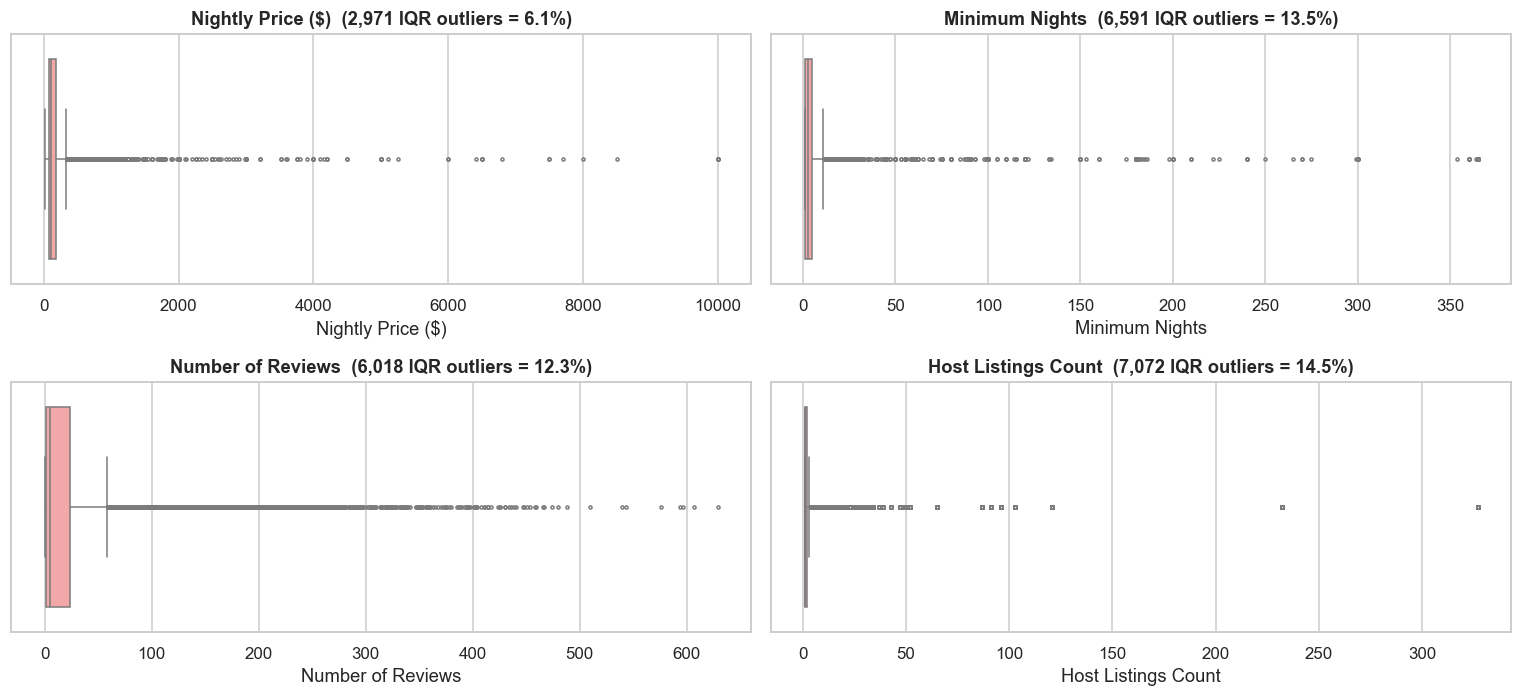

,Variable,Q1,Q3,IQR,Upper fence,Outliers,Outlier %,Max
0,price,69.0,175.0,106.0,334.0,2971,6.08,10000
1,minimum_nights,1.0,5.0,4.0,11.0,6591,13.49,365
2,number_of_reviews,1.0,24.0,23.0,58.5,6018,12.31,629
3,calculated_host_listings_count,1.0,2.0,1.0,3.5,7072,14.47,327


In [8]:
check_cols = [('price', 'Nightly Price ($)'), ('minimum_nights', 'Minimum Nights'),
              ('number_of_reviews', 'Number of Reviews'), ('calculated_host_listings_count', 'Host Listings Count')]

fig, axes = plt.subplots(2, 2, figsize=(14, 6.5))
iqr_rows = []
for ax, (col, label) in zip(axes.flat, check_cols):
    sns.boxplot(x=df[col], ax=ax, color='#FF9A9D', fliersize=2)
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    ax.set_title(f'{label}  ({n_out:,} IQR outliers = {n_out / len(df):.1%})')
    ax.set_xlabel(label)
    iqr_rows.append({'Variable': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr, 'Upper fence': high,
                     'Outliers': n_out, 'Outlier %': round(n_out / len(df) * 100, 2), 'Max': df[col].max()})
plt.tight_layout()
show('outliers_iqr')

pd.DataFrame(iqr_rows).round(2)

**Decision on outliers.** The price fence flags about 6 % of listings (13–14 % for stay length, reviews and host portfolio, which are naturally heavy-tailed), but the values are *genuine* luxury listings, not errors (they are real, bookable
properties), so they are **not deleted**. Instead the target is **winsorised at the 99th percentile** (`price_capped`) to remove leverage
points while keeping 99 % of the exact values, and **log-transformed** to stabilise variance. The extreme `minimum_nights` and host-count values are
retained because they describe real commercial behaviour that Q8 and Q9 analyse.

### 7.4 Feature Engineering (Lecture 8)

In [9]:
# Outlier treatment of the target
price_cap = float(df['price'].quantile(0.99))
df['price_capped'] = df['price'].clip(upper=price_cap)
df['log_price'] = np.log1p(df['price_capped'])

# Host portfolio type
df['host_type'] = pd.cut(df['calculated_host_listings_count'], bins=[0, 1, 5, np.inf],
                         labels=HOST_ORDER).astype(str)

# Availability cohort
df['availability_cohort'] = pd.cut(df['availability_365'], bins=[-1, 0, 299, 365],
                                   labels=['Dormant (0 d)', 'Part-time (1-299 d)', 'Year-round (300+ d)']).astype(str)
COHORT_ORDER = ['Dormant (0 d)', 'Part-time (1-299 d)', 'Year-round (300+ d)']

# Review-volume group
df['review_group'] = pd.cut(df['number_of_reviews'], bins=[-1, 0, 5, 25, np.inf],
                            labels=['None (0)', 'Low (1-5)', 'Medium (6-25)', 'High (26+)']).astype(str)
REVIEW_ORDER = ['None (0)', 'Low (1-5)', 'Medium (6-25)', 'High (26+)']

# Regulatory flag: NYC Multiple Dwelling Law treats stays of 30+ nights as legal long-term rentals
df['long_stay'] = df['minimum_nights'] >= 30

# Distance to Midtown Manhattan (Times Square) in km
TIMES_SQ = (40.7580, -73.9855)
df['dist_center_km'] = haversine_km(df['latitude'], df['longitude'], *TIMES_SQ)

print('Feature engineering complete.')
print(f'Final analytical dataset: {len(df):,} listings x {df.shape[1]} columns')
print(f'99th-percentile price cap: ${price_cap:,.0f}  ({(df["price"] > price_cap).sum():,} listings capped)')
print('\nGroup sizes:')
for col in ['host_type', 'availability_cohort', 'review_group']:
    print(f'  {col:<20}', df[col].value_counts().to_dict())
df[['price', 'price_capped', 'log_price', 'host_type', 'availability_cohort', 'review_group', 'long_stay', 'dist_center_km']].head()

Feature engineering complete.
Final analytical dataset: 48,870 listings x 24 columns
99th-percentile price cap: $799  (474 listings capped)

Group sizes:
  host_type            {'Single (1)': 32288, 'Multi (2-5)': 11792, 'Commercial (6+)': 4790}
  availability_cohort  {'Part-time (1-299 d)': 23184, 'Dormant (0 d)': 17530, 'Year-round (300+ d)': 8156}
  review_group         {'Low (1-5)': 14835, 'Medium (6-25)': 12380, 'High (26+)': 11612, 'None (0)': 10043}


,price,price_capped,log_price,host_type,availability_cohort,review_group,long_stay,dist_center_km
0,149,149,5.010635,Commercial (6+),Year-round (300+ d),Medium (6-25),False,12.337915
1,225,225,5.420535,Multi (2-5),Year-round (300+ d),High (26+),False,0.508366
2,150,150,5.017280,Single (1),Year-round (300+ d),None (0),False,6.757250
3,89,89,4.499810,Single (1),Part-time (1-299 d),High (26+),False,8.387046
4,80,80,4.394449,Single (1),Dormant (0 d),Medium (6-25),False,5.701504


In [10]:
RES['n_raw'] = int(len(raw))
RES['n_clean'] = int(len(df))
RES['price_cap'] = price_cap
clean_summary = pd.DataFrame(clean_log, columns=['Step', 'Rows remaining', 'Change'])
md_out(f"**Cleaning outcome:** {len(raw):,} raw records -> **{len(df):,} analytical records** "
       f"({len(raw) - len(df)} invalid rows removed, {(len(raw) - len(df)) / len(raw):.2%}).")

**Cleaning outcome:** 48,895 raw records -> **48,870 analytical records** (25 invalid rows removed, 0.05%).

### 7.5 Analytical Table & Summary Statistics (Lecture 8 & 9)

In [11]:
num_cols_desc = ['price', 'price_capped', 'log_price', 'minimum_nights', 'number_of_reviews',
                 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'dist_center_km']
desc = df[num_cols_desc].describe().T
desc['skew'] = df[num_cols_desc].skew()
desc['kurtosis'] = df[num_cols_desc].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
price,48870.0,152.76,240.20,10.00,69.00,106.00,175.00,10000.00,19.12,585.52
price_capped,48870.0,143.99,121.94,10.00,69.00,106.00,175.00,799.00,2.78,10.15
log_price,48870.0,4.73,0.67,2.40,4.25,4.67,5.17,6.68,0.37,0.01
minimum_nights,48870.0,6.84,16.45,1.00,1.00,3.00,5.00,365.00,11.62,206.50
number_of_reviews,48870.0,23.28,44.56,0.00,1.00,5.00,24.00,629.00,3.69,19.53
reviews_per_month,48870.0,1.09,1.60,0.00,0.04,0.37,1.58,58.50,3.30,43.54
calculated_host_listings_count,48870.0,7.15,32.96,1.00,1.00,1.00,2.00,327.00,7.93,67.51
availability_365,48870.0,112.73,131.60,0.00,0.00,45.00,227.00,365.00,0.76,-1.00
dist_center_km,48870.0,7.11,4.44,0.07,3.82,6.39,9.42,35.90,1.04,1.76


In [12]:
print(f"Total Listings         : {len(df):,}")
print(f"Total Unique Hosts     : {df['host_id'].nunique():,}")
print(f"Total Neighbourhoods   : {df['neighbourhood'].nunique():,}")
print(f"Total Boroughs         : {df['neighbourhood_group'].nunique()}")
print(f"Total Room Types       : {df['room_type'].nunique()}")

df.groupby('neighbourhood_group').agg(listings=('id', 'count'), hosts=('host_id', 'nunique'),
                                      median_price=('price', 'median')).loc[BOROUGH_ORDER]

Total Listings         : 48,870
Total Unique Hosts     : 37,442
Total Neighbourhoods   : 221
Total Boroughs         : 5
Total Room Types       : 3


,listings,hosts,median_price
neighbourhood_group,,,
Manhattan,21654,16571,150.0
Brooklyn,20089,15960,90.0
Queens,5664,3981,75.0
Bronx,1090,789,65.0
Staten Island,373,256,75.0


---
## 8. Exploratory Data Analysis (EDA)

> 📘 **Rubric 4 & Course Concepts:** Lectures 9 & 10 (Measures of Central Tendency, Spread, and Visual Explorations).

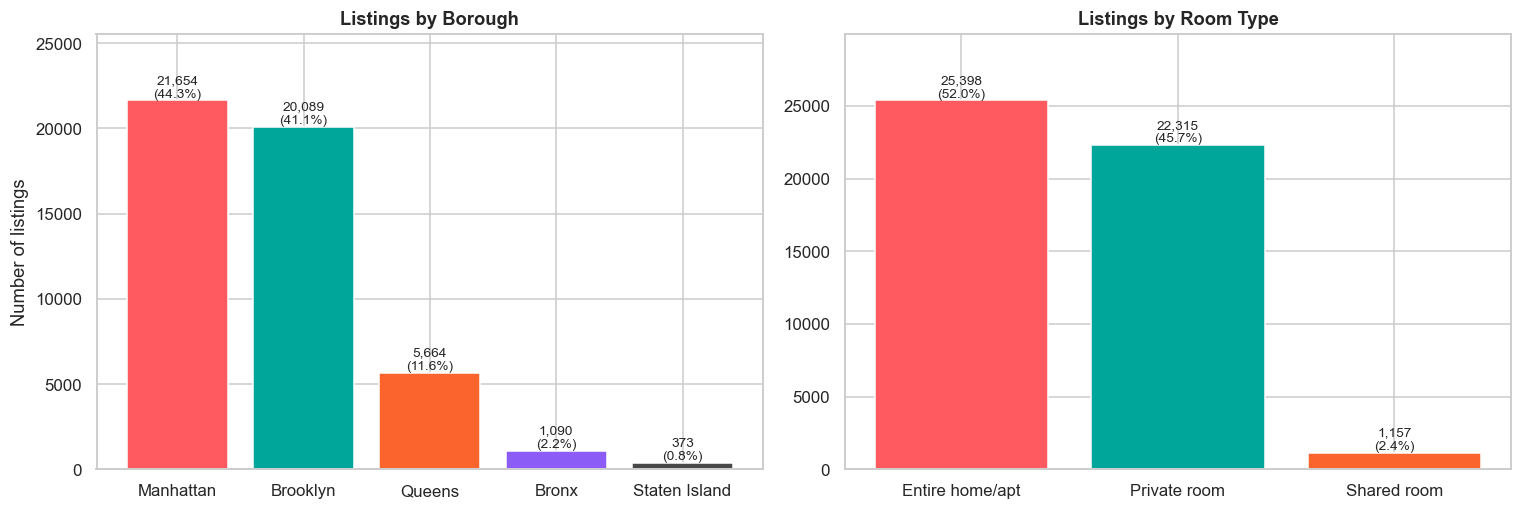

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

b_counts = df['neighbourhood_group'].value_counts().loc[BOROUGH_ORDER]
axes[0].bar(b_counts.index, b_counts.values, color=[BOROUGH_COLORS[b] for b in b_counts.index])
for i, v in enumerate(b_counts.values):
    axes[0].text(i, v, f'{v:,}\n({v / len(df):.1%})', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Listings by Borough')
axes[0].set_ylabel('Number of listings')
axes[0].set_ylim(0, b_counts.max() * 1.18)

r_counts = df['room_type'].value_counts().loc[ROOM_ORDER]
axes[1].bar(r_counts.index, r_counts.values, color=[ROOM_COLORS[r] for r in r_counts.index])
for i, v in enumerate(r_counts.values):
    axes[1].text(i, v, f'{v:,}\n({v / len(df):.1%})', ha='center', va='bottom', fontsize=9)
axes[1].set_title('Listings by Room Type')
axes[1].set_ylim(0, r_counts.max() * 1.18)

plt.tight_layout()
show('eda_counts')

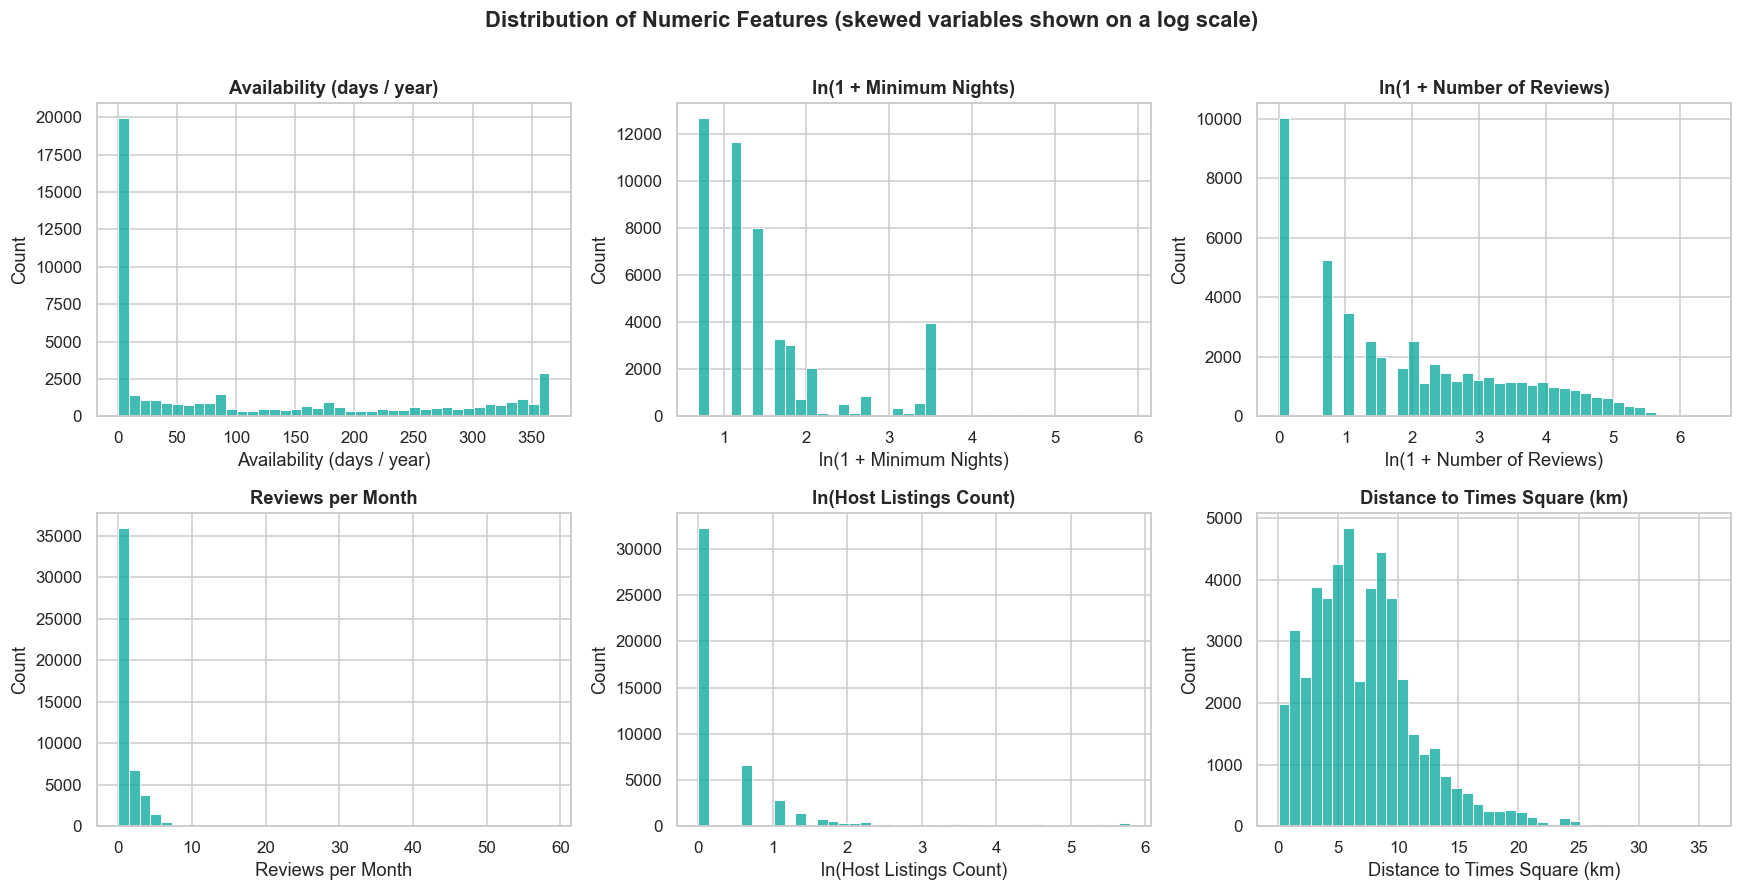

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
panels = [
    ('availability_365', df['availability_365'], 'Availability (days / year)'),
    ('minimum_nights', np.log1p(df['minimum_nights']), 'ln(1 + Minimum Nights)'),
    ('number_of_reviews', np.log1p(df['number_of_reviews']), 'ln(1 + Number of Reviews)'),
    ('reviews_per_month', df['reviews_per_month'], 'Reviews per Month'),
    ('host_listings', np.log(df['calculated_host_listings_count']), 'ln(Host Listings Count)'),
    ('dist_center_km', df['dist_center_km'], 'Distance to Times Square (km)'),
]
for ax, (name, series, label) in zip(axes.flat, panels):
    sns.histplot(series, bins=40, color=AB_TEAL, ax=ax)
    ax.set_title(label)
    ax.set_xlabel(label)
plt.suptitle('Distribution of Numeric Features (skewed variables shown on a log scale)', fontweight='bold', y=1.01)
plt.tight_layout()
show('eda_numeric_distributions')

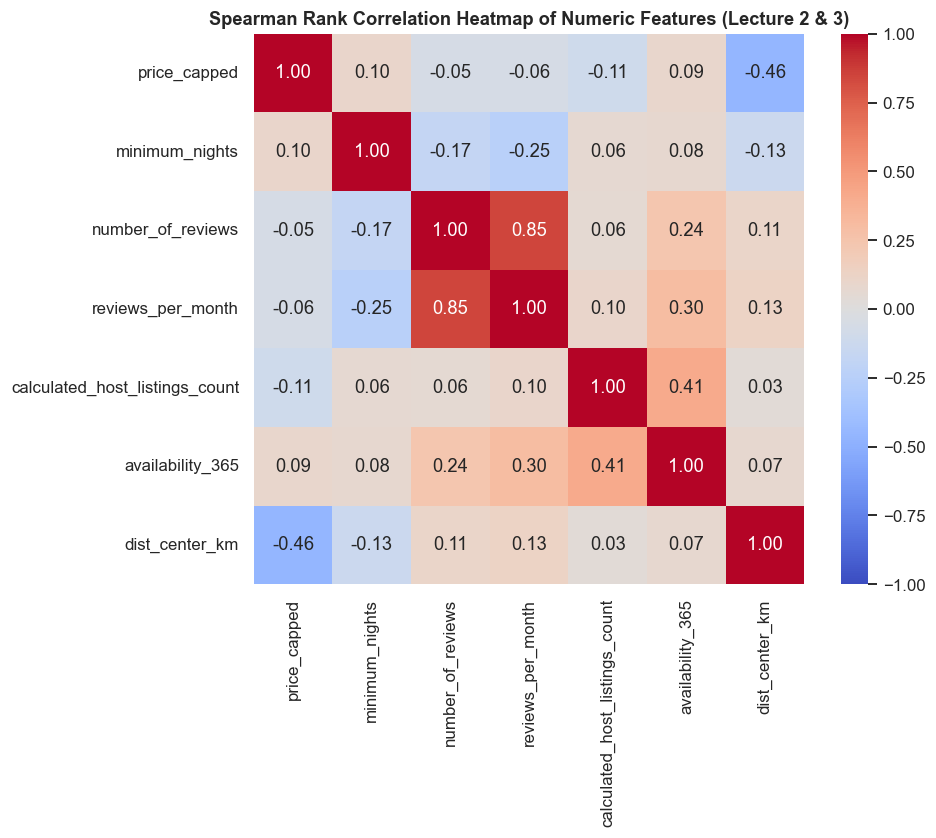

In [15]:
corr_cols = ['price_capped', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
             'calculated_host_listings_count', 'availability_365', 'dist_center_km']
corr_matrix = df[corr_cols].corr(method='spearman')

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Spearman Rank Correlation Heatmap of Numeric Features (Lecture 2 & 3)')
show('eda_correlation_heatmap')

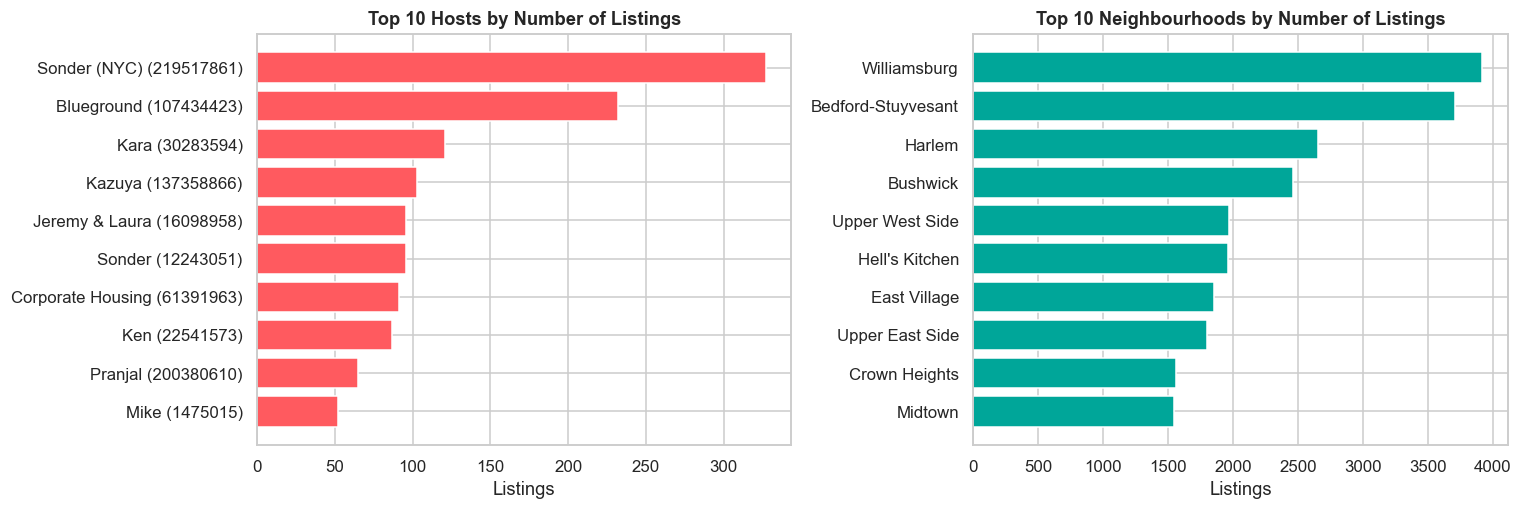

In [16]:
top_hosts = df.groupby(['host_id', 'host_name']).size().nlargest(10).sort_values().reset_index(name='listings')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(top_hosts['host_name'] + ' (' + top_hosts['host_id'].astype(str) + ')', top_hosts['listings'], color=AB_RED)
axes[0].set_title('Top 10 Hosts by Number of Listings')
axes[0].set_xlabel('Listings')

top_n = df['neighbourhood'].value_counts().nlargest(10).sort_values()
axes[1].barh(top_n.index, top_n.values, color='#00A699')
axes[1].set_title('Top 10 Neighbourhoods by Number of Listings')
axes[1].set_xlabel('Listings')
plt.tight_layout()
show('eda_top_hosts_neighbourhoods')

---
## 9. Analysis Questions: Hypothesis Testing, A/B Testing & Core FODS Concepts

Every question follows the same template: **objective → hypotheses → test → effect size → interpretation**. Significance level $\alpha = 0.05$.
All formal tests are collected in a register and re-evaluated with a **Holm multiple-testing correction** at the end of this section.

### Question 1: How Are Nightly Prices Distributed, and Does a Log-Transformation Fix the Skew?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 9 & 10 (Mean vs Median, Skewness, Kurtosis, Shape of a Distribution).

- **Objective:** Characterise the shape of the target variable and justify the transformation used in all later parametric analysis.
- **Null Hypothesis ($H_0$):** Prices (or log-prices) follow a Normal distribution (skewness = 0, excess kurtosis = 0).
- **Alternative Hypothesis ($H_1$):** The distribution departs from Normality.

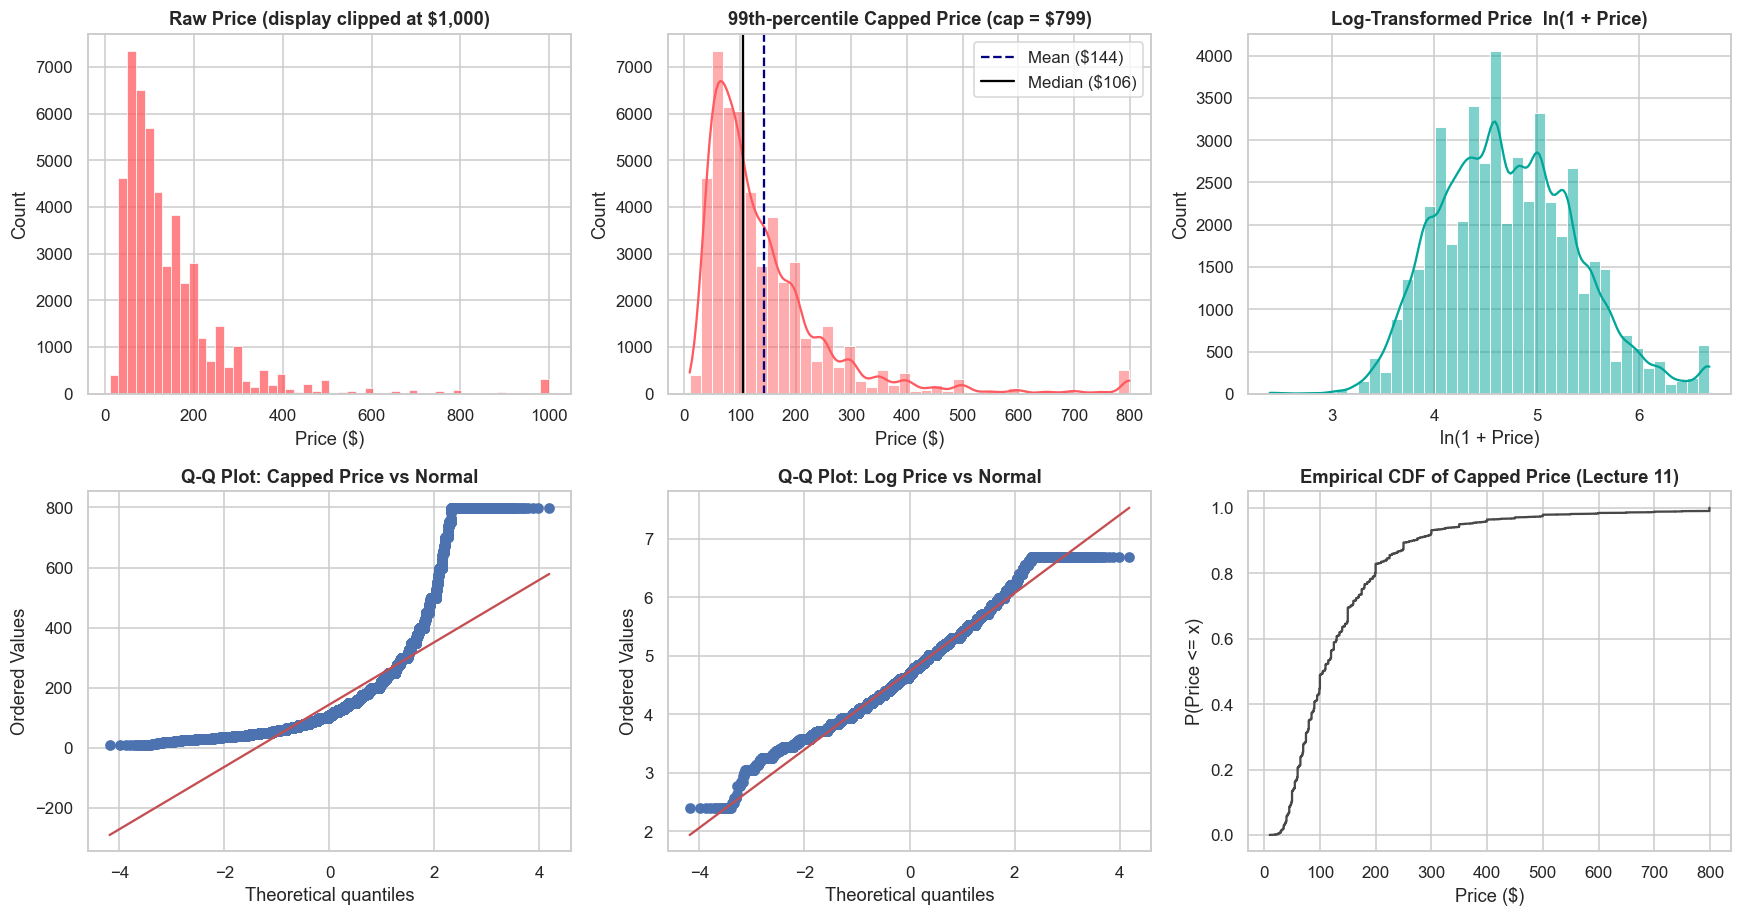

,mean,median,std,skew,kurt,D'Agostino K2,p-value
Raw price,152.759,106.000,240.199,19.117,585.519,105025.336,0.0
Capped price,143.990,106.000,121.937,2.777,10.154,28968.457,0.0
Log price,4.733,4.673,0.672,0.367,0.010,1029.054,0.0


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))

sns.histplot(df['price'].clip(upper=1000), bins=50, color=AB_RED, ax=axes[0, 0])
axes[0, 0].set_title('Raw Price (display clipped at $1,000)')
axes[0, 0].set_xlabel('Price ($)')

sns.histplot(df['price_capped'], bins=40, kde=True, ax=axes[0, 1], color=AB_RED)
axes[0, 1].axvline(df['price_capped'].mean(), color='navy', linestyle='--', label=f"Mean (${df['price_capped'].mean():.0f})")
axes[0, 1].axvline(df['price_capped'].median(), color='black', linestyle='-', label=f"Median (${df['price_capped'].median():.0f})")
axes[0, 1].set_title(f'99th-percentile Capped Price (cap = ${price_cap:,.0f})')
axes[0, 1].set_xlabel('Price ($)')
axes[0, 1].legend()

sns.histplot(df['log_price'], bins=40, kde=True, ax=axes[0, 2], color=AB_TEAL)
axes[0, 2].set_title('Log-Transformed Price  ln(1 + Price)')
axes[0, 2].set_xlabel('ln(1 + Price)')

stats.probplot(df['price_capped'], dist='norm', plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot: Capped Price vs Normal')
stats.probplot(df['log_price'], dist='norm', plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot: Log Price vs Normal')

xs = np.sort(df['price_capped'].values)
axes[1, 2].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=AB_GREY)
axes[1, 2].set_title('Empirical CDF of Capped Price (Lecture 11)')
axes[1, 2].set_xlabel('Price ($)')
axes[1, 2].set_ylabel('P(Price <= x)')
plt.tight_layout()
show('q1_price_distribution')

shape = pd.DataFrame({
    'Raw price': df['price'], 'Capped price': df['price_capped'], 'Log price': df['log_price']
}).agg(['mean', 'median', 'std', 'skew', 'kurt']).T
shape['D\'Agostino K2'] = [stats.normaltest(df[c])[0] for c in ['price', 'price_capped', 'log_price']]
shape['p-value'] = [stats.normaltest(df[c])[1] for c in ['price', 'price_capped', 'log_price']]
display(shape.round(3))

RES.update(skew_raw=float(df['price'].skew()), skew_capped=float(df['price_capped'].skew()), skew_log=float(df['log_price'].skew()),
           kurt_raw=float(df['price'].kurt()), kurt_log=float(df['log_price'].kurt()),
           mean_price=float(df['price'].mean()), median_price=float(df['price'].median()))

In [18]:
md_out(f"""### Interpretation
**Result.** Raw price is extremely right-skewed (skewness **{RES['skew_raw']:.2f}**, excess kurtosis **{RES['kurt_raw']:.0f}**): the mean (${RES['mean_price']:.0f}) sits far above the
median (${RES['median_price']:.0f}) because a thin tail of luxury listings reaches $10,000. Winsorising at the 99th percentile (${price_cap:,.0f}) reduces skewness to **{RES['skew_capped']:.2f}**, and the
log transform to **{RES['skew_log']:.2f}** with excess kurtosis **{RES['kurt_log']:.2f}**. D'Agostino's test still rejects exact Normality for all three scales (p ≈ 0), which is expected with
n = {len(df):,}, but the log-price Q-Q plot hugs the diagonal while the raw-price plot bends sharply away.

**What it means.** Prices behave multiplicatively (a Manhattan premium is a *percentage*, not a fixed dollar amount), so **log-price is the correct scale for t-tests, ANOVA and regression**. The mean is a poor
summary of a "typical" listing; the **median is the headline statistic** used throughout this study.""")

### Interpretation
**Result.** Raw price is extremely right-skewed (skewness **19.12**, excess kurtosis **586**): the mean (\$153) sits far above the
median (\$106) because a thin tail of luxury listings reaches \$10,000. Winsorising at the 99th percentile (\$799) reduces skewness to **2.78**, and the
log transform to **0.37** with excess kurtosis **0.01**. D'Agostino's test still rejects exact Normality for all three scales (p ≈ 0), which is expected with
n = 48,870, but the log-price Q-Q plot hugs the diagonal while the raw-price plot bends sharply away.

**What it means.** Prices behave multiplicatively (a Manhattan premium is a *percentage*, not a fixed dollar amount), so **log-price is the correct scale for t-tests, ANOVA and regression**. The mean is a poor
summary of a "typical" listing; the **median is the headline statistic** used throughout this study.

---
### Question 2: Do the Five Boroughs Differ in Price?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 7 (Variance Decomposition & ANOVA) and Lecture 13 (Comparing Several Group Means).

- **Objective:** Test whether the average price level depends on borough and measure how much of the price variance borough explains.
- **Null Hypothesis ($H_0$):** $\mu_{Manhattan} = \mu_{Brooklyn} = \mu_{Queens} = \mu_{Bronx} = \mu_{Staten\ Island}$ (log-price).
- **Alternative Hypothesis ($H_1$):** At least one borough mean differs.
- **Method:** Because group variances are unequal (Levene test), the primary test is **Welch's ANOVA**; Kruskal–Wallis and Tukey HSD are used as robustness and post-hoc checks.

In [19]:
borough_summary = df.groupby('neighbourhood_group')['price_capped'].agg(
    count='count', mean='mean', median='median', std='std',
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)).loc[BOROUGH_ORDER].round(2)

b_groups = [df.loc[df['neighbourhood_group'] == b, 'log_price'].values for b in BOROUGH_ORDER]
b_groups_raw = [df.loc[df['neighbourhood_group'] == b, 'price_capped'].values for b in BOROUGH_ORDER]

lev_stat, lev_p = stats.levene(*b_groups)
welch = anova_oneway(b_groups, use_var='unequal')
f_classic, p_classic = stats.f_oneway(*b_groups)
h_stat, p_kw = stats.kruskal(*b_groups_raw)
eta2 = eta_squared(b_groups)
eps2 = epsilon_squared(h_stat, len(df))

print(f"Levene test for equal variances: W = {lev_stat:.2f}, p = {fmt_p(lev_p)} -> variances differ, Welch correction needed")
print(f"Classic one-way ANOVA: F = {f_classic:,.2f}, p = {fmt_p(p_classic)}")
report('Q2', 'Mean log-price equal across 5 boroughs', 'Welch ANOVA', welch.statistic, welch.pvalue,
       'eta-squared', eta2, magnitude(eta2, 0.01, 0.06, 0.14))
print(f'Kruskal-Wallis (non-parametric check): H = {h_stat:,.2f}, p = {fmt_p(p_kw)}, epsilon-squared = {eps2:.3f}')

tukey = pairwise_tukeyhsd(df['log_price'], df['neighbourhood_group'], alpha=ALPHA)
tukey_df = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
tukey_df['price ratio (g2/g1)'] = np.exp(tukey_df['meandiff'].astype(float)).round(3)
print('\nTukey HSD post-hoc comparisons (log-price scale):')
display(tukey_df)
display(borough_summary)

RES.update(eta2_borough=float(eta2), F_borough=float(f_classic), welch_F_borough=float(welch.statistic), H_borough=float(h_stat),
           median_by_borough=borough_summary['median'].to_dict())

Levene test for equal variances: W = 29.05, p = 3.72e-24 -> variances differ, Welch correction needed
Classic one-way ANOVA: F = 1,928.01, p = < 1e-300
Welch ANOVA: statistic = 1,973.267,  p-value = < 1e-300  ->  Reject H0
Effect size (eta-squared) = 0.136  ->  medium
Kruskal-Wallis (non-parametric check): H = 7,022.32, p = < 1e-300, epsilon-squared = 0.144



Tukey HSD post-hoc comparisons (log-price scale):


,group1,group2,meandiff,p-adj,lower,upper,reject,price ratio (g2/g1)
0,Bronx,Brooklyn,0.3167,0.0000,0.2637,0.3698,True,1.373
1,Bronx,Manhattan,0.7399,0.0000,0.6870,0.7929,True,2.096
2,Bronx,Queens,0.1243,0.0000,0.0679,0.1807,True,1.132
3,Bronx,Staten Island,0.1211,0.0109,0.0188,0.2234,True,1.129
4,Brooklyn,Manhattan,0.4232,0.0000,0.4065,0.4399,True,1.527
5,Brooklyn,Queens,-0.1924,0.0000,-0.2180,-0.1668,True,0.825
6,Brooklyn,Staten Island,-0.1956,0.0000,-0.2847,-0.1065,True,0.822
7,Manhattan,Queens,-0.6156,0.0000,-0.6410,-0.5902,True,0.540
8,Manhattan,Staten Island,-0.6188,0.0000,-0.7079,-0.5298,True,0.539
9,Queens,Staten Island,-0.0032,1.0000,-0.0944,0.0879,False,0.997


,count,mean,median,std,iqr
neighbourhood_group,,,,,
Manhattan,21654,182.96,150.0,139.81,125.0
Brooklyn,20089,119.43,90.0,98.58,90.0
Queens,5664,96.07,75.0,78.57,60.0
Bronx,1090,85.83,65.0,78.78,54.0
Staten Island,373,101.80,75.0,104.65,60.0


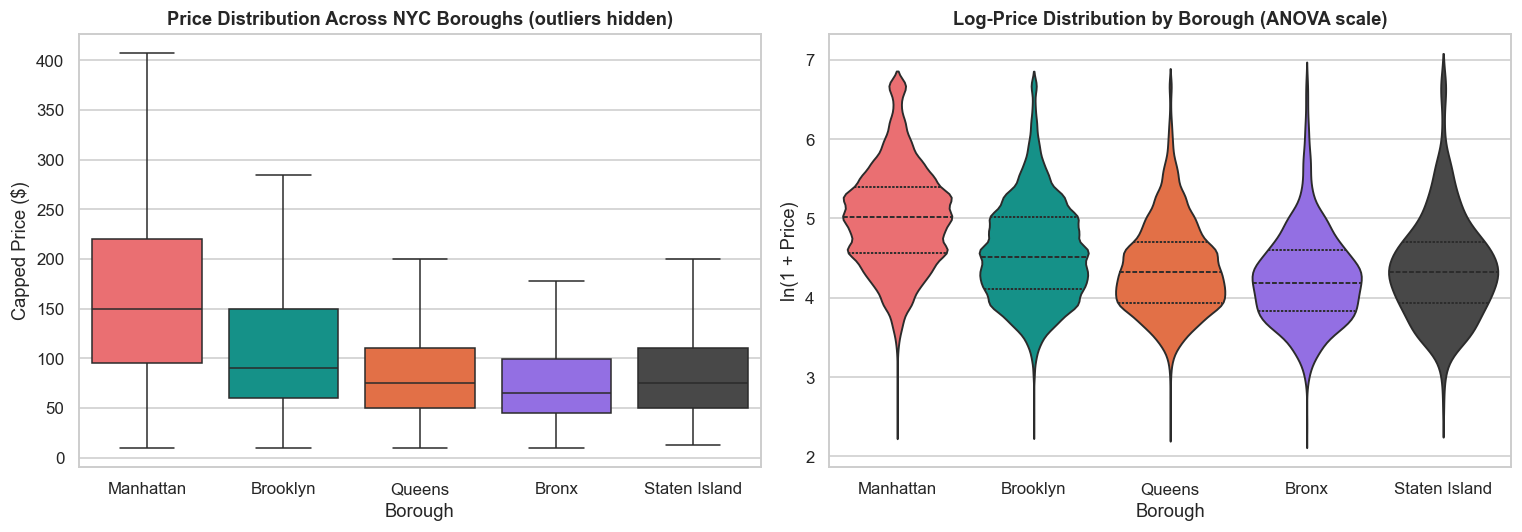

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='neighbourhood_group', y='price_capped', order=BOROUGH_ORDER, palette=BOROUGH_COLORS, showfliers=False, ax=axes[0])
axes[0].set_title('Price Distribution Across NYC Boroughs (outliers hidden)')
axes[0].set_xlabel('Borough'); axes[0].set_ylabel('Capped Price ($)')

sns.violinplot(data=df, x='neighbourhood_group', y='log_price', order=BOROUGH_ORDER, palette=BOROUGH_COLORS, inner='quartile', ax=axes[1])
axes[1].set_title('Log-Price Distribution by Borough (ANOVA scale)')
axes[1].set_xlabel('Borough'); axes[1].set_ylabel('ln(1 + Price)')
plt.tight_layout()
show('q2_borough_prices')

In [21]:
td = tukey_df.set_index(['group1', 'group2'])['meandiff'].astype(float)
not_sig = tukey_df.loc[~tukey_df['reject'].astype(bool), ['group1', 'group2']].values.tolist()
md_out(f"""### Interpretation
**Result: reject H0.** Median price falls from **${RES['median_by_borough']['Manhattan']:.0f} (Manhattan)** to ${RES['median_by_borough']['Brooklyn']:.0f} (Brooklyn), ${RES['median_by_borough']['Queens']:.0f} (Queens and Staten Island) and
**${RES['median_by_borough']['Bronx']:.0f} (Bronx)**. Welch ANOVA gives F = {RES['welch_F_borough']:,.0f} (p < 10⁻³⁰⁰), and the non-parametric Kruskal–Wallis agrees (H = {RES['H_borough']:,.0f}). Borough explains
**η² = {RES['eta2_borough']:.3f}** of the variance in log-price, a *medium* effect. Tukey's HSD finds every pair of boroughs different except
{', '.join(' vs '.join(p) for p in not_sig) if not_sig else 'none'}, where the difference is statistically indistinguishable from zero.

**What it means.** On the price ratio scale, Manhattan listings cost about **{np.exp(td[('Brooklyn', 'Manhattan')]):.2f}×** Brooklyn and **{np.exp(td[('Bronx', 'Manhattan')]):.1f}×** the Bronx. Borough alone still leaves ≈ {1 - RES['eta2_borough']:.0%} of the
price variance unexplained, which motivates the other drivers analysed below (room type, distance, availability).""")

### Interpretation
**Result: reject H0.** Median price falls from **\$150 (Manhattan)** to \$90 (Brooklyn), \$75 (Queens and Staten Island) and
**\$65 (Bronx)**. Welch ANOVA gives F = 1,973 (p < 10⁻³⁰⁰), and the non-parametric Kruskal–Wallis agrees (H = 7,022). Borough explains
**η² = 0.136** of the variance in log-price, a *medium* effect. Tukey's HSD finds every pair of boroughs different except
Queens vs Staten Island, where the difference is statistically indistinguishable from zero.

**What it means.** On the price ratio scale, Manhattan listings cost about **1.53×** Brooklyn and **2.1×** the Bronx. Borough alone still leaves ≈ 86% of the
price variance unexplained, which motivates the other drivers analysed below (room type, distance, availability).

---
### Question 3 (A/B Test 1): Do Entire Homes Really Cost More than Private Rooms?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 13 (A/B Testing Procedure; Two-sample t-Test, Slides 29–38) & Lecture 14 (Causation & Experiment).

- **Objective:** An observational A/B comparison of Group A (Private rooms, control) and Group B (Entire homes/apartments, treatment) on nightly price.
- **Hypotheses:**
  - $H_0: \mu_{Entire} = \mu_{Private}$ (log-price; no price divergence).
  - $H_1: \mu_{Entire} \neq \mu_{Private}$.
- **Method:** Welch two-sample t-test on log-price, Mann–Whitney U on raw price, Cohen's $d$, and a bootstrap CI for the difference in medians.

Group A (Private room, control)   : n = 22,315, median $70, mean $86.03
Group B (Entire home, treatment)  : n = 25,398, median $160, mean $198.35
A/B Test: Welch t-test: statistic = 175.878,  p-value = < 1e-300  ->  Reject H0
Effect size (Cohen's d) = 1.607  ->  large
Mann-Whitney U (robustness): U = 5.033e+08, p = < 1e-300, rank-biserial r = 0.776
95% CI of log-price difference: [0.821, 0.840] -> entire homes cost 127% to 132% more (geometric scale)
Median premium: $90  (bootstrap 95% CI [$86, $96])  =  128.6%


,count,mean,median,std
room_type,,,,
Entire home/apt,25398,198.35,160.0,131.90
Private room,22315,86.03,70.0,73.39
Shared room,1157,68.61,45.0,83.12


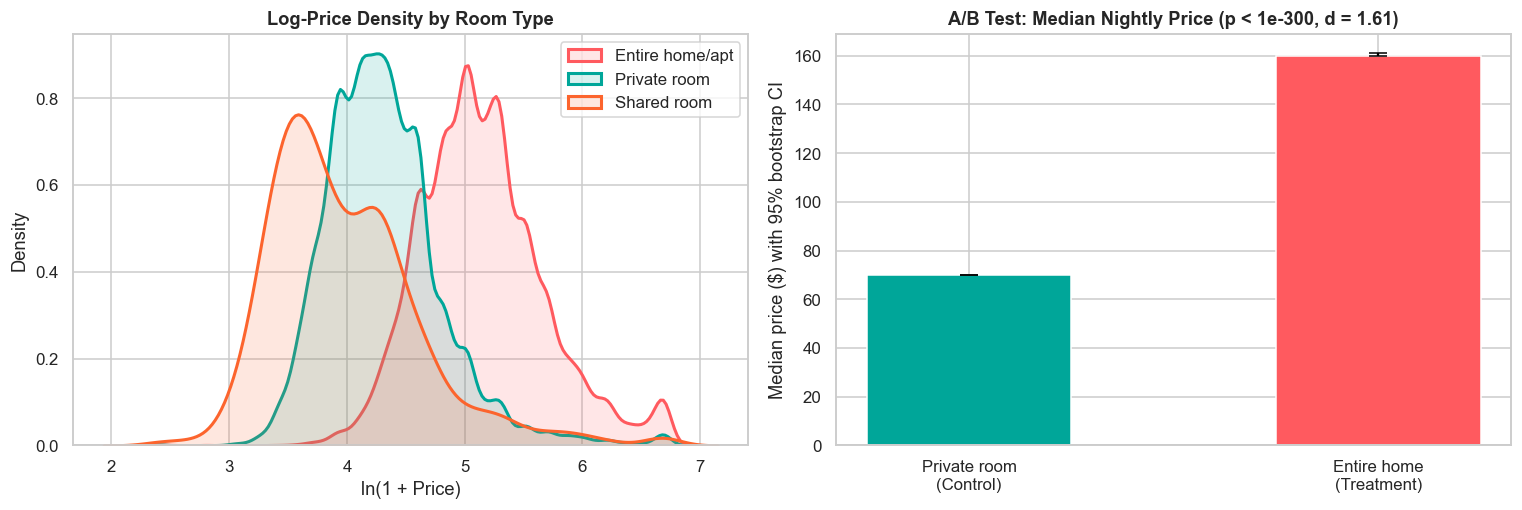

In [22]:
grp_B = df[df['room_type'] == 'Entire home/apt']
grp_A = df[df['room_type'] == 'Private room']

t_stat, p_t = stats.ttest_ind(grp_B['log_price'], grp_A['log_price'], equal_var=False)
u_stat, p_u = stats.mannwhitneyu(grp_B['price_capped'], grp_A['price_capped'], alternative='two-sided')
d_val = cohen_d(grp_B['log_price'], grp_A['log_price'])
r_rb = rank_biserial(u_stat, len(grp_B), len(grp_A))

diff = grp_B['log_price'].mean() - grp_A['log_price'].mean()
se = np.sqrt(grp_B['log_price'].var(ddof=1) / len(grp_B) + grp_A['log_price'].var(ddof=1) / len(grp_A))
ci_lo, ci_hi = diff - 1.96 * se, diff + 1.96 * se

rg = np.random.default_rng(SEED)
boot_diff = [np.median(rg.choice(grp_B['price_capped'].values, 3000)) - np.median(rg.choice(grp_A['price_capped'].values, 3000)) for _ in range(1000)]
med_ci = np.percentile(boot_diff, [2.5, 97.5])
med_B, med_A = grp_B['price_capped'].median(), grp_A['price_capped'].median()

print(f'Group A (Private room, control)   : n = {len(grp_A):,}, median ${med_A:.0f}, mean ${grp_A["price_capped"].mean():.2f}')
print(f'Group B (Entire home, treatment)  : n = {len(grp_B):,}, median ${med_B:.0f}, mean ${grp_B["price_capped"].mean():.2f}')
report('Q3', 'Mean log-price Entire home = Private room', "A/B Test: Welch t-test", t_stat, p_t, "Cohen's d", d_val, magnitude(d_val, 0.2, 0.5, 0.8))
print(f'Mann-Whitney U (robustness): U = {u_stat:.3e}, p = {fmt_p(p_u)}, rank-biserial r = {r_rb:.3f}')
print(f'95% CI of log-price difference: [{ci_lo:.3f}, {ci_hi:.3f}] -> entire homes cost {np.exp(ci_lo) - 1:.0%} to {np.exp(ci_hi) - 1:.0%} more (geometric scale)')
print(f'Median premium: ${med_B - med_A:.0f}  (bootstrap 95% CI [${med_ci[0]:.0f}, ${med_ci[1]:.0f}])  =  {(med_B / med_A - 1):.1%}')

room_summary = df.groupby('room_type')['price_capped'].agg(count='count', mean='mean', median='median', std='std').loc[ROOM_ORDER].round(2)
display(room_summary)

RES.update(t_room=float(t_stat), d_room=float(d_val), med_entire=float(med_B), med_private=float(med_A), room_premium=float(med_B / med_A - 1),
           room_ratio_ci=[float(np.exp(ci_lo)), float(np.exp(ci_hi))])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for r in ROOM_ORDER:
    sns.kdeplot(df.loc[df['room_type'] == r, 'log_price'], ax=axes[0], label=r, color=ROOM_COLORS[r], linewidth=2, fill=True, alpha=0.15)
axes[0].set_title('Log-Price Density by Room Type'); axes[0].set_xlabel('ln(1 + Price)'); axes[0].legend()

axes[1].bar(['Private room\n(Control)', 'Entire home\n(Treatment)'], [med_A, med_B], color=[AB_TEAL, AB_RED], width=0.5)
axes[1].errorbar([1], [med_B], yerr=[[med_B - bootstrap_ci(grp_B['price_capped'].values)[0]], [bootstrap_ci(grp_B['price_capped'].values)[1] - med_B]], color='black', capsize=6)
axes[1].errorbar([0], [med_A], yerr=[[med_A - bootstrap_ci(grp_A['price_capped'].values)[0]], [bootstrap_ci(grp_A['price_capped'].values)[1] - med_A]], color='black', capsize=6)
axes[1].set_title(f'A/B Test: Median Nightly Price (p {"< 1e-300" if p_t < 1e-300 else "= " + format(p_t, ".1e")}, d = {d_val:.2f})')
axes[1].set_ylabel('Median price ($) with 95% bootstrap CI')
plt.tight_layout()
show('q3_ab_room_type')

In [23]:
md_out(f"""### Interpretation
**Result: reject H0 decisively.** Entire homes have a median of **${RES['med_entire']:.0f}** against **${RES['med_private']:.0f}** for private rooms, a **{RES['room_premium']:.0%} premium** (bootstrap 95% CI for the median difference
in the output above). Welch's t = {RES['t_room']:.1f}, p < 10⁻³⁰⁰, and the effect is **large** (Cohen's d = {RES['d_room']:.2f}). On the geometric scale an entire home costs between
{RES['room_ratio_ci'][0]:.2f}× and {RES['room_ratio_ci'][1]:.2f}× a private room (95% CI). The Mann–Whitney test, which makes no Normality assumption, reaches the same conclusion.

**What it means.** The pricing hierarchy *Entire home > Private room > Shared room* is the single strongest and most robust pattern in the data. Because this is an **observational** A/B comparison (hosts chose their room type, nothing was randomised),
the premium describes association, not a guaranteed uplift for a host who converts a private room into an entire unit; entire homes also tend to be larger and better located.""")

### Interpretation
**Result: reject H0 decisively.** Entire homes have a median of **\$160** against **\$70** for private rooms, a **129% premium** (bootstrap 95% CI for the median difference
in the output above). Welch's t = 175.9, p < 10⁻³⁰⁰, and the effect is **large** (Cohen's d = 1.61). On the geometric scale an entire home costs between
2.27× and 2.32× a private room (95% CI). The Mann–Whitney test, which makes no Normality assumption, reaches the same conclusion.

**What it means.** The pricing hierarchy *Entire home > Private room > Shared room* is the single strongest and most robust pattern in the data. Because this is an **observational** A/B comparison (hosts chose their room type, nothing was randomised),
the premium describes association, not a guaranteed uplift for a host who converts a private room into an entire unit; entire homes also tend to be larger and better located.

---
### Question 4: Is Room-Type Mix Independent of Borough?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 13 (Slides 13–17: Chi-Square Test of Independence for Contingency Tables).

- **Objective:** Test whether the type of accommodation offered depends on the borough and identify where the departures from independence are.
- **Null Hypothesis ($H_0$):** Borough and room type are independent.
- **Alternative Hypothesis ($H_1$):** Borough and room type are associated.

Minimum expected cell count: 8.8 (chi-square requires >= 5 -> satisfied)
Chi-square independence (dof = 8): statistic = 1,557.952,  p-value = < 1e-300  ->  Reject H0
Effect size (Cramer's V) = 0.126  ->  small


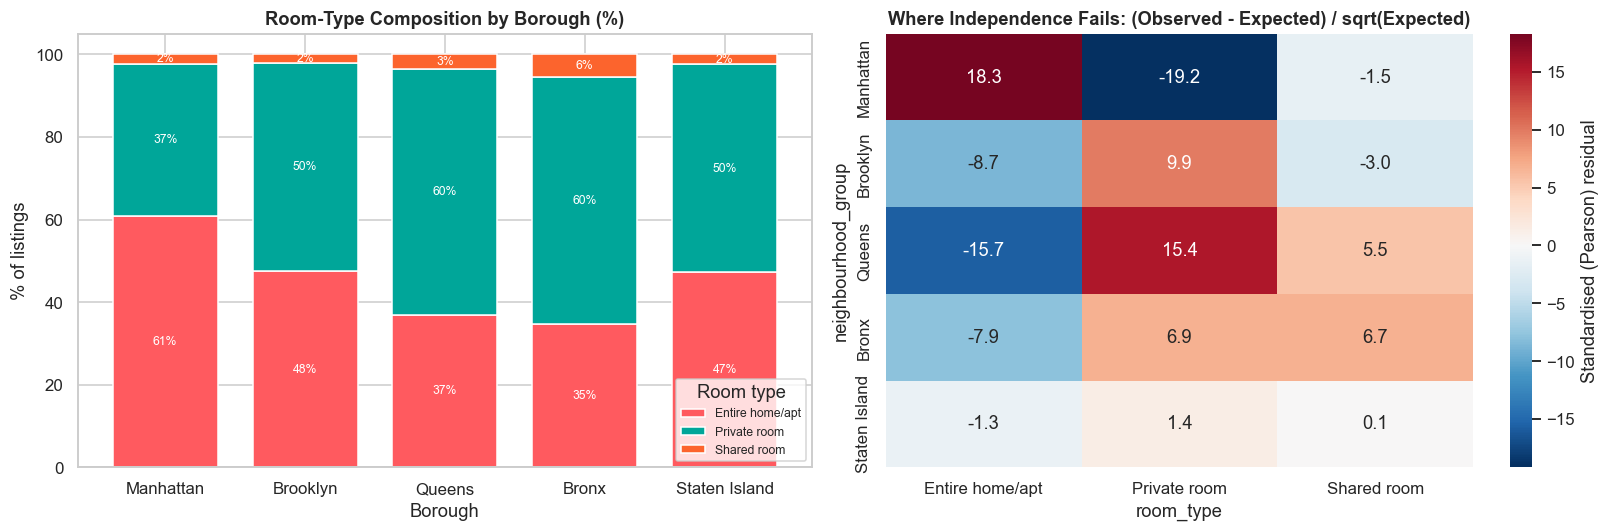

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Manhattan,60.9,36.9,2.2
Brooklyn,47.6,50.4,2.0
Queens,37.0,59.5,3.5
Bronx,34.8,59.7,5.5
Staten Island,47.2,50.4,2.4


In [24]:
contingency = pd.crosstab(df['neighbourhood_group'], df['room_type']).loc[BOROUGH_ORDER, ROOM_ORDER]
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
V = cramers_v(contingency)
std_resid = (contingency - expected) / np.sqrt(expected)

print(f'Minimum expected cell count: {expected.min():.1f} (chi-square requires >= 5 -> {"satisfied" if expected.min() >= 5 else "violated"})')
report('Q4', 'Borough and room type are independent', f'Chi-square independence (dof = {dof})', chi2, p_chi, "Cramer's V", V, magnitude(V, 0.1, 0.3, 0.5))

ct_pct = pd.crosstab(df['neighbourhood_group'], df['room_type'], normalize='index').loc[BOROUGH_ORDER, ROOM_ORDER] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ct_pct.plot(kind='bar', stacked=True, color=[ROOM_COLORS[r] for r in ROOM_ORDER], ax=axes[0], width=0.75)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.0f%%', label_type='center', color='white', fontsize=8)
axes[0].set_title('Room-Type Composition by Borough (%)'); axes[0].set_xlabel('Borough'); axes[0].set_ylabel('% of listings')
axes[0].tick_params(axis='x', rotation=0); axes[0].legend(title='Room type', loc='lower right', fontsize=8)

sns.heatmap(std_resid, annot=True, fmt='.1f', cmap='RdBu_r', center=0, ax=axes[1], cbar_kws={'label': 'Standardised (Pearson) residual'})
axes[1].set_title('Where Independence Fails: (Observed - Expected) / sqrt(Expected)')
plt.tight_layout()
show('q4_borough_room_mix')

display(ct_pct.round(1))
RES.update(chi2_borough_room=float(chi2), V_borough_room=float(V), dof_chi=int(dof),
           manhattan_entire_pct=float(ct_pct.loc['Manhattan', 'Entire home/apt']), brooklyn_private_pct=float(ct_pct.loc['Brooklyn', 'Private room']))

In [25]:
md_out(f"""### Interpretation
**Result: reject H0.** χ² = {RES['chi2_borough_room']:,.0f} (dof = {RES['dof_chi']}, p < 10⁻³⁰⁰). The association is statistically unmistakable but **small in strength** (Cramér's V = {RES['V_borough_room']:.3f}).
The residual heatmap shows where independence fails: **Manhattan is {RES['manhattan_entire_pct']:.0f}% entire homes**, whereas Queens and the Bronx are dominated by private rooms
(≈ {ct_pct.loc['Queens', 'Private room']:.0f}% and {ct_pct.loc['Bronx', 'Private room']:.0f}%) and Brooklyn is split almost evenly ({RES['brooklyn_private_pct']:.0f}% private rooms).

**What it means.** Part of Manhattan's high borough-average price is a **composition effect**: it simply contains more of the expensive room type. This is why room type and borough must be modelled
together (Q17) instead of being read separately, and it is a first example of a confounder (Lecture 14).""")

### Interpretation
**Result: reject H0.** χ² = 1,558 (dof = 8, p < 10⁻³⁰⁰). The association is statistically unmistakable but **small in strength** (Cramér's V = 0.126).
The residual heatmap shows where independence fails: **Manhattan is 61% entire homes**, whereas Queens and the Bronx are dominated by private rooms
(≈ 60% and 60%) and Brooklyn is split almost evenly (50% private rooms).

**What it means.** Part of Manhattan's high borough-average price is a **composition effect**: it simply contains more of the expensive room type. This is why room type and borough must be modelled
together (Q17) instead of being read separately, and it is a first example of a confounder (Lecture 14).

---
### Question 5: Which Neighbourhoods Are the Most Expensive Once Small Samples Are Controlled?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 10 (Median & IQR as robust summaries) and Lecture 12 (Sampling Variability & Confidence Intervals).

- **Objective:** Rank neighbourhoods by **median** price, using only neighbourhoods with $n \ge 25$ listings and attaching a 95 % bootstrap confidence interval to every rank so that thin-sample artefacts are not mistaken for real differences.
- **Null Hypothesis ($H_0$):** Median price is identical across all qualifying neighbourhoods.
- **Alternative Hypothesis ($H_1$):** At least one neighbourhood's price distribution differs (Kruskal–Wallis).

Neighbourhoods with n >= 25: 123 of 221 (98.1% of listings)
Kruskal-Wallis (123 groups): statistic = 14,256.036,  p-value = < 1e-300  ->  Reject H0
Effect size (epsilon-squared) = 0.297  ->  large


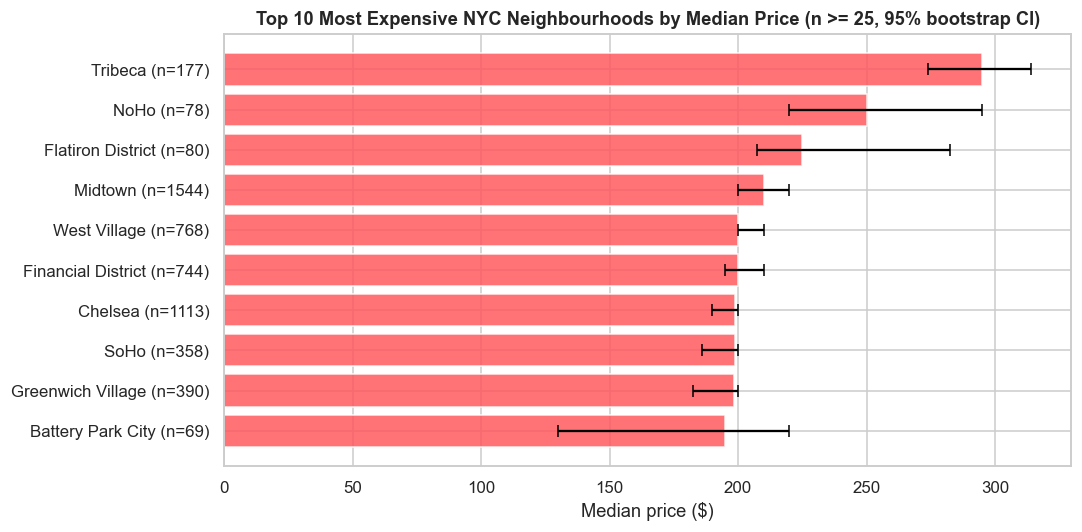

,median,mean,count,ci_low,ci_high
neighbourhood,,,,,
Tribeca,295.0,355.4,177,274.0,314.0
NoHo,250.0,282.9,78,220.0,295.0
Flatiron District,225.0,298.7,80,207.4,282.5
Midtown,210.0,270.5,1544,200.0,220.0
West Village,200.0,247.3,768,200.0,210.0
Financial District,200.0,220.4,744,195.0,210.0
Chelsea,199.0,228.0,1113,190.0,200.0
SoHo,199.0,263.2,358,186.0,200.0
Greenwich Village,198.5,226.2,390,182.5,200.0


In [26]:
MIN_N = 25
nb_counts = df['neighbourhood'].value_counts()
valid_nb = nb_counts[nb_counts >= MIN_N].index
d_valid = df[df['neighbourhood'].isin(valid_nb)]

nb_stats = d_valid.groupby('neighbourhood')['price_capped'].agg(median='median', mean='mean', count='count').sort_values('median', ascending=False)
top10 = nb_stats.head(10).copy()
cis = np.array([bootstrap_ci(d_valid.loc[d_valid['neighbourhood'] == n, 'price_capped'].values, n_boot=1000) for n in top10.index])
top10['ci_low'], top10['ci_high'] = cis[:, 0], cis[:, 1]

kw_groups = [g['price_capped'].values for _, g in d_valid.groupby('neighbourhood')]
H5, p5 = stats.kruskal(*kw_groups)
eps5 = epsilon_squared(H5, len(d_valid))
print(f'Neighbourhoods with n >= {MIN_N}: {len(valid_nb)} of {df["neighbourhood"].nunique()} ({len(d_valid) / len(df):.1%} of listings)')
report('Q5', 'Median price identical across qualifying neighbourhoods', f'Kruskal-Wallis ({len(valid_nb)} groups)', H5, p5,
       'epsilon-squared', eps5, magnitude(eps5, 0.01, 0.06, 0.14))

plt.figure(figsize=(10, 5))
yy = np.arange(len(top10))[::-1]
plt.barh(yy, top10['median'], color=AB_RED, alpha=0.85)
plt.errorbar(top10['median'], yy, xerr=[top10['median'] - top10['ci_low'], top10['ci_high'] - top10['median']], fmt='none', ecolor='black', capsize=4)
plt.yticks(yy, [f'{n} (n={c})' for n, c in zip(top10.index, top10['count'])])
plt.title(f'Top 10 Most Expensive NYC Neighbourhoods by Median Price (n >= {MIN_N}, 95% bootstrap CI)')
plt.xlabel('Median price ($)')
plt.tight_layout()
show('q5_top_neighbourhoods')

display(top10.round(1))
RES.update(top_neighbourhood=top10.index[0], top_neighbourhood_median=float(top10['median'].iloc[0]), H_neigh=float(H5), eps2_neigh=float(eps5),
           n_valid_neigh=int(len(valid_nb)), top10_neigh=top10['median'].round(1).to_dict())

In [27]:
sep = top10['ci_low'].iloc[0] > top10['ci_high'].iloc[1]
md_out(f"""### Interpretation
**Result.** **{RES['top_neighbourhood']}** has the highest median price (**${RES['top_neighbourhood_median']:.0f}**), followed by {', '.join(top10.index[1:5])}. All ten leaders are in Manhattan's core or Lower Manhattan. {RES['n_valid_neigh']} of
{df['neighbourhood'].nunique()} neighbourhoods qualify under the n ≥ {MIN_N} rule yet they hold {len(d_valid) / len(df):.1%} of all listings, so the threshold removes noise, not information. The Kruskal–Wallis test across
those neighbourhoods rejects H0 (H = {RES['H_neigh']:,.0f}) with a **large** effect (ε² = {RES['eps2_neigh']:.2f}): **neighbourhood explains more rank variation than borough does** (η² = {RES['eta2_borough']:.2f} for borough).
{"Tribeca's confidence interval lies entirely above the second-ranked neighbourhood, so its first place is statistically secure." if sep else "The confidence intervals of the top neighbourhoods overlap, so their exact order should not be over-interpreted."}

**What it means.** Hosts and guests should benchmark prices against the **neighbourhood**, not the borough: a Midtown or Tribeca listing and an Upper-Manhattan listing are different markets even though both are "Manhattan".""")

### Interpretation
**Result.** **Tribeca** has the highest median price (**\$295**), followed by NoHo, Flatiron District, Midtown, West Village. All ten leaders are in Manhattan's core or Lower Manhattan. 123 of
221 neighbourhoods qualify under the n ≥ 25 rule yet they hold 98.1% of all listings, so the threshold removes noise, not information. The Kruskal–Wallis test across
those neighbourhoods rejects H0 (H = 14,256) with a **large** effect (ε² = 0.30): **neighbourhood explains more rank variation than borough does** (η² = 0.14 for borough).
The confidence intervals of the top neighbourhoods overlap, so their exact order should not be over-interpreted.

**What it means.** Hosts and guests should benchmark prices against the **neighbourhood**, not the borough: a Midtown or Tribeca listing and an Upper-Manhattan listing are different markets even though both are "Manhattan".

---
### Question 6: Does a More Available Listing Charge More or Less?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 2 (Correlation), Lecture 7 (Multiple Regression) & Lecture 14 (Confounding Variables).

- **Objective:** Measure the association between annual availability and price, then check whether it **survives controlling for room type and borough** (a confounder check).
- **Null Hypothesis ($H_0$):** $\rho = 0$ between `availability_365` and price.
- **Alternative Hypothesis ($H_1$):** $\rho \neq 0$.

Spearman rank correlation: statistic = 0.086,  p-value = 3.46e-81  ->  Reject H0
Effect size (rho^2 (shared rank variance)) = 0.007  ->  negligible
Pearson r (availability vs log-price) = 0.0978, p = 4.03e-104, R^2 = 0.0096



After controlling for room type and borough (OLS, HC3 robust SE):
  coefficient = 0.000606 per day  ->  +100 days = +6.2% price,  p = 3.85e-256


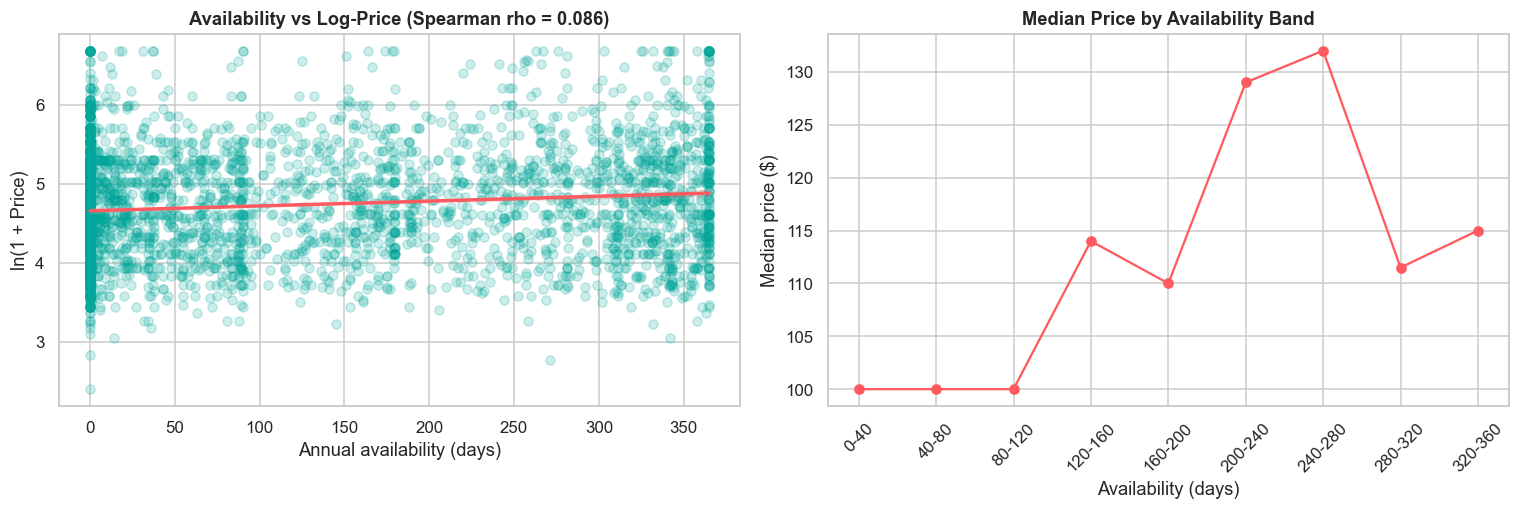

In [28]:
r_p, p_p = stats.pearsonr(df['availability_365'], df['log_price'])
rho_s, p_s = stats.spearmanr(df['availability_365'], df['price_capped'])
report('Q6', 'No monotonic association between availability and price', 'Spearman rank correlation', rho_s, p_s,
       'rho^2 (shared rank variance)', rho_s ** 2, magnitude(rho_s, 0.1, 0.3, 0.5))
print(f'Pearson r (availability vs log-price) = {r_p:.4f}, p = {fmt_p(p_p)}, R^2 = {r_p ** 2:.4f}')

ols_av = smf.ols('log_price ~ availability_365 + C(room_type) + C(neighbourhood_group)', data=df).fit(cov_type='HC3')
b_av = ols_av.params['availability_365']
print(f'\nAfter controlling for room type and borough (OLS, HC3 robust SE):')
print(f'  coefficient = {b_av:.6f} per day  ->  +100 days = {np.exp(100 * b_av) - 1:+.1%} price,  p = {fmt_p(ols_av.pvalues["availability_365"])}')

sample_df = df.sample(4000, random_state=SEED)
df['avail_bin'] = pd.cut(df['availability_365'], bins=range(0, 400, 40), include_lowest=True)
binned = df.groupby('avail_bin', observed=True)['price_capped'].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.regplot(data=sample_df, x='availability_365', y='log_price', scatter_kws={'alpha': 0.2, 'color': AB_TEAL}, line_kws={'color': AB_RED}, ax=axes[0])
axes[0].set_title(f'Availability vs Log-Price (Spearman rho = {rho_s:.3f})')
axes[0].set_xlabel('Annual availability (days)'); axes[0].set_ylabel('ln(1 + Price)')
axes[1].plot(range(len(binned)), binned.values, marker='o', color=AB_RED)
axes[1].set_xticks(range(len(binned))); axes[1].set_xticklabels([f'{int(i.left)}-{int(i.right)}' for i in binned.index], rotation=45)
axes[1].set_title('Median Price by Availability Band'); axes[1].set_xlabel('Availability (days)'); axes[1].set_ylabel('Median price ($)')
plt.tight_layout()
show('q6_availability_price')

RES.update(rho_avail=float(rho_s), r_avail_log=float(r_p), p_avail=float(p_s), coef_avail_controlled=float(b_av), p_avail_controlled=float(ols_av.pvalues['availability_365']))

In [29]:
md_out(f"""### Interpretation
**Result: reject H0, but the relationship is practically negligible.** Spearman ρ = **{RES['rho_avail']:.3f}** (p = {RES['p_avail']:.1e}); the share of rank variance explained is only {RES['rho_avail'] ** 2:.1%}. The Pearson correlation with
log-price is r = {RES['r_avail_log']:.3f} (R² = {RES['r_avail_log'] ** 2:.4f}). Controlling for room type and borough, **each additional 100 available days is associated with a {np.exp(100 * RES['coef_avail_controlled']) - 1:+.1%} higher price** (robust p ≈ 0),
so the sign is stable but the magnitude is small.

**What it means.** With ~49,000 listings even a trivial slope is "significant" — a textbook case of **statistical significance ≠ practical importance**. Listings that are open all year are slightly pricier (consistent with
professionally run, always-available units), but availability alone is a poor guide to price.""")

### Interpretation
**Result: reject H0, but the relationship is practically negligible.** Spearman ρ = **0.086** (p = 3.5e-81); the share of rank variance explained is only 0.7%. The Pearson correlation with
log-price is r = 0.098 (R² = 0.0096). Controlling for room type and borough, **each additional 100 available days is associated with a +6.2% higher price** (robust p ≈ 0),
so the sign is stable but the magnitude is small.

**What it means.** With ~49,000 listings even a trivial slope is "significant" — a textbook case of **statistical significance ≠ practical importance**. Listings that are open all year are slightly pricier (consistent with
professionally run, always-available units), but availability alone is a poor guide to price.

---
### Question 7: How Strongly Are Cumulative Reviews and Review Velocity Related?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 2 (Correlation & its interpretation).

- **Objective:** Quantify the relation between a *cumulative* metric (`number_of_reviews`) and a *rate* metric (`reviews_per_month`), including a confidence interval for $r$ via the Fisher $z$-transform.
- **Null Hypothesis ($H_0$):** $\rho = 0$.
- **Alternative Hypothesis ($H_1$):** $\rho \neq 0$.

All listings (n = 48,870, zeros included)  : Pearson r = 0.5893
Spearman (reviewed listings, n = 38,827): statistic = 0.706,  p-value = < 1e-300  ->  Reject H0
Effect size (rho^2) = 0.499  ->  large
Pearson r (reviewed listings) = 0.5497, 95% CI [0.543, 0.557] (Fisher z)


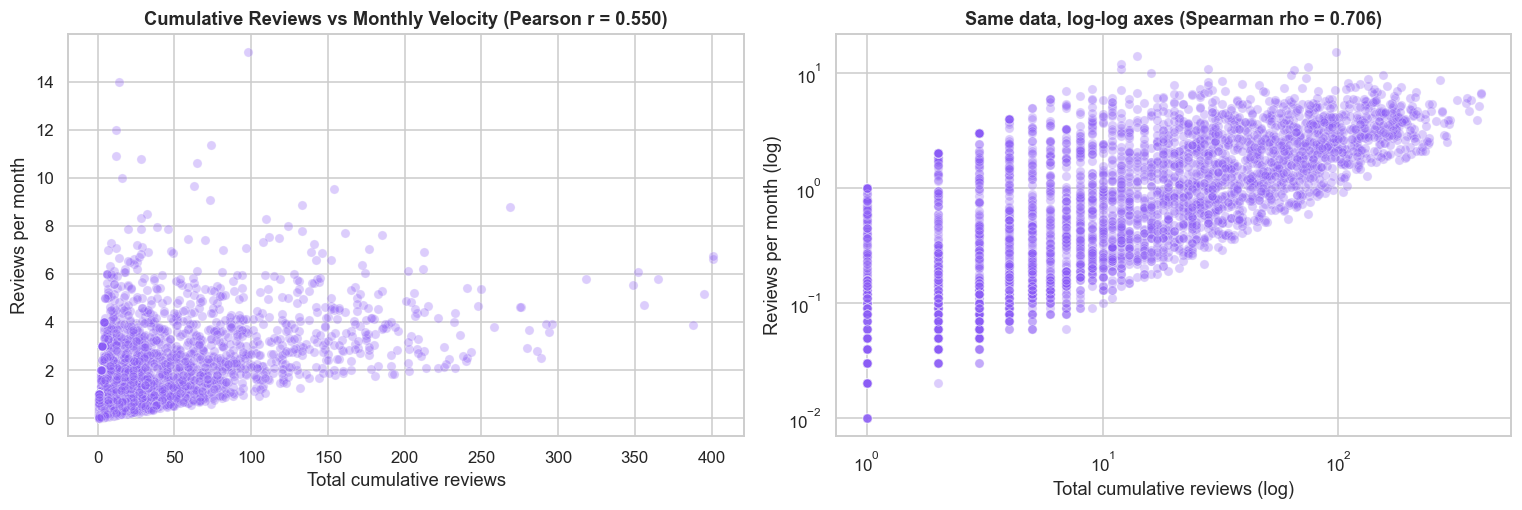

In [30]:
reviewed = df[df['has_reviews']]
r_all, p_all = stats.pearsonr(df['number_of_reviews'], df['reviews_per_month'])
r_rev, p_rev = stats.pearsonr(reviewed['number_of_reviews'], reviewed['reviews_per_month'])
rho_rev, p_rho_rev = stats.spearmanr(reviewed['number_of_reviews'], reviewed['reviews_per_month'])

z = np.arctanh(r_rev); se_z = 1 / np.sqrt(len(reviewed) - 3)
r_lo, r_hi = np.tanh(z - 1.96 * se_z), np.tanh(z + 1.96 * se_z)

print(f'All listings (n = {len(df):,}, zeros included)  : Pearson r = {r_all:.4f}')
report('Q7', 'No correlation between total reviews and review velocity', f'Spearman (reviewed listings, n = {len(reviewed):,})', rho_rev, p_rho_rev,
       'rho^2', rho_rev ** 2, magnitude(rho_rev, 0.1, 0.3, 0.5))
print(f'Pearson r (reviewed listings) = {r_rev:.4f}, 95% CI [{r_lo:.3f}, {r_hi:.3f}] (Fisher z)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
s2 = reviewed.sample(4000, random_state=SEED)
sns.scatterplot(data=s2, x='number_of_reviews', y='reviews_per_month', alpha=0.3, color='#8B5CF6', ax=axes[0])
axes[0].set_title(f'Cumulative Reviews vs Monthly Velocity (Pearson r = {r_rev:.3f})')
axes[0].set_xlabel('Total cumulative reviews'); axes[0].set_ylabel('Reviews per month')
sns.scatterplot(data=s2, x='number_of_reviews', y='reviews_per_month', alpha=0.3, color='#8B5CF6', ax=axes[1])
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_title(f'Same data, log-log axes (Spearman rho = {rho_rev:.3f})')
axes[1].set_xlabel('Total cumulative reviews (log)'); axes[1].set_ylabel('Reviews per month (log)')
plt.tight_layout()
show('q7_reviews_velocity')
RES.update(r_reviews=float(r_rev), rho_reviews=float(rho_rev), r_reviews_all=float(r_all), n_reviewed=int(len(reviewed)))

In [31]:
md_out(f"""### Interpretation
**Result: reject H0 — a strong positive relationship.** Among the {RES['n_reviewed']:,} listings that have been reviewed, the Spearman correlation between total reviews and monthly review velocity is **ρ = {RES['rho_reviews']:.3f}**
(Pearson r = {RES['r_reviews']:.3f}, 95% CI via Fisher-z in the output above). Including the {len(df) - RES['n_reviewed']:,} never-reviewed listings (both measures = 0) gives r = {RES['r_reviews_all']:.3f}, a slightly different value
because those zero-zero pairs are structural rather than behavioural.

**What it means.** Cumulative reviews and velocity move together but are **not interchangeable**: the cloud on the log-log plot is wide, because a listing can accumulate many reviews slowly over several years or few reviews quickly. The two
metrics are moderately collinear (VIF stays below 2 in the regression), so both can be retained in Q17.""")

### Interpretation
**Result: reject H0 — a strong positive relationship.** Among the 38,827 listings that have been reviewed, the Spearman correlation between total reviews and monthly review velocity is **ρ = 0.706**
(Pearson r = 0.550, 95% CI via Fisher-z in the output above). Including the 10,043 never-reviewed listings (both measures = 0) gives r = 0.589, a slightly different value
because those zero-zero pairs are structural rather than behavioural.

**What it means.** Cumulative reviews and velocity move together but are **not interchangeable**: the cloud on the log-log plot is wide, because a listing can accumulate many reviews slowly over several years or few reviews quickly. The two
metrics are moderately collinear (VIF stays below 2 in the regression), so both can be retained in Q17.

---
### Question 8 (A/B Test 2): Do Room Types Differ in the Share of ≥ 30-Night Listings, and Are Long Stays Priced Differently?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 12 (Z-Test for Proportions) & Lecture 13 (A/B Testing Procedure).

- **Objective:** NYC's Multiple Dwelling Law makes stays of 30+ nights legal. Test (a) whether Entire homes and Private rooms differ in how often they require 30+ nights, and (b) whether, **within Entire homes only** (to hold room type constant), long-stay listings are priced differently from short-stay ones.
- **Part (a) Hypotheses:** $H_0: p_{Entire} = p_{Private}$ vs $H_1: p_{Entire} \neq p_{Private}$ (two-proportion z-test).
- **Part (b) Hypotheses:** $H_0: \mu_{long} = \mu_{short}$ (log-price) vs $H_1: \mu_{long} \neq \mu_{short}$ (Welch t-test).

Share of all listings requiring 30+ nights: 9.19%  (4,491 listings)


,median,mean,q75,pct_7plus,pct_30plus
room_type,,,,,
Entire home/apt,3.0,8.28,5.0,22.79,12.39
Private room,2.0,5.27,4.0,15.21,5.56
Shared room,1.0,5.58,3.0,16.68,8.99



(a) Entire home: 12.39% (3,146/25,398)  |  Private room: 5.56% (1,241/22,315)
Two-proportion z-test: statistic = 25.745,  p-value = 3.66e-146  ->  Reject H0
Effect size (Cohen's h) = 0.243  ->  small
95% CI for difference (Entire - Private): [+6.32%, +7.33%]

(b) Entire homes: long-stay median $170 (n = 3,146)  vs  short-stay median $160 (n = 22,252)
A/B Test: Welch t-test: statistic = 3.578,  p-value = 0.00035  ->  Reject H0
Effect size (Cohen's d) = 0.066  ->  negligible


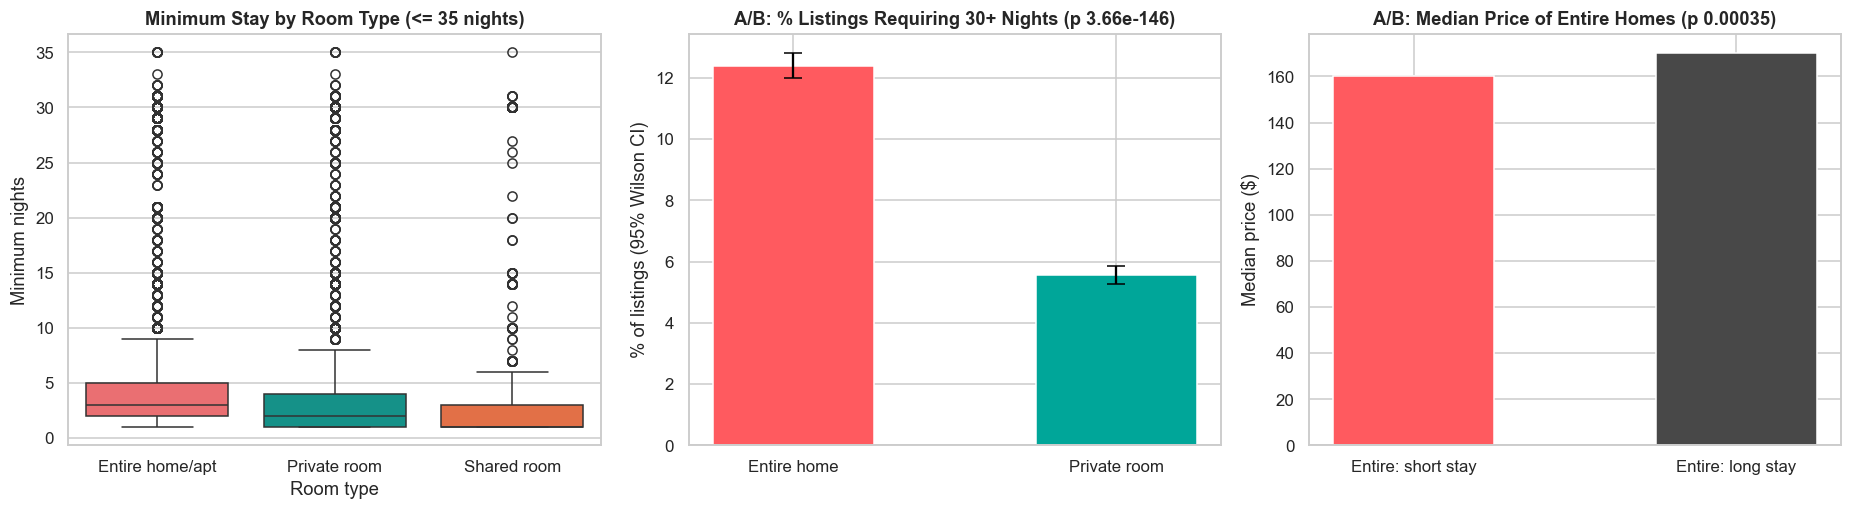

In [32]:
min_stay_summary = df.groupby('room_type')['minimum_nights'].agg(
    median='median', mean='mean', q75=lambda x: x.quantile(0.75),
    pct_7plus=lambda x: (x >= 7).mean() * 100, pct_30plus=lambda x: (x >= 30).mean() * 100).loc[ROOM_ORDER].round(2)
print(f'Share of all listings requiring 30+ nights: {df["long_stay"].mean():.2%}  ({df["long_stay"].sum():,} listings)')
display(min_stay_summary)

# (a) two-proportion z-test: Entire home vs Private room
k = np.array([df.loc[df['room_type'] == 'Entire home/apt', 'long_stay'].sum(), df.loc[df['room_type'] == 'Private room', 'long_stay'].sum()])
n_ = np.array([(df['room_type'] == 'Entire home/apt').sum(), (df['room_type'] == 'Private room').sum()])
p_hat = k / n_
z8, p8 = proportions_ztest(k, n_, alternative='two-sided')
ci8 = confint_proportions_2indep(k[0], n_[0], k[1], n_[1], method='newcomb')
h8 = cohen_h(p_hat[0], p_hat[1])
print(f'\n(a) Entire home: {p_hat[0]:.2%} ({k[0]:,}/{n_[0]:,})  |  Private room: {p_hat[1]:.2%} ({k[1]:,}/{n_[1]:,})')
report('Q8a', 'Share of 30+ night listings equal for Entire home and Private room', 'Two-proportion z-test', z8, p8, "Cohen's h", h8, magnitude(h8, 0.2, 0.5, 0.8))
print(f'95% CI for difference (Entire - Private): [{ci8[0]:+.2%}, {ci8[1]:+.2%}]')

# (b) within Entire homes: long vs short stays
ent = df[df['room_type'] == 'Entire home/apt']
g_long, g_short = ent.loc[ent['long_stay'], 'log_price'], ent.loc[~ent['long_stay'], 'log_price']
t8, p8b = stats.ttest_ind(g_long, g_short, equal_var=False)
d8 = cohen_d(g_long, g_short)
print(f'\n(b) Entire homes: long-stay median ${ent.loc[ent["long_stay"], "price_capped"].median():.0f} (n = {len(g_long):,})  vs  short-stay median ${ent.loc[~ent["long_stay"], "price_capped"].median():.0f} (n = {len(g_short):,})')
report('Q8b', 'Entire homes: long-stay and short-stay log-prices equal', 'A/B Test: Welch t-test', t8, p8b, "Cohen's d", d8, magnitude(d8, 0.2, 0.5, 0.8))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.boxplot(data=df[df['minimum_nights'] <= 35], x='room_type', y='minimum_nights', order=ROOM_ORDER, palette=ROOM_COLORS, ax=axes[0])
axes[0].set_title('Minimum Stay by Room Type (<= 35 nights)'); axes[0].set_xlabel('Room type'); axes[0].set_ylabel('Minimum nights')
axes[1].bar(['Entire home', 'Private room'], p_hat * 100, color=[AB_RED, AB_TEAL], width=0.5)
w = np.array([wilson(a, b) for a, b in zip(k, n_)]) * 100
axes[1].errorbar([0, 1], p_hat * 100, yerr=[p_hat * 100 - w[:, 0], w[:, 1] - p_hat * 100], fmt='none', ecolor='black', capsize=6)
axes[1].set_title(f'A/B: % Listings Requiring 30+ Nights (p {fmt_p(p8)})'); axes[1].set_ylabel('% of listings (95% Wilson CI)')
axes[2].bar(['Entire: short stay', 'Entire: long stay'], [ent.loc[~ent['long_stay'], 'price_capped'].median(), ent.loc[ent['long_stay'], 'price_capped'].median()], color=[AB_RED, AB_GREY], width=0.5)
axes[2].set_title(f'A/B: Median Price of Entire Homes (p {fmt_p(p8b)})'); axes[2].set_ylabel('Median price ($)')
plt.tight_layout()
show('q8_minimum_nights')
RES.update(long_stay_share=float(df['long_stay'].mean()), long_stay_n=int(df['long_stay'].sum()), long_entire=float(p_hat[0]), long_private=float(p_hat[1]),
           z_longstay=float(z8), h_longstay=float(h8), d_longprice=float(d8), t_longprice=float(t8))

In [33]:
md_out(f"""### Interpretation
**Result (a): reject H0.** **{RES['long_stay_share']:.1%}** of all listings ({RES['long_stay_n']:,}) require at least 30 nights. Entire homes do so far more often (**{RES['long_entire']:.1%}**) than private rooms (**{RES['long_private']:.1%}**):
z = {RES['z_longstay']:.1f}, p < 10⁻¹⁰⁰, but the effect size is only **small** (Cohen's h = {RES['h_longstay']:.2f}); the 95% CI of the gap is in the output above.
**Result (b):** within entire homes, long-stay listings are priced only slightly higher (t = {RES['t_longprice']:.2f}, Cohen's d = {RES['d_longprice']:.2f}, **negligible**).

**What it means.** A material minority of the supply is structured as de-facto medium-term rental (the regulatory-compliant form under the Multiple Dwelling Law), concentrated in whole-unit listings. Choosing a 30-night minimum is
a *regulatory and occupancy* decision, **not a pricing premium**; the difference in nightly price is statistically detectable but economically trivial.""")

### Interpretation
**Result (a): reject H0.** **9.2%** of all listings (4,491) require at least 30 nights. Entire homes do so far more often (**12.4%**) than private rooms (**5.6%**):
z = 25.7, p < 10⁻¹⁰⁰, but the effect size is only **small** (Cohen's h = 0.24); the 95% CI of the gap is in the output above.
**Result (b):** within entire homes, long-stay listings are priced only slightly higher (t = 3.58, Cohen's d = 0.07, **negligible**).

**What it means.** A material minority of the supply is structured as de-facto medium-term rental (the regulatory-compliant form under the Multiple Dwelling Law), concentrated in whole-unit listings. Choosing a 30-night minimum is
a *regulatory and occupancy* decision, **not a pricing premium**; the difference in nightly price is statistically detectable but economically trivial.

---
### Question 9: Is Supply Owned by Single-Property or Commercial Hosts, and How Concentrated Is It?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 6 & 12 (Binomial Probability Distribution; Tests of a Proportion) and Lecture 10 (Measures of Dispersion / Inequality).

- **Objective:** Test whether a majority of listings belong to multi-listing hosts, and measure concentration with a Lorenz curve and Gini coefficient.
- **Null Hypothesis ($H_0$):** The proportion of listings owned by multi-listing hosts is $p = 0.50$ (each listing is a fair coin flip between single and multi-listing hosts).
- **Alternative Hypothesis ($H_1$):** $p \neq 0.50$ (exact binomial test).
- **Extension:** Kruskal–Wallis test of price across host types.

Exact binomial test (p0 = 0.50): statistic = 16,582.000,  p-value = < 1e-300  ->  Reject H0
Effect size (Cohen's h) = -0.327  ->  small
Multi-listing share = 33.93%, 95% Wilson CI [33.51%, 34.35%]
Hosts: 37,442   Gini of listings per host: 0.217
Top 1% of hosts (375 hosts) own 10.1% of all listings; the top 10 hosts own 2.6%
Kruskal-Wallis (3 host types): statistic = 1,315.201,  p-value = 2.56e-286  ->  Reject H0
Effect size (epsilon-squared) = 0.027  ->  small


,listings,median,mean
host_type,,,
Single (1),32288,119.0,149.35
Multi (2-5),11792,85.0,120.23
Commercial (6+),4790,129.0,166.36


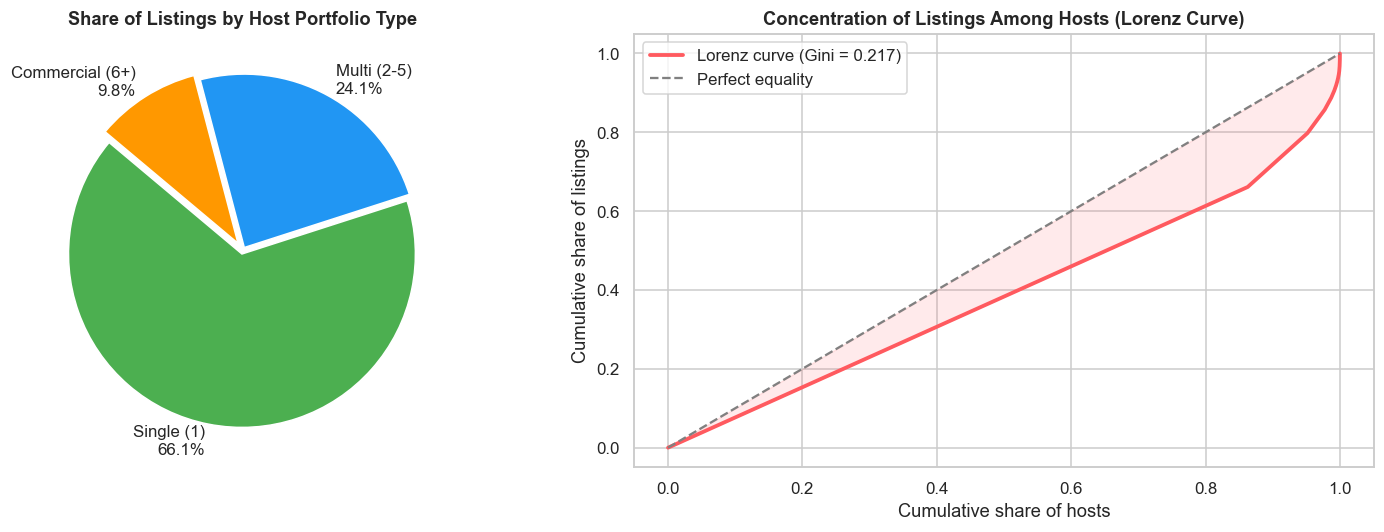

In [34]:
host_counts = df['host_type'].value_counts().loc[HOST_ORDER]
host_share = host_counts / len(df) * 100

n_multi = int((df['calculated_host_listings_count'] >= 2).sum())
btest = stats.binomtest(n_multi, len(df), p=0.5, alternative='two-sided')
p_multi = n_multi / len(df)
ci_multi = wilson(n_multi, len(df))
h9 = cohen_h(p_multi, 0.5)
report('Q9', 'Proportion of listings owned by multi-listing hosts = 0.50', 'Exact binomial test (p0 = 0.50)', n_multi, btest.pvalue,
       "Cohen's h", h9, magnitude(h9, 0.2, 0.5, 0.8))
print(f'Multi-listing share = {p_multi:.2%}, 95% Wilson CI [{ci_multi[0]:.2%}, {ci_multi[1]:.2%}]')

# Market concentration at host level
per_host = df.groupby('host_id').size().sort_values(ascending=False)
G = gini(per_host.values)
top1_share = per_host.head(int(np.ceil(0.01 * len(per_host)))).sum() / len(df)
top10_hosts_share = per_host.head(10).sum() / len(df)
print(f'Hosts: {len(per_host):,}   Gini of listings per host: {G:.3f}')
print(f'Top 1% of hosts ({int(np.ceil(0.01 * len(per_host)))} hosts) own {top1_share:.1%} of all listings; the top 10 hosts own {top10_hosts_share:.1%}')

# Price by host type
ht_groups = [df.loc[df['host_type'] == h, 'price_capped'].values for h in HOST_ORDER]
H9, p9 = stats.kruskal(*ht_groups)
eps9 = epsilon_squared(H9, len(df))
report('Q9b', 'Price distribution identical across host types', 'Kruskal-Wallis (3 host types)', H9, p9, 'epsilon-squared', eps9, magnitude(eps9, 0.01, 0.06, 0.14))
display(df.groupby('host_type')['price_capped'].agg(listings='count', median='median', mean='mean').loc[HOST_ORDER].round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie(host_counts.values, labels=[f'{h}\n{v:.1f}%' for h, v in zip(HOST_ORDER, host_share.values)], colors=['#4CAF50', '#2196F3', '#FF9800'],
            startangle=140, explode=(0.02, 0.02, 0.05), wedgeprops={'edgecolor': 'white'})
axes[0].set_title('Share of Listings by Host Portfolio Type')

sorted_counts = np.sort(per_host.values)
cum_listings = np.insert(np.cumsum(sorted_counts) / sorted_counts.sum(), 0, 0)
cum_hosts = np.linspace(0, 1, len(cum_listings))
axes[1].plot(cum_hosts, cum_listings, color=AB_RED, linewidth=2.5, label=f'Lorenz curve (Gini = {G:.3f})')
axes[1].plot([0, 1], [0, 1], '--', color='grey', label='Perfect equality')
axes[1].fill_between(cum_hosts, cum_listings, cum_hosts, color=AB_RED, alpha=0.12)
axes[1].set_title('Concentration of Listings Among Hosts (Lorenz Curve)')
axes[1].set_xlabel('Cumulative share of hosts'); axes[1].set_ylabel('Cumulative share of listings'); axes[1].legend()
plt.tight_layout()
show('q9_host_concentration')
RES.update(multi_share=float(p_multi), single_share=float(1 - p_multi), commercial_share=float(host_share['Commercial (6+)'] / 100),
           gini_hosts=float(G), top1_share=float(top1_share), n_hosts=int(len(per_host)), H_hosttype=float(H9), eps2_hosttype=float(eps9))

In [35]:
md_out(f"""### Interpretation
**Result: reject H0, in the direction opposite to the popular belief.** Only **{RES['multi_share']:.1%}** of listings belong to hosts with two or more properties; **{RES['single_share']:.1%}** are owned by single-property hosts.
The exact binomial test against p = 0.50 rejects (p < 10⁻³⁰⁰), and the effect is small to moderate (Cohen's h = {h9:.2f}). "Commercial" hosts (6+ listings) account for **{RES['commercial_share']:.1%}** of listings.

The market is **not highly concentrated**: the Gini coefficient of listings per host is only **{RES['gini_hosts']:.2f}**, the top 1% of hosts ({int(np.ceil(0.01 * RES['n_hosts']))} hosts) own **{RES['top1_share']:.1%}** of listings and the ten largest
hosts own {top10_hosts_share:.1%}. Price differs across host types (Kruskal–Wallis H = {RES['H_hosttype']:,.0f}) but the effect is **small** (ε² = {RES['eps2_hosttype']:.3f}); multi-listing (2–5) hosts have the lowest median price.

**What it means.** NYC Airbnb supply is mostly *mom-and-pop*; large operators exist (and matter for regulation, e.g. Local Law 18) but they do not dominate the count of listings.""")

### Interpretation
**Result: reject H0, in the direction opposite to the popular belief.** Only **33.9%** of listings belong to hosts with two or more properties; **66.1%** are owned by single-property hosts.
The exact binomial test against p = 0.50 rejects (p < 10⁻³⁰⁰), and the effect is small to moderate (Cohen's h = -0.33). "Commercial" hosts (6+ listings) account for **9.8%** of listings.

The market is **not highly concentrated**: the Gini coefficient of listings per host is only **0.22**, the top 1% of hosts (375 hosts) own **10.1%** of listings and the ten largest
hosts own 2.6%. Price differs across host types (Kruskal–Wallis H = 1,315) but the effect is **small** (ε² = 0.027); multi-listing (2–5) hosts have the lowest median price.

**What it means.** NYC Airbnb supply is mostly *mom-and-pop*; large operators exist (and matter for regulation, e.g. Local Law 18) but they do not dominate the count of listings.

---
### Question 10 (Linear Algebra & Matrix Concepts): Is the Covariance Matrix of Standardised Features Equal to the Correlation Matrix?

> 📘 **Rubric 2 & 5 \| Course Concept:** Matrix representation of data, Gram matrix $X^TX$, standardisation, covariance identity, eigen-decomposition (PCA).

- **Objective:** Represent the listings as a **design matrix** $X \in \mathbb{R}^{n \times d}$, verify the algebraic identity $\frac{1}{n-1}Z^TZ = \text{Corr}(X)$ where $Z$ is the column-standardised matrix, and use the eigen-decomposition of that matrix to see how many independent dimensions the numeric features contain.
- **Null Hypothesis ($H_0$):** $\left\lVert \frac{1}{n-1}Z^TZ - \text{Corr}(X) \right\rVert_F \neq 0$ (the identity fails).
- **Alternative Hypothesis ($H_1$):** The two matrices are identical (difference at machine precision).
- **Note:** The standardisation must use the sample standard deviation (`ddof = 1`) to match the $n-1$ denominator; with `ddof = 0` the identity holds only up to the factor $(n-1)/n$.

Design matrix X : 48,870 listings x 6 features   |   rank = 6
Gram matrix Z^T Z : 6 x 6  (symmetric: True)
||Cov_algebraic - Corr_empirical||_F = 3.080e-15   ->  identical to machine precision: True
Trace of correlation matrix = 6.0000 (= d = 6)   |   sum of eigenvalues = 6.0000
Condition number = 4.19  (smallest eigenvalue 0.406 -> no exact collinearity)


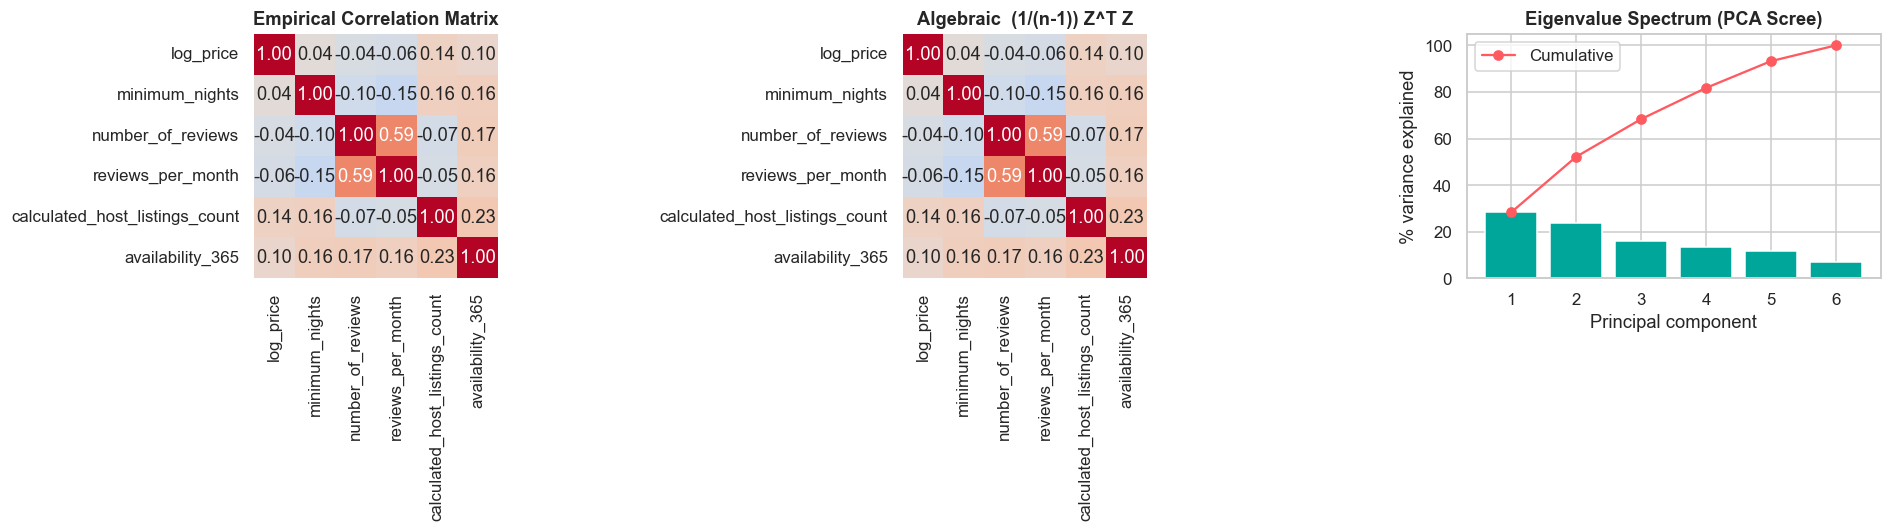

,PC1,PC2
log_price,-0.096,-0.346
minimum_nights,-0.211,-0.446
number_of_reviews,0.662,-0.055
reviews_per_month,0.669,-0.035
calculated_host_listings_count,-0.110,-0.575
availability_365,0.221,-0.588


In [36]:
mat_cols = ['log_price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
X = df[mat_cols].to_numpy(dtype=float)
n, d = X.shape
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)          # column-standardised design matrix

gram = Z.T @ Z                                             # Gram matrix  (d x d)
cov_algebraic = gram / (n - 1)
corr_empirical = np.corrcoef(X, rowvar=False)
frob = np.linalg.norm(cov_algebraic - corr_empirical)

# Eigen-decomposition (PCA) of the correlation matrix
eigvals, eigvecs = np.linalg.eigh(cov_algebraic)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
explained = eigvals / eigvals.sum()

print(f'Design matrix X : {n:,} listings x {d} features   |   rank = {np.linalg.matrix_rank(X)}')
print(f'Gram matrix Z^T Z : {gram.shape[0]} x {gram.shape[1]}  (symmetric: {np.allclose(gram, gram.T)})')
print(f'||Cov_algebraic - Corr_empirical||_F = {frob:.3e}   ->  identical to machine precision: {np.allclose(cov_algebraic, corr_empirical)}')
print(f'Trace of correlation matrix = {np.trace(cov_algebraic):.4f} (= d = {d})   |   sum of eigenvalues = {eigvals.sum():.4f}')
print(f'Condition number = {eigvals[0] / eigvals[-1]:.2f}  (smallest eigenvalue {eigvals[-1]:.3f} -> no exact collinearity)')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(pd.DataFrame(corr_empirical, index=mat_cols, columns=mat_cols), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=axes[0], cbar=False)
axes[0].set_title('Empirical Correlation Matrix')
sns.heatmap(pd.DataFrame(cov_algebraic, index=mat_cols, columns=mat_cols), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=axes[1], cbar=False)
axes[1].set_title('Algebraic  (1/(n-1)) Z^T Z')
axes[2].bar(range(1, d + 1), explained * 100, color=AB_TEAL)
axes[2].plot(range(1, d + 1), np.cumsum(explained) * 100, marker='o', color=AB_RED, label='Cumulative')
axes[2].set_title('Eigenvalue Spectrum (PCA Scree)'); axes[2].set_xlabel('Principal component'); axes[2].set_ylabel('% variance explained'); axes[2].legend()
plt.tight_layout()
show('q10_matrix_algebra')

loadings = pd.DataFrame(eigvecs[:, :2], index=mat_cols, columns=['PC1', 'PC2']).round(3)
display(loadings)
RES.update(frobenius=float(frob), pc1_var=float(explained[0]), pc2_var=float(explained[1]), cond_number=float(eigvals[0] / eigvals[-1]), n_features_matrix=int(d))

In [37]:
md_out(f"""### Interpretation
**Result.** The design matrix has {n:,} rows and {RES['n_features_matrix']} columns and full column rank. After standardising with the sample standard deviation, the algebraic matrix (1/(n−1))·ZᵀZ equals the empirical
correlation matrix to **machine precision** (‖·‖_F = {RES['frobenius']:.1e}), so the alternative hypothesis holds: **standardisation turns the covariance matrix into the correlation matrix**.
The eigen-decomposition shows the first principal component captures **{RES['pc1_var']:.1%}** of the total variance (dominated by the two review variables) and the second **{RES['pc2_var']:.1%}**; the condition number
is only {RES['cond_number']:.1f}, so the numeric features are not collinear enough to destabilise a regression.

**What it means.** The linear-algebra view explains the correlation heatmap in one line: the correlation matrix *is* the Gram matrix of the standardised data. It also tells us the six numeric features carry
roughly {np.searchsorted(np.cumsum(explained), 0.8) + 1} independent dimensions (80% of variance), i.e. little redundancy.""")

### Interpretation
**Result.** The design matrix has 48,870 rows and 6 columns and full column rank. After standardising with the sample standard deviation, the algebraic matrix (1/(n−1))·ZᵀZ equals the empirical
correlation matrix to **machine precision** (‖·‖_F = 3.1e-15), so the alternative hypothesis holds: **standardisation turns the covariance matrix into the correlation matrix**.
The eigen-decomposition shows the first principal component captures **28.3%** of the total variance (dominated by the two review variables) and the second **23.8%**; the condition number
is only 4.2, so the numeric features are not collinear enough to destabilise a regression.

**What it means.** The linear-algebra view explains the correlation heatmap in one line: the correlation matrix *is* the Gram matrix of the standardised data. It also tells us the six numeric features carry
roughly 4 independent dimensions (80% of variance), i.e. little redundancy.

---
### Question 11 (Continuous Probability Distributions): Can Log-Price Be Modelled by a Normal Distribution to Compute Budget Probabilities?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 6 & 11 (Continuous distributions, Normal PDF and CDF) and Lecture 12 (Goodness of fit).

- **Objective:** Fit $\ln(1 + \text{price}) \sim \mathcal{N}(\mu, \sigma^2)$, use the fitted CDF to compute the probability that a listing is a "budget" listing ($\le \$100$), and compare with the empirical frequency.
- **Null Hypothesis ($H_0$):** Log-price follows the fitted Normal distribution.
- **Alternative Hypothesis ($H_1$):** Log-price does not follow the fitted Normal distribution (Kolmogorov–Smirnov).

Kolmogorov-Smirnov goodness of fit: statistic = 0.059,  p-value = 8.88e-147  ->  Reject H0
Effect size (KS distance D) = 0.059  ->  small
Fitted parameters: mu = 4.7327, sigma = 0.6724  (median price implied = $113)
P(price <= $100):        Normal model 43.06%  |  empirical 48.93%  |  absolute error 5.87 pp
P($100 < price <= $200): Normal model 37.13%  |  empirical 33.92%  |  absolute error 3.21 pp
Central 95% interval of the model: $29 - $423  |  empirical share inside it: 95.72%


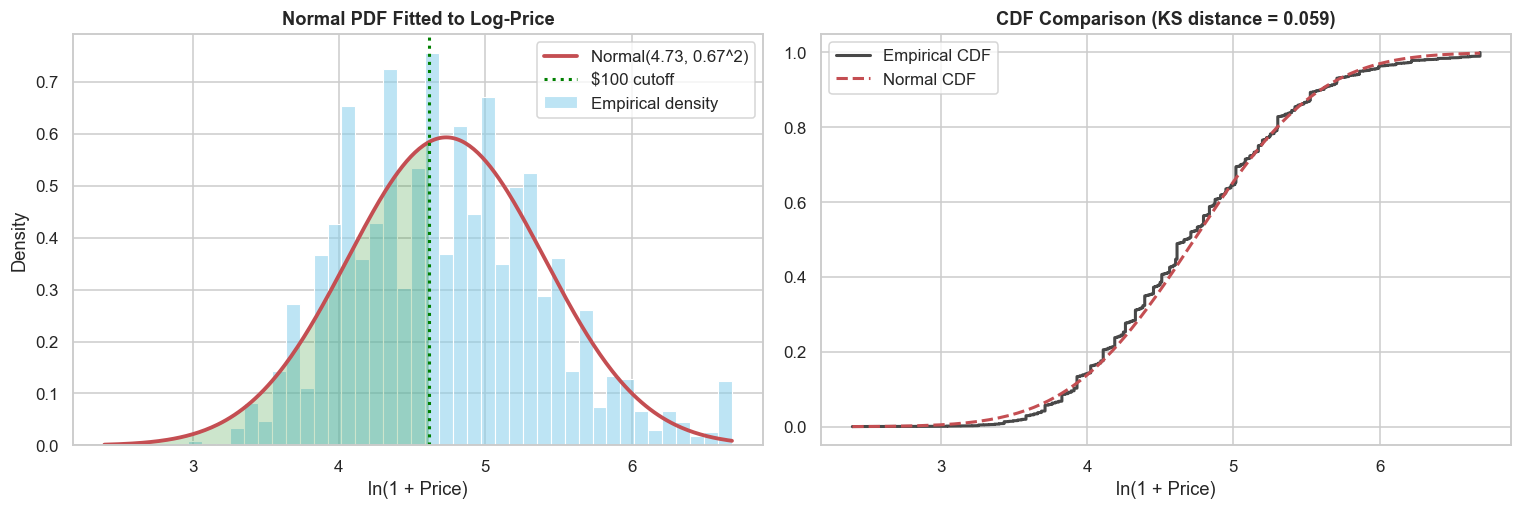

In [38]:
mu_log, sigma_log = float(df['log_price'].mean()), float(df['log_price'].std())
thr = np.log1p(100)
prob_theory = float(stats.norm.cdf(thr, mu_log, sigma_log))
prob_emp = float((df['price_capped'] <= 100).mean())

band_lo, band_hi = np.log1p(100), np.log1p(200)
band_theory = float(stats.norm.cdf(band_hi, mu_log, sigma_log) - stats.norm.cdf(band_lo, mu_log, sigma_log))
band_emp = float(((df['price_capped'] > 100) & (df['price_capped'] <= 200)).mean())
ci95_price = np.expm1([mu_log - 1.96 * sigma_log, mu_log + 1.96 * sigma_log])
inside_emp = float(df['log_price'].between(mu_log - 1.96 * sigma_log, mu_log + 1.96 * sigma_log).mean())

ks_stat, ks_p = stats.kstest(df['log_price'], lambda x: stats.norm.cdf(x, mu_log, sigma_log))
report('Q11', 'Log-price follows the fitted Normal distribution', 'Kolmogorov-Smirnov goodness of fit', ks_stat, ks_p, 'KS distance D', ks_stat, magnitude(ks_stat, 0.05, 0.1, 0.2))

print(f'Fitted parameters: mu = {mu_log:.4f}, sigma = {sigma_log:.4f}  (median price implied = ${np.expm1(mu_log):.0f})')
print(f'P(price <= $100):        Normal model {prob_theory:.2%}  |  empirical {prob_emp:.2%}  |  absolute error {abs(prob_theory - prob_emp) * 100:.2f} pp')
print(f'P($100 < price <= $200): Normal model {band_theory:.2%}  |  empirical {band_emp:.2%}  |  absolute error {abs(band_theory - band_emp) * 100:.2f} pp')
print(f'Central 95% interval of the model: ${ci95_price[0]:.0f} - ${ci95_price[1]:.0f}  |  empirical share inside it: {inside_emp:.2%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x_axis = np.linspace(df['log_price'].min(), df['log_price'].max(), 300)
sns.histplot(df['log_price'], stat='density', bins=45, color='skyblue', alpha=0.55, label='Empirical density', ax=axes[0])
axes[0].plot(x_axis, stats.norm.pdf(x_axis, mu_log, sigma_log), 'r-', lw=2.5, label=f'Normal({mu_log:.2f}, {sigma_log:.2f}^2)')
axes[0].axvline(thr, color='green', linestyle=':', lw=2, label='$100 cutoff')
axes[0].fill_between(x_axis[x_axis <= thr], stats.norm.pdf(x_axis[x_axis <= thr], mu_log, sigma_log), color='green', alpha=0.2)
axes[0].set_title('Normal PDF Fitted to Log-Price'); axes[0].set_xlabel('ln(1 + Price)'); axes[0].legend()

xs = np.sort(df['log_price'].values)
axes[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label='Empirical CDF', color=AB_GREY, lw=2)
axes[1].plot(xs, stats.norm.cdf(xs, mu_log, sigma_log), 'r--', label='Normal CDF', lw=2)
axes[1].set_title(f'CDF Comparison (KS distance = {ks_stat:.3f})'); axes[1].set_xlabel('ln(1 + Price)'); axes[1].legend()
plt.tight_layout()
show('q11_normal_model')
RES.update(mu_log=mu_log, sigma_log=sigma_log, p100_theory=prob_theory, p100_emp=prob_emp, ks_D=float(ks_stat), band_theory=band_theory, band_emp=band_emp)

In [39]:
md_out(f"""### Interpretation
**Result: the Normal model is a good approximation but not an exact fit.** Fitted parameters are μ = {RES['mu_log']:.3f} and σ = {RES['sigma_log']:.3f} (implied median ${np.expm1(RES['mu_log']):.0f}). The model assigns a
**{RES['p100_theory']:.1%}** probability to a budget listing (≤ $100) versus an empirical **{RES['p100_emp']:.1%}**, an error of {abs(RES['p100_theory'] - RES['p100_emp']) * 100:.1f} percentage points; for the $100–$200 band the model says
{RES['band_theory']:.1%} against {RES['band_emp']:.1%} observed. The Kolmogorov–Smirnov test rejects H0 (D = {RES['ks_D']:.3f}, p ≈ 0), which with n = {len(df):,} detects even small discrepancies. The 95% central interval of the model
(${ci95_price[0]:.0f}–${ci95_price[1]:.0f}) contains {inside_emp:.1%} of real listings, very close to the nominal 95%.

**What it means.** A log-Normal price model is **good enough for planning** (e.g. quick budget probabilities and typical price ranges), but it slightly mis-states the lower tail because real prices cluster at round
numbers ($50, $75, $100) and are bounded below. For exact probabilities the **empirical CDF** should be preferred.""")

### Interpretation
**Result: the Normal model is a good approximation but not an exact fit.** Fitted parameters are μ = 4.733 and σ = 0.672 (implied median \$113). The model assigns a
**43.1%** probability to a budget listing (≤ \$100) versus an empirical **48.9%**, an error of 5.9 percentage points; for the \$100–\$200 band the model says
37.1% against 33.9% observed. The Kolmogorov–Smirnov test rejects H0 (D = 0.059, p ≈ 0), which with n = 48,870 detects even small discrepancies. The 95% central interval of the model
(\$29–\$423) contains 95.7% of real listings, very close to the nominal 95%.

**What it means.** A log-Normal price model is **good enough for planning** (e.g. quick budget probabilities and typical price ranges), but it slightly mis-states the lower tail because real prices cluster at round
numbers (\$50, \$75, \$100) and are bounded below. For exact probabilities the **empirical CDF** should be preferred.

---
### Question 12 (Central Limit Theorem): Does the CLT Hold When Sampling from Heavily Skewed Price Data?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 11 & 12 (Sampling distributions, Central Limit Theorem, Standard Error, Confidence Intervals).

- **Objective:** Draw 3,000 random samples of size $n \in \{5, 15, 30, 100\}$ from the (skewed) price population, and check that the sampling distribution of the mean approaches $\mathcal{N}(\mu, \sigma^2/n)$.
- **Null Hypothesis ($H_0$):** Sample means do **not** converge to Normality as $n$ grows (skewness of the sampling distribution stays at the population value).
- **Alternative Hypothesis ($H_1$):** Skewness of the sampling distribution shrinks toward 0 and its spread matches $\sigma/\sqrt{n}$.

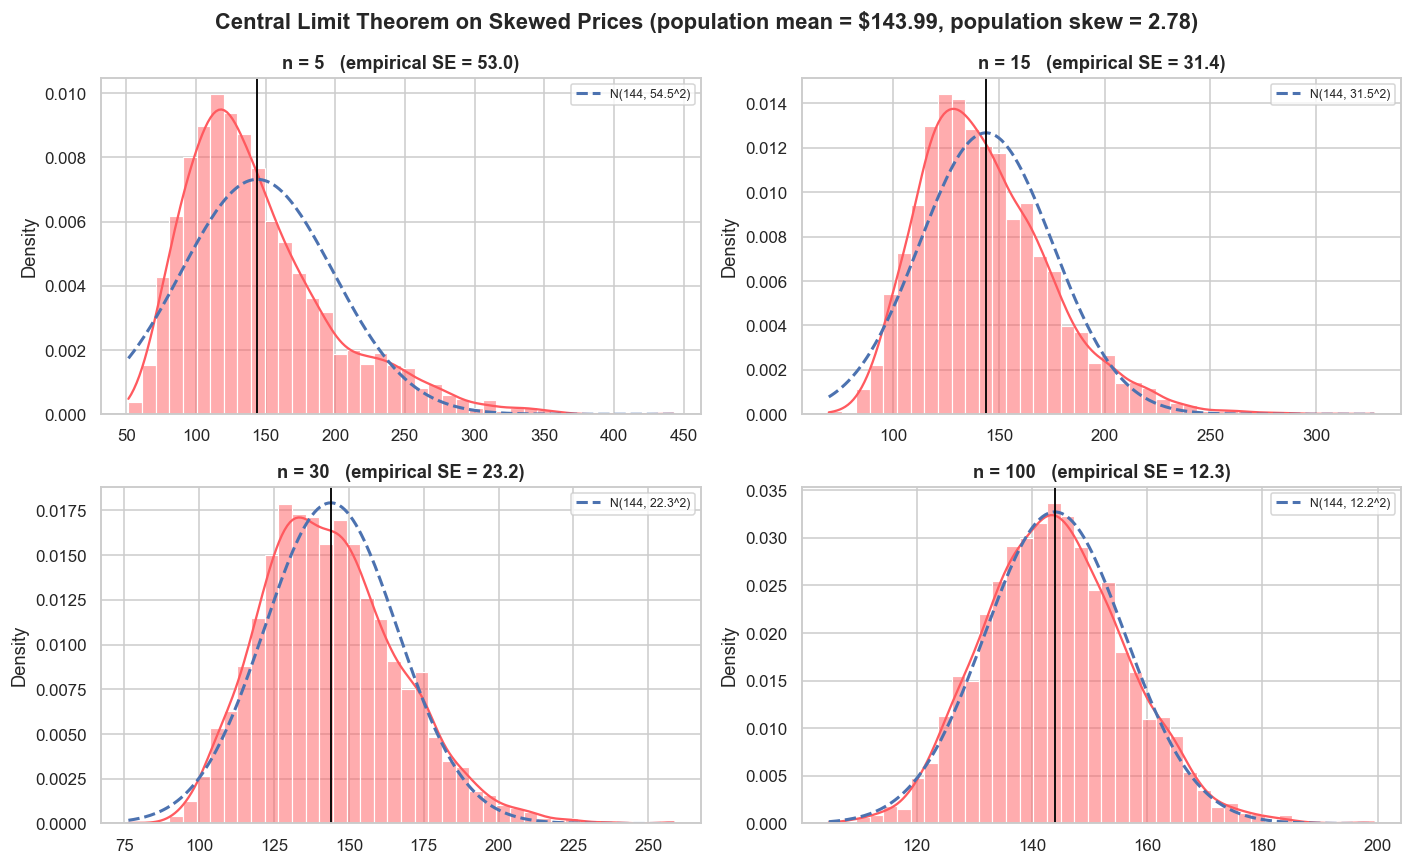

,Theoretical SE (sigma/sqrt(n)),Empirical SE,Mean of sample means,Skewness of means,95% t-CI coverage
n,,,,,
5,54.531,52.988,144.026,1.158,0.869
15,31.484,31.411,143.793,0.891,0.894
30,22.262,23.153,143.938,0.539,0.892
100,12.194,12.311,144.069,0.242,0.931


In [40]:
pop = df['price_capped'].to_numpy(dtype=float)
pop_mean, pop_std = pop.mean(), pop.std(ddof=0)
sample_sizes, trials = [5, 15, 30, 100], 3000
rg = np.random.default_rng(SEED)

clt_rows, means_store = [], {}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, n_s in zip(axes.flat, sample_sizes):
    samples = rg.choice(pop, size=(trials, n_s), replace=True)
    s_means = samples.mean(axis=1)
    means_store[n_s] = s_means
    se_theory = pop_std / np.sqrt(n_s)
    # coverage of the nominal 95% t-interval built from each sample
    s_sd = samples.std(axis=1, ddof=1)
    tcrit = stats.t.ppf(0.975, n_s - 1)
    coverage = np.mean((s_means - tcrit * s_sd / np.sqrt(n_s) <= pop_mean) & (pop_mean <= s_means + tcrit * s_sd / np.sqrt(n_s)))
    clt_rows.append({'n': n_s, 'Theoretical SE (sigma/sqrt(n))': se_theory, 'Empirical SE': s_means.std(ddof=1),
                     'Mean of sample means': s_means.mean(), 'Skewness of means': stats.skew(s_means),
                     '95% t-CI coverage': coverage})
    sns.histplot(s_means, kde=True, stat='density', ax=ax, color=AB_RED, bins=40)
    xc = np.linspace(s_means.min(), s_means.max(), 200)
    ax.plot(xc, stats.norm.pdf(xc, pop_mean, se_theory), 'b--', lw=2, label=f'N({pop_mean:.0f}, {se_theory:.1f}^2)')
    ax.axvline(pop_mean, color='black', lw=1.2)
    ax.set_title(f'n = {n_s}   (empirical SE = {s_means.std(ddof=1):.1f})')
    ax.legend(fontsize=8)
plt.suptitle(f'Central Limit Theorem on Skewed Prices (population mean = ${pop_mean:.2f}, population skew = {stats.skew(pop):.2f})', fontweight='bold')
plt.tight_layout()
show('q12_clt')

clt_df = pd.DataFrame(clt_rows).set_index('n').round(3)
display(clt_df)
RES.update(pop_mean=float(pop_mean), pop_std=float(pop_std), clt_skew={int(k): float(v) for k, v in clt_df['Skewness of means'].items()},
           clt_se_emp100=float(clt_df.loc[100, 'Empirical SE']), clt_se_theory100=float(clt_df.loc[100, 'Theoretical SE (sigma/sqrt(n))']),
           clt_cov={int(k): float(v) for k, v in clt_df['95% t-CI coverage'].items()})

In [41]:
md_out(f"""### Interpretation
**Result: the CLT holds.** Prices are strongly skewed (population skewness {stats.skew(pop):.2f}), yet the sampling distribution of the mean moves toward a symmetric bell shape as n grows: the skewness of the sample means falls
from **{RES['clt_skew'][5]:.2f} (n = 5)** to **{RES['clt_skew'][100]:.2f} (n = 100)**. The empirical standard error matches the theoretical σ/√n (at n = 100: **{RES['clt_se_emp100']:.1f}** vs **{RES['clt_se_theory100']:.1f}**), and the
mean of the sample means is centred on the population mean (${pop_mean:.2f}). The nominal 95% t-interval covers the true mean {RES['clt_cov'][5]:.1%} of the time at n = 5 but **{RES['clt_cov'][100]:.1%} at n = 100**.

**What it means.** Inference about *mean* price (t-tests, ANOVA, regression coefficients) is trustworthy at the sample sizes used in this study (thousands of listings), even though individual prices are far from Normal. For very small
samples (n < 30) of skewed data, intervals under-cover and rank-based or bootstrap methods are safer.""")

### Interpretation
**Result: the CLT holds.** Prices are strongly skewed (population skewness 2.78), yet the sampling distribution of the mean moves toward a symmetric bell shape as n grows: the skewness of the sample means falls
from **1.16 (n = 5)** to **0.24 (n = 100)**. The empirical standard error matches the theoretical σ/√n (at n = 100: **12.3** vs **12.2**), and the
mean of the sample means is centred on the population mean (\$143.99). The nominal 95% t-interval covers the true mean 86.9% of the time at n = 5 but **93.1% at n = 100**.

**What it means.** Inference about *mean* price (t-tests, ANOVA, regression coefficients) is trustworthy at the sample sizes used in this study (thousands of listings), even though individual prices are far from Normal. For very small
samples (n < 30) of skewed data, intervals under-cover and rank-based or bootstrap methods are safer.

---
### Question 13: How Does Price Decay with Distance from Midtown Manhattan?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 2 (Correlation) and Lecture 11 (Empirical Distribution).

- **Objective:** Map price hotspots over latitude/longitude and quantify the price-distance gradient with the **haversine** great-circle distance from Times Square.
- **Null Hypothesis ($H_0$):** $\rho = 0$ between distance to Midtown and price.
- **Alternative Hypothesis ($H_1$):** $\rho \neq 0$ (expected negative).

Spearman rank correlation: statistic = -0.457,  p-value = < 1e-300  ->  Reject H0
Effect size (rho^2) = 0.209  ->  medium


,listings,median,mean
dist_band,,,
"(-0.001, 2.0]",5626,185.0,226.9
"(2.0, 4.0]",7408,160.0,194.6
"(4.0, 6.0]",9371,120.0,153.0
"(6.0, 8.0]",7338,95.0,122.5
"(8.0, 12.0]",13148,80.0,107.9
"(12.0, 16.0]",3964,70.0,90.8
"(16.0, 25.0]",1928,75.0,101.3
"(25.0, 60.0]",87,75.0,137.1


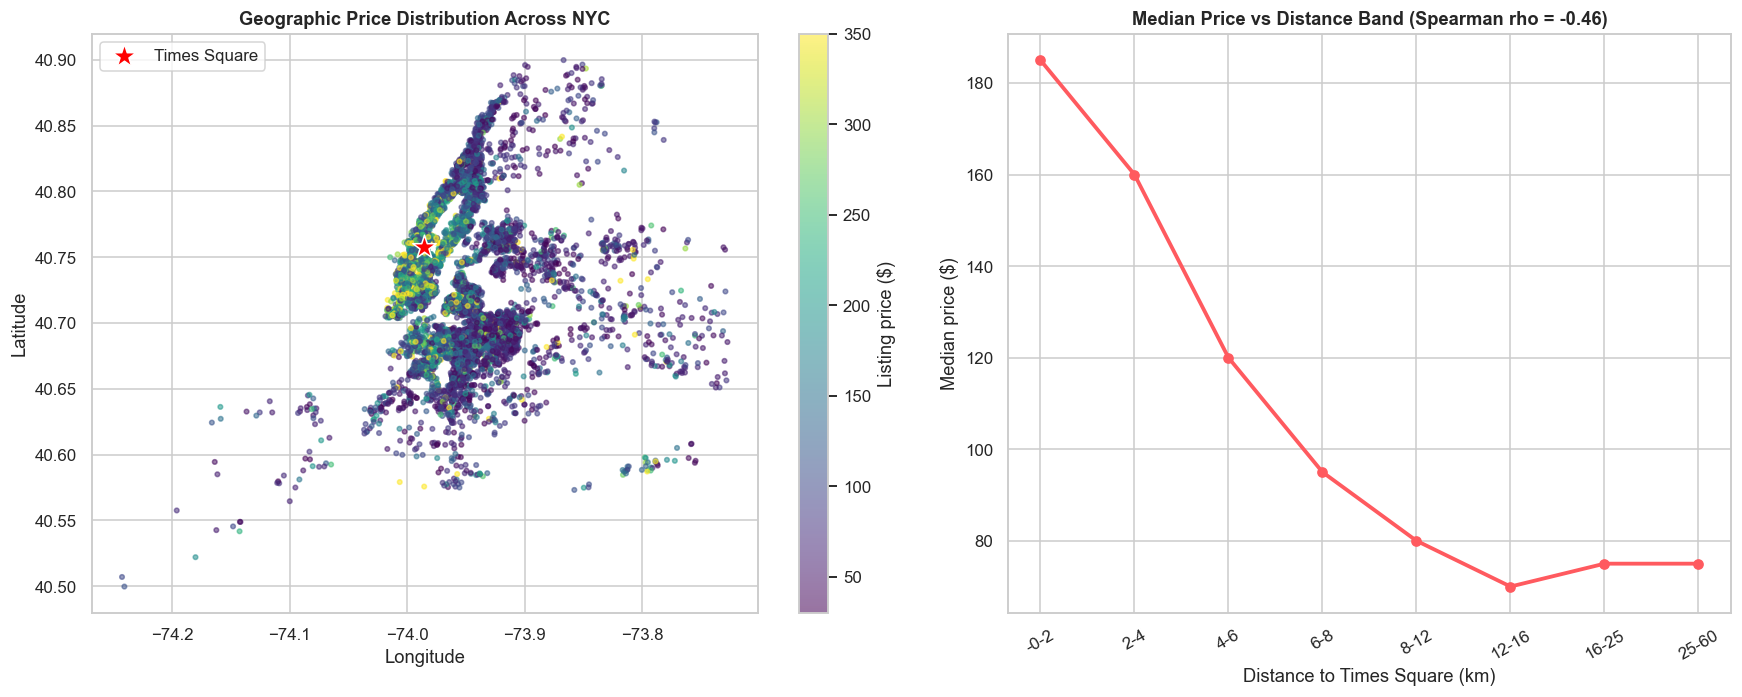

In [42]:
rho13, p13 = stats.spearmanr(df['dist_center_km'], df['price_capped'])
report('Q13', 'No monotonic association between distance to Midtown and price', 'Spearman rank correlation', rho13, p13, 'rho^2', rho13 ** 2, magnitude(rho13, 0.1, 0.3, 0.5))

df['dist_band'] = pd.cut(df['dist_center_km'], bins=[0, 2, 4, 6, 8, 12, 16, 25, 60], include_lowest=True)
band_tbl = df.groupby('dist_band', observed=True)['price_capped'].agg(listings='count', median='median', mean='mean').round(1)
display(band_tbl)

sample_geo = df.sample(8000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1.15, 1]})
sc = axes[0].scatter(sample_geo['longitude'], sample_geo['latitude'], c=sample_geo['price_capped'], cmap='viridis', alpha=0.55, s=9, vmin=30, vmax=350)
plt.colorbar(sc, ax=axes[0], label='Listing price ($)')
axes[0].scatter(*TIMES_SQ[::-1], marker='*', s=260, color='red', edgecolor='white', label='Times Square')
axes[0].set_title('Geographic Price Distribution Across NYC'); axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude'); axes[0].legend()

axes[1].plot(range(len(band_tbl)), band_tbl['median'].values, marker='o', color=AB_RED, lw=2.5)
axes[1].set_xticks(range(len(band_tbl))); axes[1].set_xticklabels([f'{i.left:.0f}-{i.right:.0f}' for i in band_tbl.index], rotation=30)
axes[1].set_title(f'Median Price vs Distance Band (Spearman rho = {rho13:.2f})'); axes[1].set_xlabel('Distance to Times Square (km)'); axes[1].set_ylabel('Median price ($)')
plt.tight_layout()
show('q13_geography')
RES.update(rho_dist=float(rho13), median_0_2km=float(band_tbl['median'].iloc[0]), median_far=float(band_tbl['median'].iloc[-1]))

In [43]:
md_out(f"""### Interpretation
**Result: reject H0 — a clear spatial price gradient.** Spearman ρ between distance to Times Square and price is **{RES['rho_dist']:.2f}** (a *medium* effect, ρ² = {RES['rho_dist'] ** 2:.2f}). The median price is
**${RES['median_0_2km']:.0f}** within 2 km of Midtown and falls monotonically to about **${band_tbl['median'].loc[band_tbl.index[5]]:.0f}** at 12–16 km, after which it flattens (the outer-ring markets of Queens and Staten Island). The map shows bright
(high-price) clusters in Midtown and Lower Manhattan, with dense low-price areas further out.

**What it means.** Location is a **continuous** price driver, not just a five-category borough label: the median price falls steadily with every distance band out to about 16 km. This justifies the
`dist_center_km` feature in the regression (Q17) and is why the borough dummies alone leave residual spatial structure.""")

### Interpretation
**Result: reject H0 — a clear spatial price gradient.** Spearman ρ between distance to Times Square and price is **-0.46** (a *medium* effect, ρ² = 0.21). The median price is
**\$185** within 2 km of Midtown and falls monotonically to about **\$70** at 12–16 km, after which it flattens (the outer-ring markets of Queens and Staten Island). The map shows bright
(high-price) clusters in Midtown and Lower Manhattan, with dense low-price areas further out.

**What it means.** Location is a **continuous** price driver, not just a five-category borough label: the median price falls steadily with every distance band out to about 16 km. This justifies the
`dist_center_km` feature in the regression (Q17) and is why the borough dummies alone leave residual spatial structure.

---
### Question 14: Do Dormant, Part-Time and Year-Round Listings Price Differently?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 13 (Comparing Groups) and Lecture 10 (Cohort summaries).

- **Objective:** Segment the market by annual availability into *Dormant* (0 days), *Part-time* (1–299 days) and *Year-round* (≥ 300 days) cohorts and test whether price differs.
- **Null Hypothesis ($H_0$):** The price distribution is identical across the three availability cohorts.
- **Alternative Hypothesis ($H_1$):** At least one cohort differs (Kruskal–Wallis).

Kruskal-Wallis (3 cohorts): statistic = 271.912,  p-value = 9.02e-60  ->  Reject H0
Effect size (epsilon-squared) = 0.006  ->  negligible

% dormant listings by room type: {'Entire home/apt': 34.9, 'Private room': 37.5, 'Shared room': 25.6}


,listings,median,mean,share %
availability_cohort,,,,
Dormant (0 d),17530,100.0,129.61,35.87
Part-time (1-299 d),23184,110.0,147.53,47.44
Year-round (300+ d),8156,117.0,164.85,16.69


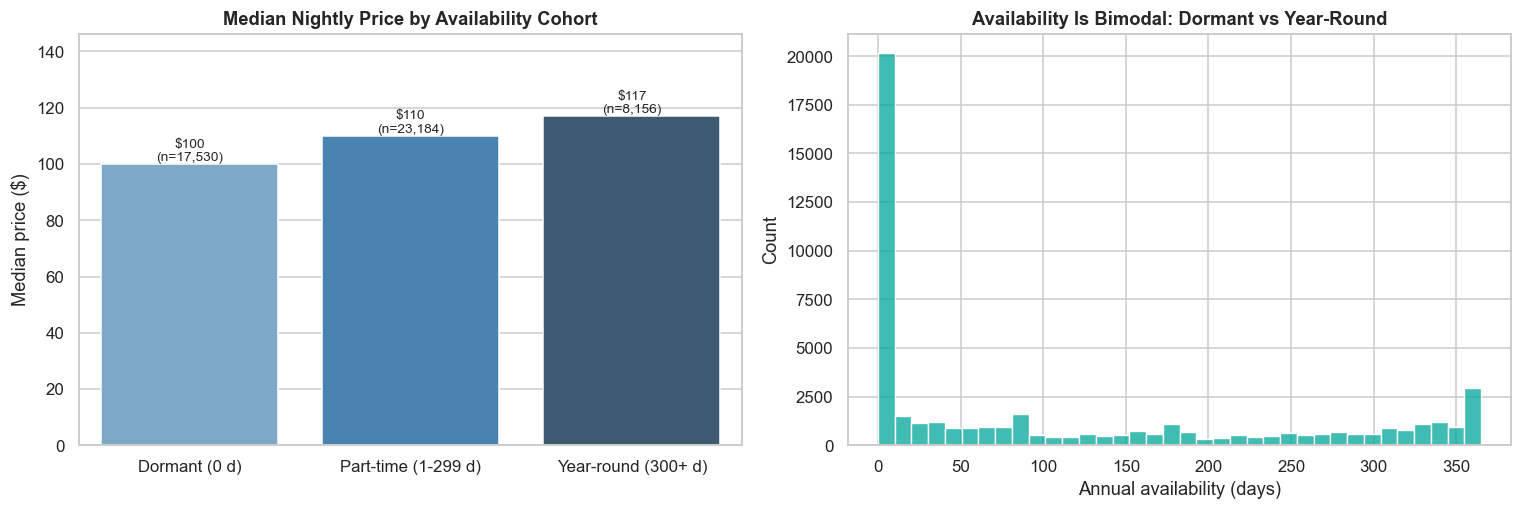

In [44]:
seg = df.groupby('availability_cohort')['price_capped'].agg(listings='count', median='median', mean='mean').loc[COHORT_ORDER]
seg['share %'] = seg['listings'] / len(df) * 100
seg_groups = [df.loc[df['availability_cohort'] == c, 'price_capped'].values for c in COHORT_ORDER]
H14, p14 = stats.kruskal(*seg_groups)
eps14 = epsilon_squared(H14, len(df))
report('Q14', 'Price identical across availability cohorts', 'Kruskal-Wallis (3 cohorts)', H14, p14, 'epsilon-squared', eps14, magnitude(eps14, 0.01, 0.06, 0.14))

zero_by_room = (df.assign(dormant=df['availability_365'] == 0).groupby('room_type')['dormant'].mean().loc[ROOM_ORDER] * 100).round(1)
print('\n% dormant listings by room type:', zero_by_room.to_dict())
display(seg.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(data=seg.reset_index(), x='availability_cohort', y='median', palette='Blues_d', ax=axes[0])
for i, v in enumerate(seg['median']):
    axes[0].text(i, v, f'${v:.0f}\n(n={seg["listings"].iloc[i]:,})', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Median Nightly Price by Availability Cohort'); axes[0].set_xlabel(''); axes[0].set_ylabel('Median price ($)')
axes[0].set_ylim(0, seg['median'].max() * 1.25)
sns.histplot(df['availability_365'], bins=36, color=AB_TEAL, ax=axes[1])
axes[1].set_title('Availability Is Bimodal: Dormant vs Year-Round'); axes[1].set_xlabel('Annual availability (days)')
plt.tight_layout()
show('q14_availability_cohorts')
RES.update(H_cohort=float(H14), eps2_cohort=float(eps14), dormant_share=float(seg.loc['Dormant (0 d)', 'share %'] / 100),
           cohort_median=seg['median'].to_dict())

In [45]:
md_out(f"""### Interpretation
**Result: reject H0, but the effect is negligible.** The market splits into three groups: **{RES['dormant_share']:.1%} dormant** (0 days open), {seg.loc['Part-time (1-299 d)', 'share %']:.1f}% part-time and
{seg.loc['Year-round (300+ d)', 'share %']:.1f}% year-round. Median price rises with availability (${RES['cohort_median']['Dormant (0 d)']:.0f} → ${RES['cohort_median']['Part-time (1-299 d)']:.0f} → ${RES['cohort_median']['Year-round (300+ d)']:.0f}), and the Kruskal–Wallis test is significant
(H = {RES['H_cohort']:,.0f}), but ε² = **{RES['eps2_cohort']:.3f}**: availability cohort explains well under 1% of price variation.

**What it means.** More than a third of listings are effectively **inactive** (0 available days; blocked calendars, long-term tenants or abandoned listings). Any market-size or supply statistic should therefore be computed on *active* listings only, and price
benchmarks should not be built from availability.""")

### Interpretation
**Result: reject H0, but the effect is negligible.** The market splits into three groups: **35.9% dormant** (0 days open), 47.4% part-time and
16.7% year-round. Median price rises with availability (\$100 → \$110 → \$117), and the Kruskal–Wallis test is significant
(H = 272), but ε² = **0.006**: availability cohort explains well under 1% of price variation.

**What it means.** More than a third of listings are effectively **inactive** (0 available days; blocked calendars, long-term tenants or abandoned listings). Any market-size or supply statistic should therefore be computed on *active* listings only, and price
benchmarks should not be built from availability.

---
### Question 15: Do Heavily Reviewed Listings Command a Price Premium (Reputation Premium Hypothesis)?

> 📘 **Rubric 2 & 5 \| Course PPT Reference:** Lecture 2 (Correlation), Lecture 13 (Group comparison) & Lecture 14 (Correlation vs Causation).

- **Objective:** Test whether review volume is linked to price and whether any link persists after controlling for room type and borough.
- **Null Hypothesis ($H_0$):** No monotonic association between number of reviews and price ($\rho = 0$).
- **Alternative Hypothesis ($H_1$):** $\rho \neq 0$.

Spearman rank correlation: statistic = -0.055,  p-value = 7.01e-34  ->  Reject H0
Effect size (rho^2) = 0.003  ->  negligible
Kruskal-Wallis across review groups: H = 249.9, p = 6.91e-54

Controlling for room type and borough (OLS, HC3): +1 log-review = -0.0210 log-price -> doubling reviews = -1.44% price (p = 2.23e-51)


,listings,median,mean
review_group,,,
None (0),10043,120.0,169.79
Low (1-5),14835,101.0,140.96
Medium (6-25),12380,106.5,139.14
High (26+),11612,100.0,130.72


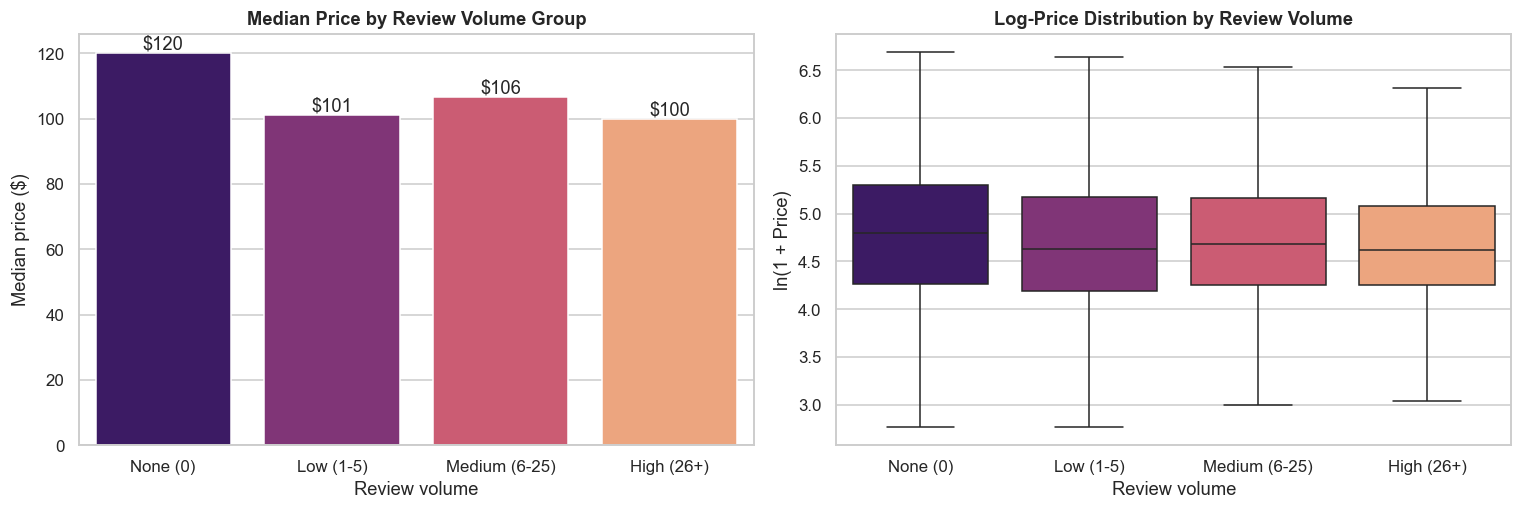

In [46]:
rev_cohort = df.groupby('review_group')['price_capped'].agg(listings='count', median='median', mean='mean').loc[REVIEW_ORDER].round(2)
rho15, p15 = stats.spearmanr(df['number_of_reviews'], df['price_capped'])
report('Q15', 'No monotonic association between number of reviews and price', 'Spearman rank correlation', rho15, p15, 'rho^2', rho15 ** 2, magnitude(rho15, 0.1, 0.3, 0.5))
H15, p15kw = stats.kruskal(*[df.loc[df['review_group'] == g, 'price_capped'].values for g in REVIEW_ORDER])
print(f'Kruskal-Wallis across review groups: H = {H15:,.1f}, p = {fmt_p(p15kw)}')

ols_rev = smf.ols('log_price ~ np.log1p(number_of_reviews) + C(room_type) + C(neighbourhood_group)', data=df).fit(cov_type='HC3')
b_rev = ols_rev.params['np.log1p(number_of_reviews)']
print(f'\nControlling for room type and borough (OLS, HC3): +1 log-review = {b_rev:+.4f} log-price -> doubling reviews = {2 ** b_rev - 1:+.2%} price (p = {fmt_p(ols_rev.pvalues["np.log1p(number_of_reviews)"])})')
display(rev_cohort)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(data=rev_cohort.reset_index(), x='review_group', y='median', palette='magma', ax=axes[0])
for i, v in enumerate(rev_cohort['median']):
    axes[0].text(i, v, f'${v:.0f}', ha='center', va='bottom')
axes[0].set_title('Median Price by Review Volume Group'); axes[0].set_xlabel('Review volume'); axes[0].set_ylabel('Median price ($)')
sns.boxplot(data=df, x='review_group', y='log_price', order=REVIEW_ORDER, palette='magma', showfliers=False, ax=axes[1])
axes[1].set_title('Log-Price Distribution by Review Volume'); axes[1].set_xlabel('Review volume'); axes[1].set_ylabel('ln(1 + Price)')
plt.tight_layout()
show('q15_reputation_premium')
RES.update(rho_reviews_price=float(rho15), coef_reviews_controlled=float(b_rev), H_reviews=float(H15),
           review_group_median=rev_cohort['median'].to_dict(), p_reviews_controlled=float(ols_rev.pvalues['np.log1p(number_of_reviews)']))

In [47]:
md_out(f"""### Interpretation
**Result: reject H0 — but the "reputation premium" is not supported; the association is slightly *negative*.** Spearman ρ between review count and price is **{RES['rho_reviews_price']:.3f}** (ρ² = {RES['rho_reviews_price'] ** 2:.3f}, negligible). Never-reviewed listings have the *highest*
median (${RES['review_group_median']['None (0)']:.0f}) and heavily reviewed ones the lowest (${RES['review_group_median']['High (26+)']:.0f}). Controlling for room type and borough, **doubling the review count is associated with a {2 ** RES['coef_reviews_controlled'] - 1:+.1%} price change**.

**What it means.** Reviews are a *volume-of-bookings* signal, not a price premium: budget listings turn over faster and therefore collect reviews faster, while new or expensive listings have few. This is a clear case of **correlation ≠ causation (Lecture 14)**:
the data reject the belief that more reviews let hosts charge more.""")

### Interpretation
**Result: reject H0 — but the "reputation premium" is not supported; the association is slightly *negative*.** Spearman ρ between review count and price is **-0.055** (ρ² = 0.003, negligible). Never-reviewed listings have the *highest*
median (\$120) and heavily reviewed ones the lowest (\$100). Controlling for room type and borough, **doubling the review count is associated with a -1.4% price change**.

**What it means.** Reviews are a *volume-of-bookings* signal, not a price premium: budget listings turn over faster and therefore collect reviews faster, while new or expensive listings have few. This is a clear case of **correlation ≠ causation (Lecture 14)**:
the data reject the belief that more reviews let hosts charge more.

---
### Question 16: How Sensitive Are the Conclusions to Outliers (Raw vs Capped vs Log Price)?

> 📘 **Rubric 2 & 3 \| Course PPT Reference:** Lecture 10 (Outliers, IQR, robust vs non-robust statistics) and Lecture 13 (Robustness of $t$-tests).

- **Objective:** Show how winsorisation and the log transform change the summary statistics and whether the headline A/B conclusion of Q3 depends on this choice.
- **Null Hypothesis ($H_0$):** The Entire-home vs Private-room conclusion is unchanged under every price scale (raw, capped, log).
- **Alternative Hypothesis ($H_1$):** The conclusion depends on the outlier treatment.

,Raw price ($),Capped price ($799),Log price ln(1+P)
Count,48870.00,48870.00,48870.00
Mean,152.76,143.99,4.73
Median,106.00,106.00,4.67
Std Dev,240.20,121.94,0.67
Min,10.00,10.00,2.40
Max,10000.00,799.00,6.68
Skewness,19.12,2.78,0.37
Kurtosis,585.52,10.15,0.01


,Price scale,Welch t,p-value,Cohen's d,Mean-difference significant?
0,Raw price ($),58.645,0.0,0.520,True
1,Capped price ($799),116.698,0.0,1.035,True
2,Log price ln(1+P),175.878,0.0,1.607,True


Bootstrap 95% CI of mean (raw)    : [$150.65, $154.85]  width = $4.20
Bootstrap 95% CI of mean (capped) : [$142.90, $145.09]  width = $2.19
Bootstrap 95% CI of median (raw)  : [$105.00, $109.00]  (the median is outlier-resistant)


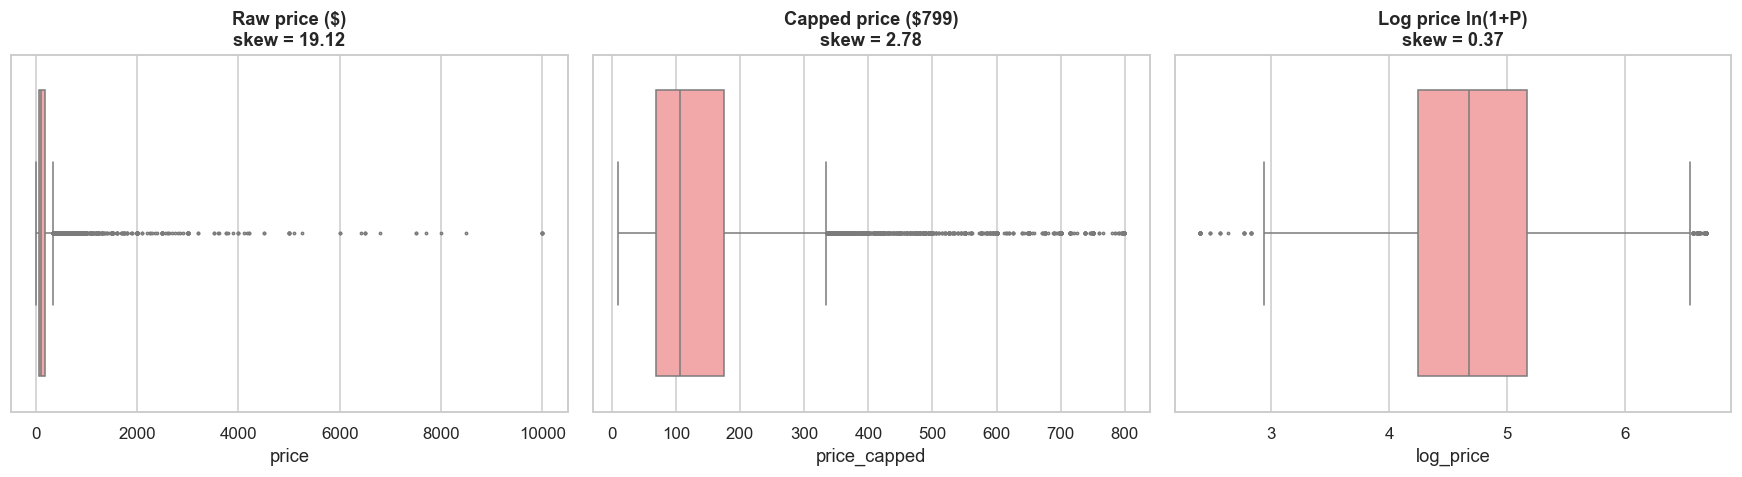

In [48]:
scales = {'Raw price ($)': 'price', f'Capped price (${price_cap:,.0f})': 'price_capped', 'Log price ln(1+P)': 'log_price'}
outlier_summary = pd.DataFrame({
    label: [len(df), df[c].mean(), df[c].median(), df[c].std(), df[c].min(), df[c].max(), df[c].skew(), df[c].kurt()]
    for label, c in scales.items()
}, index=['Count', 'Mean', 'Median', 'Std Dev', 'Min', 'Max', 'Skewness', 'Kurtosis']).round(2)
display(outlier_summary)

rows = []
for label, c in scales.items():
    a, b = df.loc[df['room_type'] == 'Entire home/apt', c], df.loc[df['room_type'] == 'Private room', c]
    t_, p_ = stats.ttest_ind(a, b, equal_var=False)
    rows.append({'Price scale': label, 'Welch t': t_, 'p-value': p_, "Cohen's d": cohen_d(a, b), 'Mean-difference significant?': p_ < ALPHA})
robust_tbl = pd.DataFrame(rows).round(3)
display(robust_tbl)

ci_raw = bootstrap_ci(df['price'].values, np.mean, n_boot=1000)
ci_cap = bootstrap_ci(df['price_capped'].values, np.mean, n_boot=1000)
ci_med = bootstrap_ci(df['price'].values, np.median, n_boot=1000)
print(f'Bootstrap 95% CI of mean (raw)    : [${ci_raw[0]:.2f}, ${ci_raw[1]:.2f}]  width = ${ci_raw[1] - ci_raw[0]:.2f}')
print(f'Bootstrap 95% CI of mean (capped) : [${ci_cap[0]:.2f}, ${ci_cap[1]:.2f}]  width = ${ci_cap[1] - ci_cap[0]:.2f}')
print(f'Bootstrap 95% CI of median (raw)  : [${ci_med[0]:.2f}, ${ci_med[1]:.2f}]  (the median is outlier-resistant)')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (label, c) in zip(axes, scales.items()):
    sns.boxplot(x=df[c], ax=ax, color='#FF9A9D', fliersize=1.5)
    ax.set_title(f'{label}\nskew = {df[c].skew():.2f}')
plt.tight_layout()
show('q16_outlier_sensitivity')
RES.update(ci_width_raw=float(ci_raw[1] - ci_raw[0]), ci_width_cap=float(ci_cap[1] - ci_cap[0]), d_raw=float(robust_tbl.iloc[0]["Cohen's d"]),
           d_cap=float(robust_tbl.iloc[1]["Cohen's d"]), d_log=float(robust_tbl.iloc[2]["Cohen's d"]), cap_n=int((df['price'] > price_cap).sum()))

In [49]:
md_out(f"""### Interpretation
**Result.** Winsorising only {RES['cap_n']:,} listings ({RES['cap_n'] / len(df):.1%}) cuts the standard deviation from ${df['price'].std():.0f} to ${df['price_capped'].std():.0f} and the bootstrap confidence interval of the mean from a width of
**${RES['ci_width_raw']:.2f}** to **${RES['ci_width_cap']:.2f}**, whereas the median is unaffected (${df['price'].median():.0f} on both scales). The **conclusion of Q3 is robust**: the Entire-home vs Private-room difference is significant under raw, capped and log prices; only the
*size* of the standardised effect changes (Cohen's d = {RES['d_raw']:.2f} raw, {RES['d_cap']:.2f} capped, {RES['d_log']:.2f} log), because extreme prices inflate the variance on the raw scale.

**What it means.** The outlier treatment changes the *precision* of estimates but never the *direction or significance* of the findings. Reporting the effect on the log scale (which also satisfies the Normality assumptions) is the most defensible choice, and the
median remains the safest descriptive statistic.""")

### Interpretation
**Result.** Winsorising only 474 listings (1.0%) cuts the standard deviation from \$240 to \$122 and the bootstrap confidence interval of the mean from a width of
**\$4.20** to **\$2.19**, whereas the median is unaffected (\$106 on both scales). The **conclusion of Q3 is robust**: the Entire-home vs Private-room difference is significant under raw, capped and log prices; only the
*size* of the standardised effect changes (Cohen's d = 0.52 raw, 1.03 capped, 1.61 log), because extreme prices inflate the variance on the raw scale.

**What it means.** The outlier treatment changes the *precision* of estimates but never the *direction or significance* of the findings. Reporting the effect on the log scale (which also satisfies the Normality assumptions) is the most defensible choice, and the
median remains the safest descriptive statistic.

---
### 9.17 Hypothesis-Test Register with Multiple-Testing Correction

> 📘 **Rubric 5 \| Course PPT Reference:** Lecture 12 (Type I error control) – running many tests inflates the family-wise error rate, so p-values are adjusted with the **Holm–Bonferroni** step-down procedure.

In [50]:
test_reg = pd.DataFrame(TESTS)
test_reg['Holm-adj. p'] = multipletests(test_reg['p-value'].clip(lower=1e-320), method='holm')[1]
test_reg['Decision (Holm)'] = np.where(test_reg['Holm-adj. p'] < ALPHA, 'Reject H0', 'Fail to reject H0')
test_reg['p-value'] = test_reg['p-value'].map(fmt_p)
test_reg['Holm-adj. p'] = test_reg['Holm-adj. p'].map(fmt_p)
test_reg['Statistic'] = test_reg['Statistic'].round(3)
test_reg['Effect value'] = test_reg['Effect value'].round(3)
test_reg_display = test_reg[['Question', 'Test', 'Statistic', 'p-value', 'Holm-adj. p', 'Effect size', 'Effect value', 'Magnitude', 'Decision (Holm)']]
display(test_reg_display)
print(f"{(test_reg['Decision (Holm)'] == 'Reject H0').sum()} of {len(test_reg)} hypotheses remain rejected after Holm correction.")
RES['n_tests'] = int(len(test_reg))
RES['n_rejected_holm'] = int((test_reg['Decision (Holm)'] == 'Reject H0').sum())

,Question,Test,Statistic,p-value,Holm-adj. p,Effect size,Effect value,Magnitude,Decision (Holm)
0,Q2,Welch ANOVA,1973.267,< 1e-300,< 1e-300,eta-squared,0.136,medium,Reject H0
1,Q3,A/B Test: Welch t-test,175.878,< 1e-300,< 1e-300,Cohen's d,1.607,large,Reject H0
2,Q4,Chi-square independence (dof = 8),1557.952,< 1e-300,< 1e-300,Cramer's V,0.126,small,Reject H0
3,Q5,Kruskal-Wallis (123 groups),14256.036,< 1e-300,< 1e-300,epsilon-squared,0.297,large,Reject H0
4,Q6,Spearman rank correlation,0.086,3.46e-81,1.38e-80,rho^2 (shared rank variance),0.007,negligible,Reject H0
5,Q7,"Spearman (reviewed listings, n = 38,827)",0.706,< 1e-300,< 1e-300,rho^2,0.499,large,Reject H0
6,Q8a,Two-proportion z-test,25.745,3.66e-146,1.83e-145,Cohen's h,0.243,small,Reject H0
7,Q8b,A/B Test: Welch t-test,3.578,0.00035,0.00035,Cohen's d,0.066,negligible,Reject H0
8,Q9,Exact binomial test (p0 = 0.50),16582.000,< 1e-300,< 1e-300,Cohen's h,-0.327,small,Reject H0
9,Q9b,Kruskal-Wallis (3 host types),1315.201,2.56e-286,1.79e-285,epsilon-squared,0.027,small,Reject H0


14 of 14 hypotheses remain rejected after Holm correction.


---
## 10. Predictive Modeling & Pricing Insights

### Question 17: Can Nightly Price Be Predicted from Pre-Listing Information?

> 📘 **Rubric 6 \| Course PPT Reference:** Lectures 1, 2, 3, 7 (Multiple Linear Regression / OLS, Residual Diagnostics, and Predictions).

- **Technique Chosen:** **Multiple Linear Regression (OLS) predicting `log_price`**
- **Reason for Selection:** Direct interpretability for hosts, exact coefficients that translate into percentage price effects, and testable Gauss–Markov assumptions. Ridge, Random Forest and Gradient Boosting are used as benchmarks.
- **Model Equation:**
  $$\ln(1+\text{price}) = \beta_0 + \beta_1(\text{room type}) + \beta_2(\text{borough}) + \beta_3(\text{dist\_center\_km}) + \beta_4\ln(1+\text{min\_nights}) + \beta_5\ln(1+\text{reviews}) + \beta_6(\text{reviews/month}) + \beta_7\ln(\text{host\_listings}) + \beta_8(\text{availability}) + \varepsilon$$
- **Leakage prevention:** 80 : 20 random train/test split with a fixed seed; every statistic that the model learns (coefficients, scalers, tuned alphas) is estimated on the training rows only. Predictors are limited to attributes a host knows at listing time.
- **Evaluation Metrics (Lecture 7):** $R^2$ and RMSE on the log scale; MAE in dollars on the unseen 20 % test set; 5-fold cross-validated $R^2$ on the training set.

### 10.1 Feature Matrix and Train/Test Split

In [51]:
def build_design(d):
    """Design matrix of pre-listing features. Reference categories: Manhattan, Entire home/apt."""
    X = pd.DataFrame(index=d.index)
    X['room_private'] = (d['room_type'] == 'Private room').astype(int)
    X['room_shared'] = (d['room_type'] == 'Shared room').astype(int)
    for b in ['Brooklyn', 'Queens', 'Bronx', 'Staten Island']:
        X['boro_' + b.lower().replace(' ', '_')] = (d['neighbourhood_group'] == b).astype(int)
    X['dist_center_km'] = d['dist_center_km']
    X['log_min_nights'] = np.log1p(d['minimum_nights'])
    X['log_reviews'] = np.log1p(d['number_of_reviews'])
    X['reviews_per_month'] = d['reviews_per_month']
    X['log_host_listings'] = np.log(d['calculated_host_listings_count'])
    X['availability_365'] = d['availability_365']
    return X

X_all = build_design(df)
y_all = df['log_price']

train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=SEED)
X_train, X_test = X_all.loc[train_idx], X_all.loc[test_idx]
y_train, y_test = y_all.loc[train_idx], y_all.loc[test_idx]
dollar_test = df.loc[test_idx, 'price_capped']

print(f'Train: {len(X_train):,} listings   |   Test (unseen): {len(X_test):,} listings')
print('Features:', list(X_train.columns))
X_train.describe().T.round(2)

Train: 39,096 listings   |   Test (unseen): 9,774 listings
Features: ['room_private', 'room_shared', 'boro_brooklyn', 'boro_queens', 'boro_bronx', 'boro_staten_island', 'dist_center_km', 'log_min_nights', 'log_reviews', 'reviews_per_month', 'log_host_listings', 'availability_365']


,count,mean,std,min,25%,50%,75%,max
room_private,39096.0,0.46,0.50,0.00,0.00,0.00,1.00,1.00
room_shared,39096.0,0.02,0.15,0.00,0.00,0.00,0.00,1.00
boro_brooklyn,39096.0,0.41,0.49,0.00,0.00,0.00,1.00,1.00
boro_queens,39096.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00
boro_bronx,39096.0,0.02,0.15,0.00,0.00,0.00,0.00,1.00
boro_staten_island,39096.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00
dist_center_km,39096.0,7.11,4.44,0.07,3.81,6.40,9.41,35.23
log_min_nights,39096.0,1.50,0.87,0.69,0.69,1.39,1.79,5.90
log_reviews,39096.0,1.99,1.56,0.00,0.69,1.79,3.18,6.45
reviews_per_month,39096.0,1.09,1.61,0.00,0.04,0.37,1.59,58.50


### 10.2 Checking Multicollinearity with VIF (Rubric 6 Assumptions)

Latitude and longitude are tested as candidate predictors first. Because they overlap with the borough dummies and with the distance feature, we inspect the VIF before deciding which location representation to keep.

In [52]:
def compute_vif(X):
    Xc = sm.add_constant(X)
    return pd.DataFrame({'Feature': X.columns,
                         'VIF': [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]}).round(2)

X_cand = X_train.copy()
X_cand['latitude'] = df.loc[train_idx, 'latitude']
X_cand['longitude'] = df.loc[train_idx, 'longitude']
vif_cand = compute_vif(X_cand).sort_values('VIF', ascending=False).reset_index(drop=True)
vif_final = compute_vif(X_train).sort_values('VIF', ascending=False).reset_index(drop=True)

print('VIF with raw latitude/longitude added as candidates:')
display(vif_cand.head(6))
print(f"Decision: raw coordinates are redundant with borough + distance to Midtown (max VIF = {vif_cand['VIF'].max():.1f}) -> excluded from the linear model.")
print('\nFinal linear-model VIFs (rule of thumb: VIF < 5 safe, > 10 severe):')
display(vif_final)
RES.update(vif_max_candidate=float(vif_cand['VIF'].max()), vif_max_final=float(vif_final['VIF'].max()))

VIF with raw latitude/longitude added as candidates:


,Feature,VIF
0,longitude,4.17
1,latitude,3.36
2,dist_center_km,3.15
3,boro_brooklyn,3.07
4,boro_queens,2.73
5,reviews_per_month,1.79


Decision: raw coordinates are redundant with borough + distance to Midtown (max VIF = 4.2) -> excluded from the linear model.

Final linear-model VIFs (rule of thumb: VIF < 5 safe, > 10 severe):


,Feature,VIF
0,dist_center_km,1.88
1,reviews_per_month,1.79
2,log_reviews,1.75
3,boro_brooklyn,1.70
4,boro_queens,1.53
5,log_host_listings,1.36
6,availability_365,1.32
7,log_min_nights,1.30
8,boro_bronx,1.21
9,boro_staten_island,1.17


### 10.3 Model Fitting: Multiple Linear Regression (OLS) (Lecture 1, 2, 3, 7)

Inference uses **HC3 heteroscedasticity-robust standard errors** so that p-values stay valid even if the Breusch–Pagan test (next step) rejects constant variance.

In [53]:
ols_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
ols_hc3 = sm.OLS(y_train, sm.add_constant(X_train)).fit(cov_type='HC3')
print(ols_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.536
Model:                            OLS   Adj. R-squared:                  0.536
Method:                 Least Squares   F-statistic:                     3724.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:43:56   Log-Likelihood:                -24960.
No. Observations:               39096   AIC:                         4.995e+04
Df Residuals:                   39083   BIC:                         5.006e+04
Df Model:                          12                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  5.6170      0

### 10.4 Residual Diagnostics (Lecture 7 Assumptions)

,Assumption,Test,Result,Verdict
0,No multicollinearity,Variance Inflation Factor,max VIF = 1.88,Satisfied
1,Linearity,Residuals vs fitted (plot),mean residual = -1.8e-14; see plot,Approximately satisfied
2,Homoscedasticity,Breusch-Pagan LM,"LM = 789.8, p = 2.6e-161",Violated -> HC3 robust SE used
3,Independence of errors,Durbin-Watson,DW = 2.000,Satisfied
4,Normality of residuals,Jarque-Bera / skew / kurtosis,"JB p = < 1e-300, skew = 0.84, kurtosis = 5.63",Mild departure -> CLT justifies inference (n l...
5,No unduly influential points,Cook's distance > 4/n,"1,999 points (5.1%); max D = 0.009",Acceptable


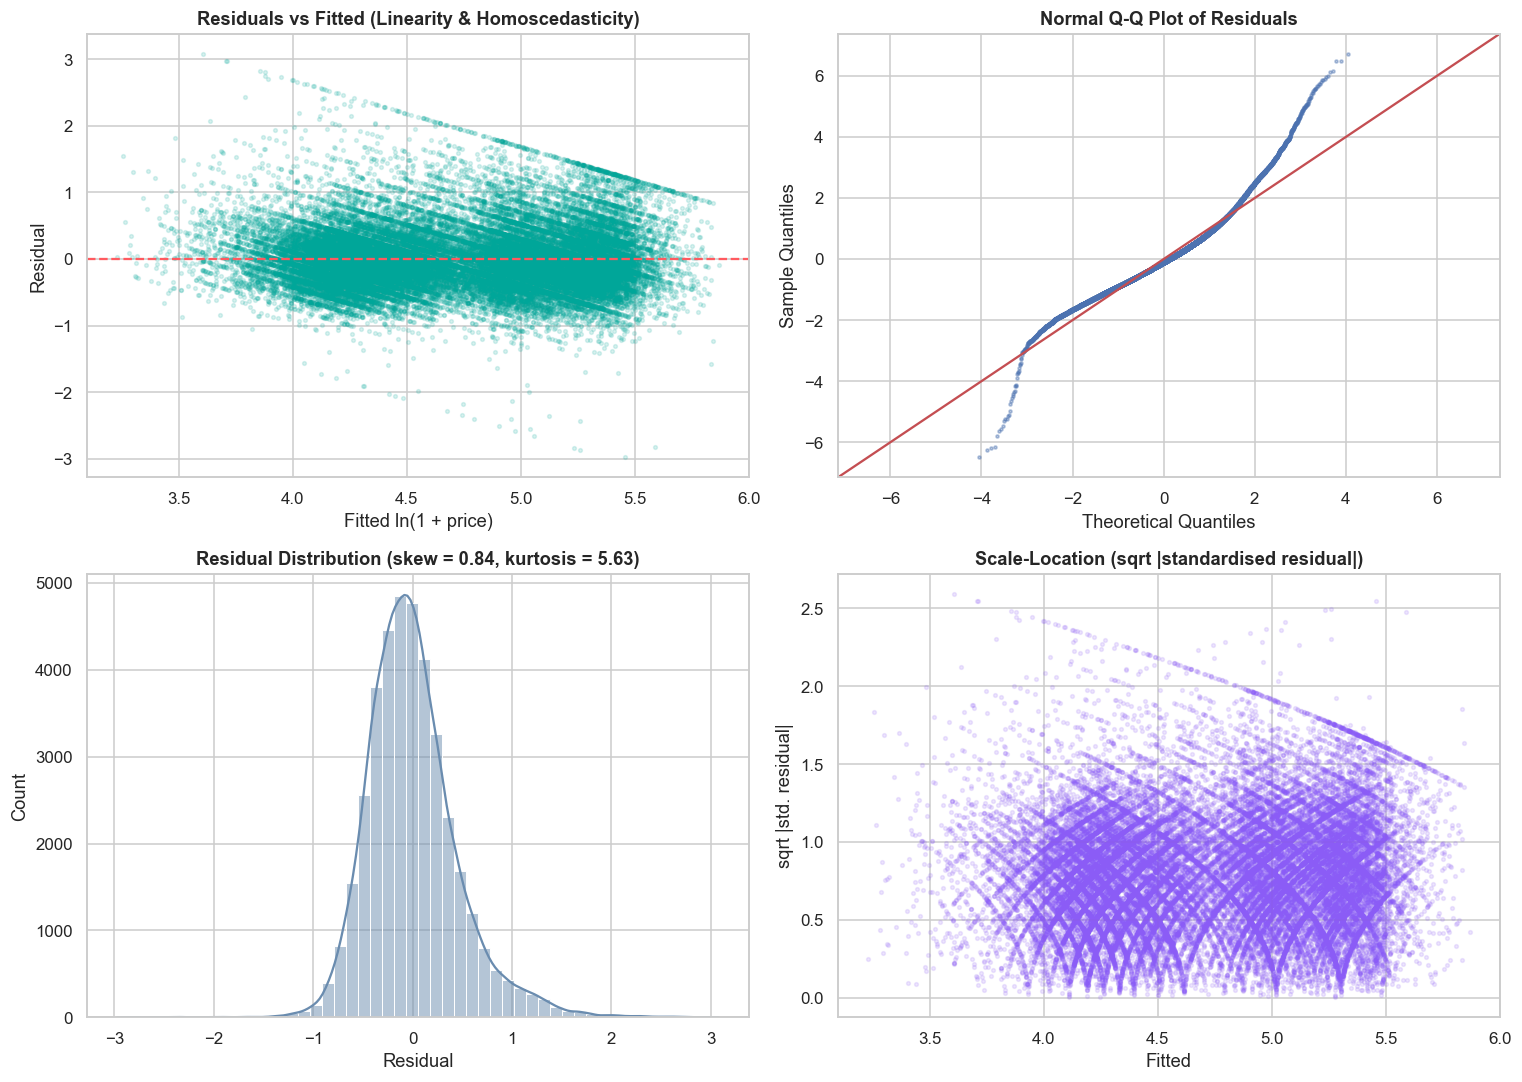

In [54]:
resid = ols_model.resid
fitted = ols_model.fittedvalues
Xc_train = sm.add_constant(X_train)

bp_lm, bp_p, _, _ = het_breuschpagan(resid, Xc_train)
dw = durbin_watson(resid)
jb_stat, jb_p, resid_skew, resid_kurt = jarque_bera(resid)
cooks = ols_model.get_influence().cooks_distance[0]
n_infl = int((cooks > 4 / len(X_train)).sum())

diag_table = pd.DataFrame([
    {'Assumption': 'No multicollinearity', 'Test': 'Variance Inflation Factor', 'Result': f"max VIF = {vif_final['VIF'].max():.2f}",
     'Verdict': 'Satisfied' if vif_final['VIF'].max() < 5 else 'Monitor'},
    {'Assumption': 'Linearity', 'Test': 'Residuals vs fitted (plot)', 'Result': f'mean residual = {resid.mean():.1e}; see plot',
     'Verdict': 'Approximately satisfied'},
    {'Assumption': 'Homoscedasticity', 'Test': 'Breusch-Pagan LM', 'Result': f'LM = {bp_lm:.1f}, p = {fmt_p(bp_p)}',
     'Verdict': 'Satisfied' if bp_p > ALPHA else 'Violated -> HC3 robust SE used'},
    {'Assumption': 'Independence of errors', 'Test': 'Durbin-Watson', 'Result': f'DW = {dw:.3f}',
     'Verdict': 'Satisfied' if 1.5 <= dw <= 2.5 else 'Monitor'},
    {'Assumption': 'Normality of residuals', 'Test': 'Jarque-Bera / skew / kurtosis', 'Result': f'JB p = {fmt_p(jb_p)}, skew = {resid_skew:.2f}, kurtosis = {resid_kurt:.2f}',
     'Verdict': 'Mild departure -> CLT justifies inference (n large)' if abs(resid_skew) < 1 else 'Departure'},
    {'Assumption': 'No unduly influential points', 'Test': "Cook's distance > 4/n", 'Result': f'{n_infl:,} points ({n_infl / len(X_train):.1%}); max D = {cooks.max():.3f}',
     'Verdict': 'Acceptable' if cooks.max() < 1 else 'Investigate'},
])
display(diag_table)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].scatter(fitted, resid, alpha=0.15, s=6, color=AB_TEAL)
axes[0, 0].axhline(0, color=AB_RED, ls='--')
axes[0, 0].set_title('Residuals vs Fitted (Linearity & Homoscedasticity)'); axes[0, 0].set_xlabel('Fitted ln(1 + price)'); axes[0, 0].set_ylabel('Residual')
sm.qqplot(resid, line='45', fit=True, ax=axes[0, 1], markersize=2, alpha=0.4)
axes[0, 1].set_title('Normal Q-Q Plot of Residuals')
sns.histplot(resid, kde=True, bins=50, ax=axes[1, 0], color='#6a8caf')
axes[1, 0].set_title(f'Residual Distribution (skew = {resid_skew:.2f}, kurtosis = {resid_kurt:.2f})'); axes[1, 0].set_xlabel('Residual')
axes[1, 1].scatter(fitted, np.sqrt(np.abs(resid / resid.std())), alpha=0.15, s=6, color='#8B5CF6')
axes[1, 1].set_title('Scale-Location (sqrt |standardised residual|)'); axes[1, 1].set_xlabel('Fitted'); axes[1, 1].set_ylabel('sqrt |std. residual|')
plt.tight_layout()
show('q17_residual_diagnostics')
RES.update(bp_lm=float(bp_lm), bp_p=float(bp_p), dw=float(dw), jb_p=float(jb_p), resid_skew=float(resid_skew), resid_kurt=float(resid_kurt),
           train_r2=float(ols_model.rsquared), train_adj_r2=float(ols_model.rsquared_adj), n_influential=n_infl)

### 10.5 Model Evaluation & Benchmark Comparison (Rubric 6 Metrics)

Five predictors are compared on the **same unseen test set**: two naive rules, the interpretable OLS model, and three machine-learning benchmarks (Ridge with cross-validated penalty, Random Forest, Gradient Boosting). Tree models additionally receive the raw latitude/longitude, because they are insensitive to collinearity.

In [55]:
X_tree_all = X_all.copy()
X_tree_all['latitude'], X_tree_all['longitude'] = df['latitude'], df['longitude']
Xt_train, Xt_test = X_tree_all.loc[train_idx], X_tree_all.loc[test_idx]

# --- Naive baselines
mean_pred = np.full(len(y_test), y_train.mean())
room_means = y_train.groupby(df.loc[train_idx, 'room_type']).mean()
room_pred = df.loc[test_idx, 'room_type'].map(room_means).values

# --- Models
pred_ols = ols_model.predict(sm.add_constant(X_test)).values
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))).fit(X_train, y_train)
pred_ridge = ridge.predict(X_test)
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(Xt_train, y_train)
pred_rf = rf.predict(Xt_test)
gb = GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.08, subsample=0.8, random_state=SEED).fit(Xt_train, y_train)
pred_gb = gb.predict(Xt_test)

def evaluate_model(name, pred_log):
    return {'Model': name,
            'R² (log)': round(r2_score(y_test, pred_log), 3),
            'RMSE (log)': round(np.sqrt(mean_squared_error(y_test, pred_log)), 3),
            'MAE ($)': round(mean_absolute_error(dollar_test, np.expm1(pred_log)), 2),
            'Median AE ($)': round(float(np.median(np.abs(dollar_test - np.expm1(pred_log)))), 2)}

metrics_df = pd.DataFrame([
    evaluate_model('Baseline: predict the global mean', mean_pred),
    evaluate_model('Baseline: predict the room-type mean', room_pred),
    evaluate_model('Multiple Linear Regression (OLS)', pred_ols),
    evaluate_model(f'Ridge (alpha = {ridge[-1].alpha_:.3g})', pred_ridge),
    evaluate_model('Random Forest', pred_rf),
    evaluate_model('Gradient Boosting', pred_gb),
]).set_index('Model')

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_ols = cross_val_score(LinearRegression(), X_train, y_train, cv=kf, scoring='r2')
cv_rf = cross_val_score(RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=SEED, n_jobs=-1), Xt_train, y_train, cv=kf, scoring='r2')
cv_gb = cross_val_score(GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.08, subsample=0.8, random_state=SEED), Xt_train, y_train, cv=kf, scoring='r2')

print('Test-set performance (20% unseen listings):')
display(metrics_df)
print(f'5-fold cross-validated R² on training data: OLS = {cv_ols.mean():.3f} ± {cv_ols.std():.3f}  |  Random Forest = {cv_rf.mean():.3f} ± {cv_rf.std():.3f}  |  Gradient Boosting = {cv_gb.mean():.3f} ± {cv_gb.std():.3f}')

RES['metrics'] = {k: {c: float(v) for c, v in row.items()} for k, row in metrics_df.iterrows()}
RES.update(cv_ols=[float(cv_ols.mean()), float(cv_ols.std())], cv_rf=[float(cv_rf.mean()), float(cv_rf.std())], cv_gb=[float(cv_gb.mean()), float(cv_gb.std())])

Test-set performance (20% unseen listings):


,R² (log),RMSE (log),MAE ($),Median AE ($)
Model,,,,
Baseline: predict the global mean,-0.000,0.672,75.23,47.66
Baseline: predict the room-type mean,0.404,0.518,59.45,30.33
Multiple Linear Regression (OLS),0.538,0.456,53.01,27.98
Ridge (alpha = 10),0.538,0.456,53.01,27.98
Random Forest,0.633,0.407,47.48,23.74
Gradient Boosting,0.631,0.408,48.19,24.31


5-fold cross-validated R² on training data: OLS = 0.536 ± 0.004  |  Random Forest = 0.620 ± 0.003  |  Gradient Boosting = 0.619 ± 0.002


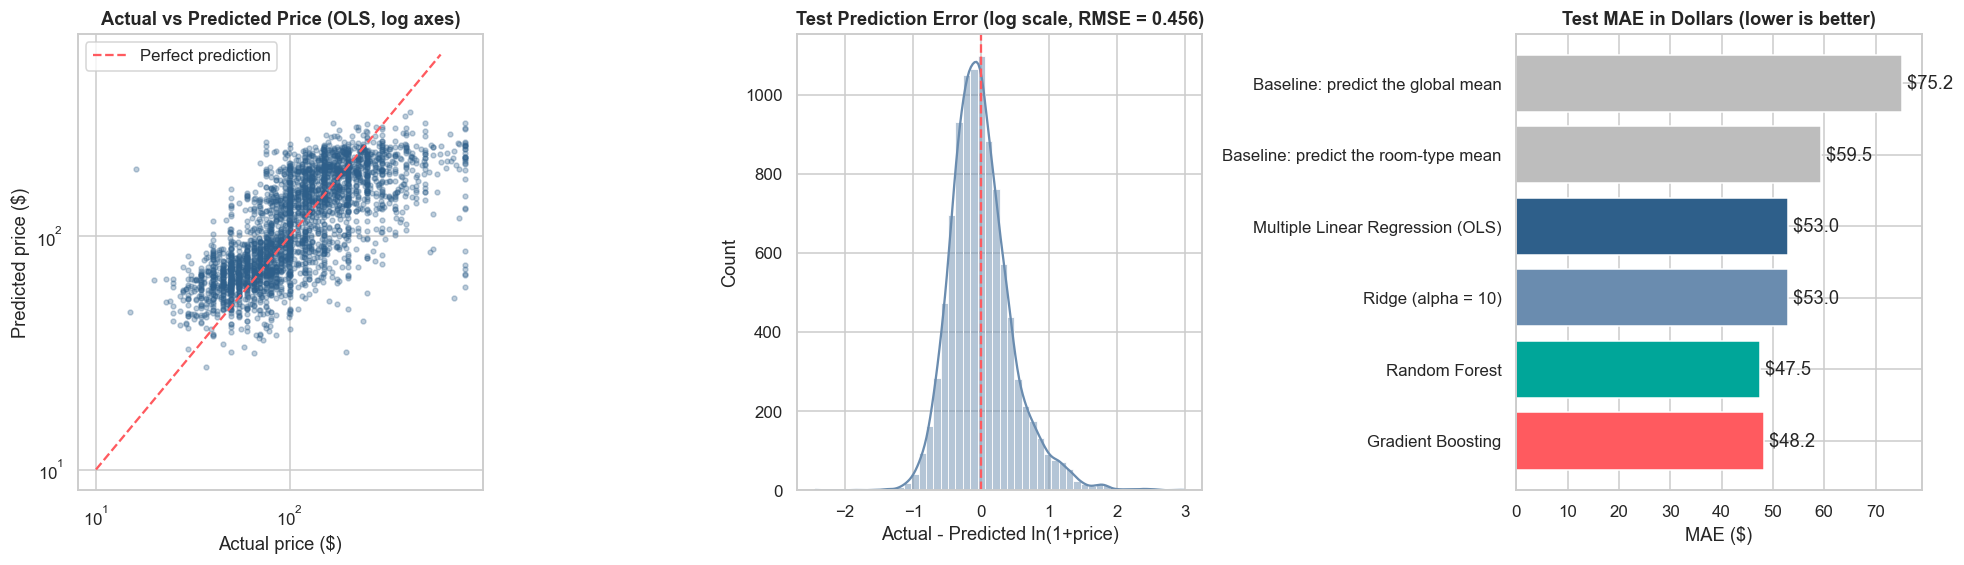

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))

sub = np.random.default_rng(SEED).choice(len(y_test), 3000, replace=False)
axes[0].scatter(np.expm1(y_test.values[sub]), np.expm1(pred_ols[sub]), alpha=0.3, color='#2e5f8a', s=10)
axes[0].plot([10, 600], [10, 600], color=AB_RED, linestyle='--', label='Perfect prediction')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_title('Actual vs Predicted Price (OLS, log axes)'); axes[0].set_xlabel('Actual price ($)'); axes[0].set_ylabel('Predicted price ($)'); axes[0].legend()

err = y_test - pred_ols
sns.histplot(err, kde=True, ax=axes[1], color='#6a8caf', bins=50)
axes[1].axvline(0, color=AB_RED, linestyle='--')
axes[1].set_title(f'Test Prediction Error (log scale, RMSE = {np.sqrt(mean_squared_error(y_test, pred_ols)):.3f})'); axes[1].set_xlabel('Actual - Predicted ln(1+price)')

plot_df = metrics_df.reset_index()
colors = ['#bdbdbd', '#bdbdbd', '#2e5f8a', '#6a8caf', AB_TEAL, AB_RED]
axes[2].barh(plot_df['Model'], plot_df['MAE ($)'], color=colors)
for i, v in enumerate(plot_df['MAE ($)']):
    axes[2].text(v, i, f' ${v:.1f}', va='center')
axes[2].invert_yaxis()
axes[2].set_title('Test MAE in Dollars (lower is better)'); axes[2].set_xlabel('MAE ($)')
plt.tight_layout()
show('q17_model_evaluation')

In [57]:
m = metrics_df
md_out(f"""### Interpretation
**Model quality.** On the **unseen 20% test set** the multiple linear regression achieves **R² = {m.loc['Multiple Linear Regression (OLS)', 'R² (log)']:.3f}** on log-price, RMSE = {m.loc['Multiple Linear Regression (OLS)', 'RMSE (log)']:.3f} and a dollar
**MAE = ${m.loc['Multiple Linear Regression (OLS)', 'MAE ($)']:.1f}**.

| Model | Test R² (log) | Test MAE | vs strongest naive baseline |
|---|---|---|---|
| Predict the mean | {m.iloc[0, 0]:.3f} | ${m.iloc[0, 2]:.1f} | — |
| Predict room-type mean | {m.iloc[1, 0]:.3f} | ${m.iloc[1, 2]:.1f} | — |
| **Multiple Linear Regression** | **{m.iloc[2, 0]:.3f}** | **${m.iloc[2, 2]:.1f}** | MAE {(m.iloc[2, 2] / m.iloc[1, 2] - 1):+.0%} |
| Ridge | {m.iloc[3, 0]:.3f} | ${m.iloc[3, 2]:.1f} | same as OLS |
| Random Forest | {m.iloc[4, 0]:.3f} | ${m.iloc[4, 2]:.1f} | MAE {(m.iloc[4, 2] / m.iloc[1, 2] - 1):+.0%} |
| Gradient Boosting | {m.iloc[5, 0]:.3f} | ${m.iloc[5, 2]:.1f} | MAE {(m.iloc[5, 2] / m.iloc[1, 2] - 1):+.0%} |

* The linear model beats both naive rules and **generalises without over-fitting**: test R² ({m.iloc[2, 0]:.3f}) equals the 5-fold cross-validated R² on the training data ({RES['cv_ols'][0]:.3f} ± {RES['cv_ols'][1]:.3f}).
* **Ridge adds nothing** (identical metrics) because the largest VIF is only {RES['vif_max_final']:.2f}; there is no multicollinearity for regularisation to repair.
* **Random Forest and Gradient Boosting improve R² by about {(m.iloc[4, 0] - m.iloc[2, 0]):.2f}** and cut MAE by roughly ${m.iloc[2, 2] - m.iloc[4, 2]:.1f}, indicating real **non-linear and interaction structure** (especially latitude/longitude and room-type × location) that a
  additive linear model cannot capture. The linear model is retained as the *interpretable* model; the forest is the *accuracy* benchmark.

**Assumption checks.**

| Assumption | Test | Result and action |
|---|---|---|
| No multicollinearity | VIF | Raw latitude/longitude were considered but replaced by borough + distance; final max VIF = {RES['vif_max_final']:.2f} |
| Linearity | Residuals vs fitted | Residuals centred on zero with no strong curvature in the residual-vs-fitted plot |
| Homoscedasticity | Breusch–Pagan p = {fmt_p(RES['bp_p'])} | **Violated** (LM = {RES['bp_lm']:.0f}) → HC3 robust standard errors used for all inference |
| Independence | Durbin–Watson = {RES['dw']:.2f} | Equals 2 but this is **uninformative**: listings have no time order (rows are cross-sectional), so independence rests on the sampling design |
| Normality of residuals | Q–Q plot, skew = {RES['resid_skew']:.2f}, kurtosis = {RES['resid_kurt']:.1f} | Right-skewed, heavy tails (JB rejects); with n = {len(X_train):,} the CLT keeps coefficient tests valid, but **prediction intervals are approximate** |
| Influential points | Cook's distance | max D = {cooks.max():.3f} (≪ 1): no single listing drives the fit |

**Coefficients** (HC3-robust, all p < 0.05): a **private room is ≈ {abs(np.exp(ols_hc3.params['room_private']) - 1):.0%} cheaper** than an entire home in the same place and a shared room ≈ {abs(np.exp(ols_hc3.params['room_shared']) - 1):.0%} cheaper;
**each km from Midtown lowers price ≈ {abs(np.exp(ols_hc3.params['dist_center_km']) - 1):.1%}**; Queens/Brooklyn/Bronx listings are {abs(np.exp(ols_hc3.params['boro_queens']) - 1):.0%}/{abs(np.exp(ols_hc3.params['boro_brooklyn']) - 1):.0%}/{abs(np.exp(ols_hc3.params['boro_bronx']) - 1):.0%} cheaper than Manhattan **after** controlling for distance;
a longer minimum stay lowers the price and +100 availability days raises it by ≈ {np.exp(100 * ols_hc3.params['availability_365']) - 1:.0%}. The small **negative** review coefficient mirrors Q15 (more reviews ≈ cheaper, faster-turnover listings).""")

### Interpretation
**Model quality.** On the **unseen 20% test set** the multiple linear regression achieves **R² = 0.538** on log-price, RMSE = 0.456 and a dollar
**MAE = \$53.0**.

| Model | Test R² (log) | Test MAE | vs strongest naive baseline |
|---|---|---|---|
| Predict the mean | -0.000 | \$75.2 | — |
| Predict room-type mean | 0.404 | \$59.5 | — |
| **Multiple Linear Regression** | **0.538** | **\$53.0** | MAE -11% |
| Ridge | 0.538 | \$53.0 | same as OLS |
| Random Forest | 0.633 | \$47.5 | MAE -20% |
| Gradient Boosting | 0.631 | \$48.2 | MAE -19% |

* The linear model beats both naive rules and **generalises without over-fitting**: test R² (0.538) equals the 5-fold cross-validated R² on the training data (0.536 ± 0.004).
* **Ridge adds nothing** (identical metrics) because the largest VIF is only 1.88; there is no multicollinearity for regularisation to repair.
* **Random Forest and Gradient Boosting improve R² by about 0.09** and cut MAE by roughly \$5.5, indicating real **non-linear and interaction structure** (especially latitude/longitude and room-type × location) that a
  additive linear model cannot capture. The linear model is retained as the *interpretable* model; the forest is the *accuracy* benchmark.

**Assumption checks.**

| Assumption | Test | Result and action |
|---|---|---|
| No multicollinearity | VIF | Raw latitude/longitude were considered but replaced by borough + distance; final max VIF = 1.88 |
| Linearity | Residuals vs fitted | Residuals centred on zero with no strong curvature in the residual-vs-fitted plot |
| Homoscedasticity | Breusch–Pagan p = 2.6e-161 | **Violated** (LM = 790) → HC3 robust standard errors used for all inference |
| Independence | Durbin–Watson = 2.00 | Equals 2 but this is **uninformative**: listings have no time order (rows are cross-sectional), so independence rests on the sampling design |
| Normality of residuals | Q–Q plot, skew = 0.84, kurtosis = 5.6 | Right-skewed, heavy tails (JB rejects); with n = 39,096 the CLT keeps coefficient tests valid, but **prediction intervals are approximate** |
| Influential points | Cook's distance | max D = 0.009 (≪ 1): no single listing drives the fit |

**Coefficients** (HC3-robust, all p < 0.05): a **private room is ≈ 54% cheaper** than an entire home in the same place and a shared room ≈ 69% cheaper;
**each km from Midtown lowers price ≈ 3.5%**; Queens/Brooklyn/Bronx listings are 22%/13%/23% cheaper than Manhattan **after** controlling for distance;
a longer minimum stay lowers the price and +100 availability days raises it by ≈ 10%. The small **negative** review coefficient mirrors Q15 (more reviews ≈ cheaper, faster-turnover listings).

---
### Question 18: Which Factors Matter Most, and What Does the Model Imply for Pricing Strategy?

> 📘 **Rubric 6 & Course PPT Reference:** Lecture 1, 2, 7 (Standardised Regression Coefficients & What-If Simulations) and Lecture 14 (Interpreting coefficients causally).

- **Objective:** Quantify the relative importance of predictors with **standardised coefficients** ($\beta^*$) and **permutation importance**, convert coefficients into percentage price effects, and simulate concrete listings with **95 % prediction intervals**.
- **Null Hypothesis ($H_0$):** A predictor has no linear effect on log-price ($\beta_j = 0$) given the others.
- **Alternative Hypothesis ($H_1$):** $\beta_j \neq 0$ (tested with HC3-robust $t$-statistics).

Feature importance table (sorted by |standardised beta|):


,Coefficient (log-price),Price effect per unit (%),Standardised Beta,Robust p-value,Significant
room_private,-0.7756,-53.9556,-0.5743,< 1e-4,Yes
room_shared,-1.1760,-69.1481,-0.2670,< 1e-4,Yes
dist_center_km,-0.0360,-3.5382,-0.2377,< 1e-4,Yes
availability_365,0.0009,0.0923,0.1804,< 1e-4,Yes
log_min_nights,-0.1126,-10.6511,-0.1450,< 1e-4,Yes
boro_queens,-0.2455,-21.7653,-0.1166,< 1e-4,Yes
boro_brooklyn,-0.1434,-13.3557,-0.1048,< 1e-4,Yes
log_reviews,-0.0392,-3.8450,-0.0912,< 1e-4,Yes
boro_bronx,-0.2659,-23.3470,-0.0585,< 1e-4,Yes
log_host_listings,-0.0079,-0.7837,-0.0123,0.0032,Yes


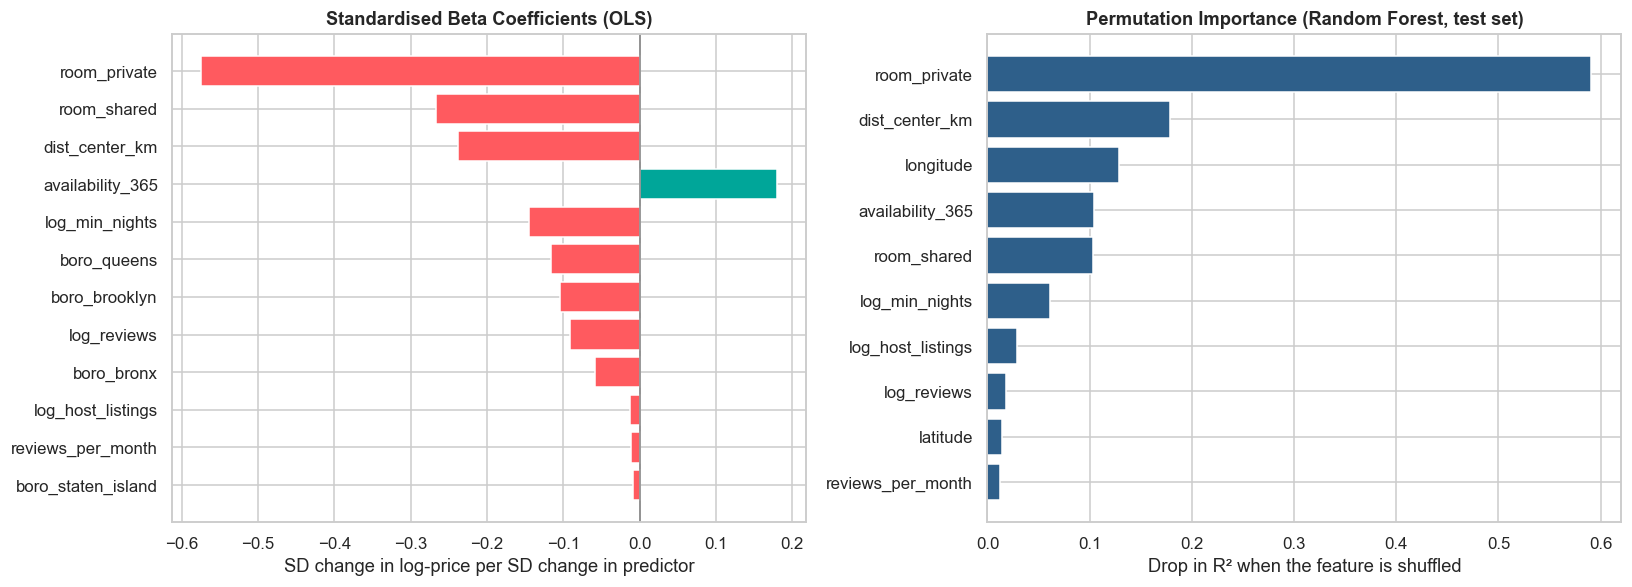

In [58]:
feats = list(X_train.columns)
std_beta = ols_model.params[feats] * X_train.std() / y_train.std()
coef_df = pd.DataFrame({
    'Coefficient (log-price)': ols_hc3.params[feats],
    'Price effect per unit (%)': (np.exp(ols_hc3.params[feats]) - 1) * 100,
    'Standardised Beta': std_beta,
    'Robust p-value': ols_hc3.pvalues[feats],
}).sort_values('Standardised Beta', key=np.abs, ascending=False)
coef_df['Significant'] = np.where(coef_df['Robust p-value'] < ALPHA, 'Yes', 'No')
coef_df['Robust p-value'] = coef_df['Robust p-value'].map(lambda p: '< 1e-4' if p < 1e-4 else f'{p:.4f}')
print('Feature importance table (sorted by |standardised beta|):')
display(coef_df.round(4))

# Permutation importance for the Random Forest on a held-out subsample
idx_pi = np.random.default_rng(SEED).choice(len(Xt_test), 4000, replace=False)
pi = permutation_importance(rf, Xt_test.iloc[idx_pi], y_test.iloc[idx_pi], n_repeats=5, random_state=SEED, n_jobs=-1, scoring='r2')
pi_df = pd.Series(pi.importances_mean, index=Xt_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sb = coef_df['Standardised Beta']
axes[0].barh(sb.index[::-1], sb.values[::-1], color=[AB_TEAL if v >= 0 else AB_RED for v in sb.values[::-1]])
axes[0].axvline(0, color='grey', lw=1)
axes[0].set_title('Standardised Beta Coefficients (OLS)'); axes[0].set_xlabel('SD change in log-price per SD change in predictor')
top_pi = pi_df.head(10)[::-1]
axes[1].barh(top_pi.index, top_pi.values, color='#2e5f8a')
axes[1].set_title('Permutation Importance (Random Forest, test set)'); axes[1].set_xlabel('Drop in R² when the feature is shuffled')
plt.tight_layout()
show('q18_feature_importance')
RES['std_beta'] = std_beta.round(4).to_dict()
RES['perm_importance'] = pi_df.head(6).round(4).to_dict()

,OLS predicted ($),95% PI low ($),95% PI high ($),Random Forest ($)
Scenario,,,,
"Manhattan · Entire home, Midtown",242.0,98.0,595.0,328.0
Manhattan · Private room,119.0,48.0,294.0,161.0
Brooklyn · Entire home,150.0,60.0,370.0,189.0
Brooklyn · Private room,71.0,28.0,175.0,77.0
Queens · Private room,45.0,18.0,112.0,57.0
Bronx · Shared room,30.0,11.0,74.0,40.0
"Manhattan · Entire home, commercial host (10 listings)",208.0,84.0,512.0,188.0


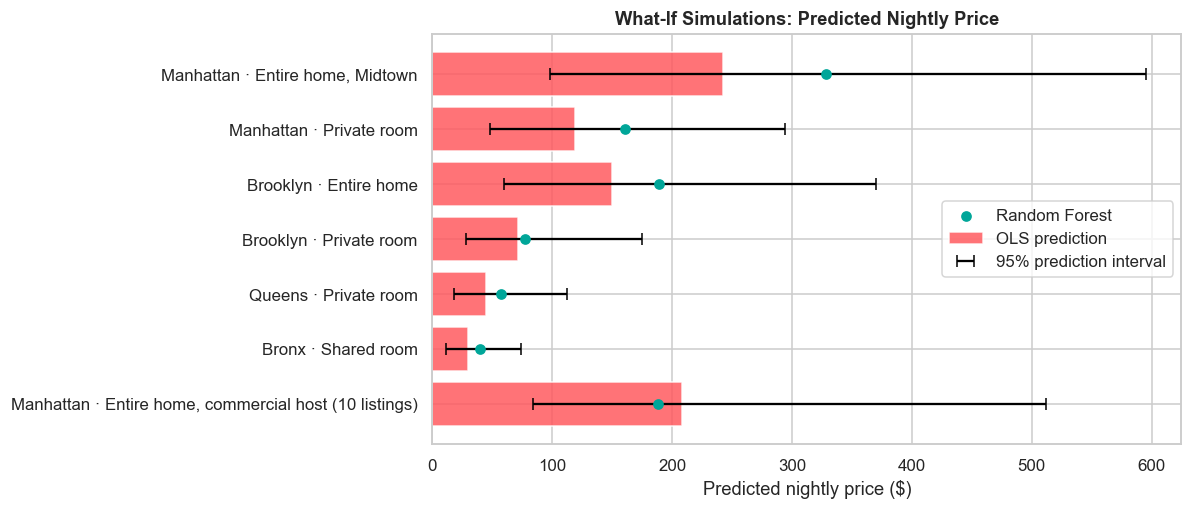

In [59]:
# What-If scenario simulation with 95% prediction intervals (OLS) and Random-Forest cross-check
centroids = {'Manhattan': (40.7580, -73.9855), 'Brooklyn': (40.6782, -73.9442), 'Queens': (40.7282, -73.7949),
             'Bronx': (40.8448, -73.8648), 'Staten Island': (40.5795, -74.1502)}
# (label, borough, room_type, min_nights, availability, reviews, reviews_per_month, host_listings, lat/lon offset)
scenarios = [
    ('Manhattan · Entire home, Midtown', 'Manhattan', 'Entire home/apt', 3, 180, 25, 1.5, 1),
    ('Manhattan · Private room', 'Manhattan', 'Private room', 2, 200, 15, 0.9, 1),
    ('Brooklyn · Entire home', 'Brooklyn', 'Entire home/apt', 2, 180, 40, 2.2, 1),
    ('Brooklyn · Private room', 'Brooklyn', 'Private room', 2, 180, 20, 1.0, 1),
    ('Queens · Private room', 'Queens', 'Private room', 5, 120, 8, 0.4, 1),
    ('Bronx · Shared room', 'Bronx', 'Shared room', 7, 60, 5, 0.2, 1),
    ('Manhattan · Entire home, commercial host (10 listings)', 'Manhattan', 'Entire home/apt', 30, 330, 60, 3.0, 10),
]
rows = []
for label, brg, rtype, nights, avail, revs, rpm, host_cnt in scenarios:
    lat, lon = centroids[brg]
    spec = pd.DataFrame([{'neighbourhood_group': brg, 'room_type': rtype, 'minimum_nights': nights, 'availability_365': avail,
                          'number_of_reviews': revs, 'reviews_per_month': rpm, 'calculated_host_listings_count': host_cnt,
                          'latitude': lat, 'longitude': lon, 'dist_center_km': float(haversine_km(lat, lon, *TIMES_SQ))}])
    Xs = build_design(spec)[feats]
    pred = ols_model.get_prediction(sm.add_constant(Xs, has_constant='add'))
    pi_ = np.expm1(pred.conf_int(obs=True, alpha=0.05)[0])
    Xs_tree = Xs.copy(); Xs_tree['latitude'], Xs_tree['longitude'] = lat, lon
    rows.append({'Scenario': label, 'OLS predicted ($)': float(np.expm1(pred.predicted_mean[0])),
                 '95% PI low ($)': pi_[0], '95% PI high ($)': pi_[1], 'Random Forest ($)': float(np.expm1(rf.predict(Xs_tree[Xt_train.columns])[0]))})
what_if = pd.DataFrame(rows).set_index('Scenario').round(0)
display(what_if)

fig, ax = plt.subplots(figsize=(11, 4.8))
yy = np.arange(len(what_if))[::-1]
ax.barh(yy, what_if['OLS predicted ($)'], color=AB_RED, alpha=0.85, label='OLS prediction')
ax.errorbar(what_if['OLS predicted ($)'], yy, xerr=[what_if['OLS predicted ($)'] - what_if['95% PI low ($)'], what_if['95% PI high ($)'] - what_if['OLS predicted ($)']],
            fmt='none', ecolor='black', capsize=4, label='95% prediction interval')
ax.scatter(what_if['Random Forest ($)'], yy, color=AB_TEAL, zorder=5, label='Random Forest')
ax.set_yticks(yy); ax.set_yticklabels(what_if.index)
ax.set_title('What-If Simulations: Predicted Nightly Price'); ax.set_xlabel('Predicted nightly price ($)'); ax.legend()
plt.tight_layout()
show('q18_what_if')
RES['what_if'] = what_if.to_dict(orient='index')
RES['pi_width_manhattan_entire'] = float(what_if.iloc[0]['95% PI high ($)'] / what_if.iloc[0]['95% PI low ($)'])

In [60]:
top3 = coef_df.index[:3].tolist()
md_out(f"""### Interpretation
**Ranking of price drivers.** Both methods agree on what matters most:

1. **Room type** (standardised β: private room {std_beta['room_private']:.2f}, shared room {std_beta['room_shared']:.2f}) — the single most important lever.
2. **Location** — distance to Midtown (β = {std_beta['dist_center_km']:.2f}) and borough (Queens β = {std_beta['boro_queens']:.2f}, Brooklyn β = {std_beta['boro_brooklyn']:.2f}); the Random Forest's permutation importance puts
   {', '.join(f"`{k}`" for k in list(RES['perm_importance'])[:3])} at the top, confirming that raw location carries the most predictive signal.
3. **Availability** (β = {std_beta['availability_365']:.2f}) and **minimum stay** (β = {std_beta['log_min_nights']:.2f}) — a distant third tier.
4. Reviews and host portfolio size: very small effects (|β| < {max(abs(std_beta['log_reviews']), abs(std_beta['log_host_listings'])) + 0.01:.2f}).

**What-if scenarios (OLS prediction, 95% prediction interval, Random Forest cross-check):**

| Scenario | OLS | 95% interval | Random Forest |
|---|---|---|---|
""" + "\n".join(f"| {i} | ${r['OLS predicted ($)']:.0f} | ${r['95% PI low ($)']:.0f} – ${r['95% PI high ($)']:.0f} | ${r['Random Forest ($)']:.0f} |" for i, r in what_if.iterrows()) + f"""

**Pricing implications.**
* **Room configuration is the biggest lever.** Offering the *whole unit* rather than a room in the same location roughly **doubles** the achievable price (Manhattan: ${what_if.iloc[1, 0]:.0f} → ${what_if.iloc[0, 0]:.0f}).
* **Location premium is steep but local**: a Midtown entire home is predicted at ${what_if.iloc[0, 0]:.0f} (OLS) to ${what_if.iloc[0, 3]:.0f} (Random Forest), against ${what_if.iloc[2, 0]:.0f}–${what_if.iloc[2, 3]:.0f} for a Brooklyn entire home. The forest is higher in Midtown because the
  additive linear model cannot represent the *interaction* between whole-unit listings and central locations.
* **A 30-night minimum stay (in the 10-listing-host scenario) is predicted lower** (${what_if.iloc[6, 0]:.0f} vs ${what_if.iloc[0, 0]:.0f} for the otherwise similar 3-night Midtown home), consistent with long-stay discounting; the lever for hosts who want regulatory compliance without losing revenue is the monthly
  rate, not the nightly one.
* The **prediction intervals are wide** (the upper bound is ≈ {RES['pi_width_manhattan_entire']:.1f}× the lower bound): even the best model leaves ≈ {1 - m.loc['Gradient Boosting', 'R² (log)']:.0%} of log-price variance unexplained,
  coming from unobserved quality (size, photos, amenities, host reputation). Predictions are a **benchmark price range**, not a guarantee.""")

### Interpretation
**Ranking of price drivers.** Both methods agree on what matters most:

1. **Room type** (standardised β: private room -0.57, shared room -0.27) — the single most important lever.
2. **Location** — distance to Midtown (β = -0.24) and borough (Queens β = -0.12, Brooklyn β = -0.10); the Random Forest's permutation importance puts
   `room_private`, `dist_center_km`, `longitude` at the top, confirming that raw location carries the most predictive signal.
3. **Availability** (β = 0.18) and **minimum stay** (β = -0.15) — a distant third tier.
4. Reviews and host portfolio size: very small effects (|β| < 0.10).

**What-if scenarios (OLS prediction, 95% prediction interval, Random Forest cross-check):**

| Scenario | OLS | 95% interval | Random Forest |
|---|---|---|---|
| Manhattan · Entire home, Midtown | \$242 | \$98 – \$595 | \$328 |
| Manhattan · Private room | \$119 | \$48 – \$294 | \$161 |
| Brooklyn · Entire home | \$150 | \$60 – \$370 | \$189 |
| Brooklyn · Private room | \$71 | \$28 – \$175 | \$77 |
| Queens · Private room | \$45 | \$18 – \$112 | \$57 |
| Bronx · Shared room | \$30 | \$11 – \$74 | \$40 |
| Manhattan · Entire home, commercial host (10 listings) | \$208 | \$84 – \$512 | \$188 |

**Pricing implications.**
* **Room configuration is the biggest lever.** Offering the *whole unit* rather than a room in the same location roughly **doubles** the achievable price (Manhattan: \$119 → \$242).
* **Location premium is steep but local**: a Midtown entire home is predicted at \$242 (OLS) to \$328 (Random Forest), against \$150–\$189 for a Brooklyn entire home. The forest is higher in Midtown because the
  additive linear model cannot represent the *interaction* between whole-unit listings and central locations.
* **A 30-night minimum stay (in the 10-listing-host scenario) is predicted lower** (\$208 vs \$242 for the otherwise similar 3-night Midtown home), consistent with long-stay discounting; the lever for hosts who want regulatory compliance without losing revenue is the monthly
  rate, not the nightly one.
* The **prediction intervals are wide** (the upper bound is ≈ 6.1× the lower bound): even the best model leaves ≈ 37% of log-price variance unexplained,
  coming from unobserved quality (size, photos, amenities, host reputation). Predictions are a **benchmark price range**, not a guarantee.

---
## 11. Dashboard and Clean Data Export

> 📘 **Rubric 7:** Python / Tableau visualisation, conclusions, insights, limitations.

### 11.1 Executive KPI Summary and Static Dashboard

=== NYC AIRBNB CASE STUDY EXECUTIVE SUMMARY ===
Total Listings Analysed                   : 48,870
Unique Hosts                              : 37,442
Median Nightly Price                      : $106
Manhattan vs Bronx Median Price           : $150 vs $65
Entire-Home Premium over Private Room     : 129% (Cohen's d = 1.61)
Listings Requiring 30+ Nights             : 9.2%
Listings Owned by Multi-Listing Hosts     : 33.9%
Linear Model Test R² (log price)          : 0.54
Linear Model Test MAE                     : $53.0
Best Benchmark (Gradient Boosting) MAE    : $48.2


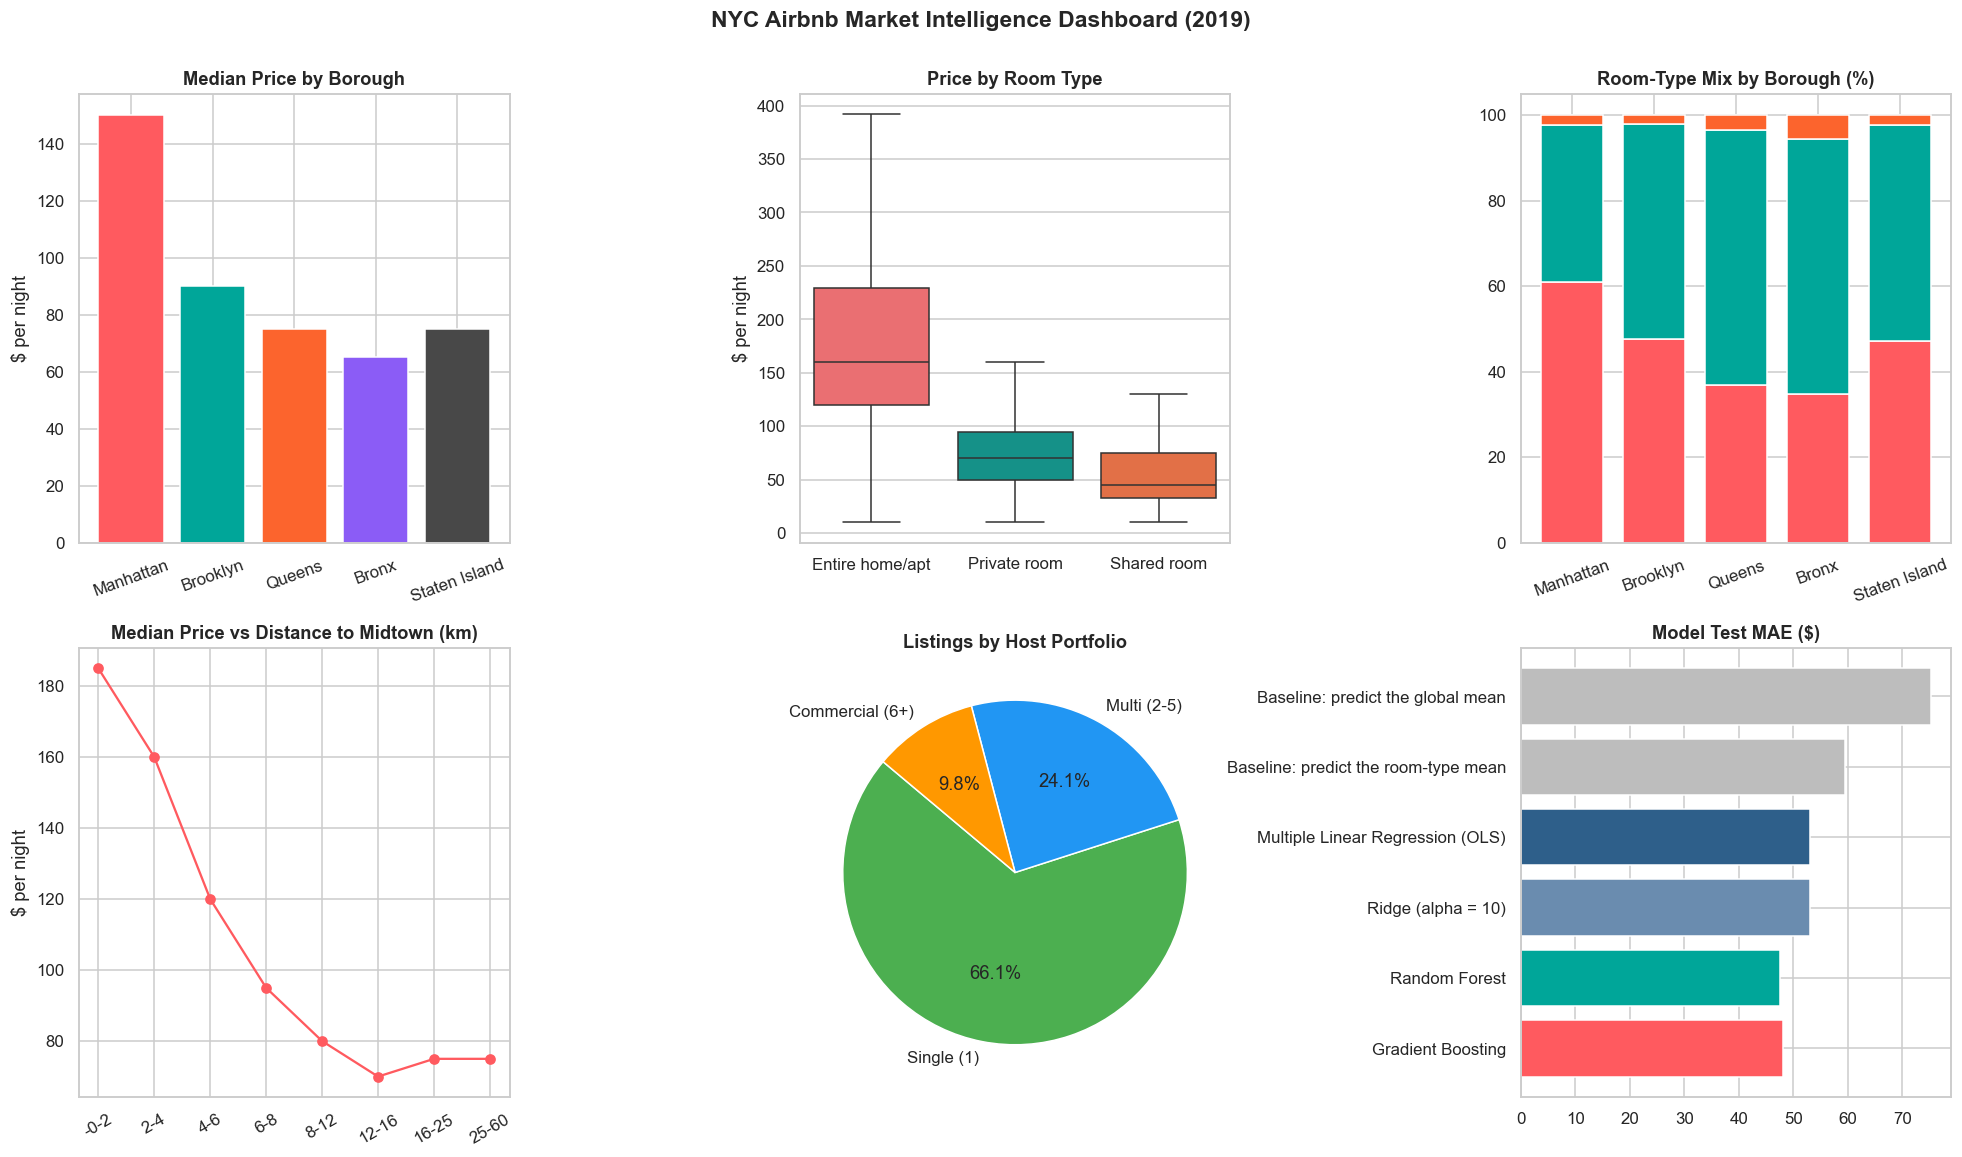

In [61]:
kpis = {
    'Total Listings Analysed': f"{len(df):,}",
    'Unique Hosts': f"{df['host_id'].nunique():,}",
    'Median Nightly Price': f"${df['price'].median():.0f}",
    'Manhattan vs Bronx Median Price': f"${df.loc[df.neighbourhood_group == 'Manhattan', 'price'].median():.0f} vs ${df.loc[df.neighbourhood_group == 'Bronx', 'price'].median():.0f}",
    'Entire-Home Premium over Private Room': f"{RES['room_premium']:.0%} (Cohen's d = {RES['d_room']:.2f})",
    'Listings Requiring 30+ Nights': f"{RES['long_stay_share']:.1%}",
    'Listings Owned by Multi-Listing Hosts': f"{RES['multi_share']:.1%}",
    'Linear Model Test R² (log price)': f"{metrics_df.loc['Multiple Linear Regression (OLS)', 'R² (log)']:.2f}",
    'Linear Model Test MAE': f"${metrics_df.loc['Multiple Linear Regression (OLS)', 'MAE ($)']:.1f}",
    'Best Benchmark (Gradient Boosting) MAE': f"${metrics_df.loc['Gradient Boosting', 'MAE ($)']:.1f}",
}
print('=== NYC AIRBNB CASE STUDY EXECUTIVE SUMMARY ===')
for metric, val in kpis.items():
    print(f'{metric:<42}: {val}')
RES['kpis'] = kpis

fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(2, 3)
ax = fig.add_subplot(gs[0, 0])
med_b = df.groupby('neighbourhood_group')['price_capped'].median().loc[BOROUGH_ORDER]
ax.bar(med_b.index, med_b.values, color=[BOROUGH_COLORS[b] for b in med_b.index]); ax.set_title('Median Price by Borough'); ax.set_ylabel('$ per night'); ax.tick_params(axis='x', rotation=20)
ax = fig.add_subplot(gs[0, 1])
sns.boxplot(data=df, x='room_type', y='price_capped', order=ROOM_ORDER, palette=ROOM_COLORS, showfliers=False, ax=ax); ax.set_title('Price by Room Type'); ax.set_xlabel(''); ax.set_ylabel('$ per night')
ax = fig.add_subplot(gs[0, 2])
ct_pct.plot(kind='bar', stacked=True, color=[ROOM_COLORS[r] for r in ROOM_ORDER], ax=ax, legend=False, width=0.75); ax.set_title('Room-Type Mix by Borough (%)'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
ax = fig.add_subplot(gs[1, 0])
ax.plot(range(len(band_tbl)), band_tbl['median'].values, marker='o', color=AB_RED); ax.set_xticks(range(len(band_tbl))); ax.set_xticklabels([f'{i.left:.0f}-{i.right:.0f}' for i in band_tbl.index], rotation=30)
ax.set_title('Median Price vs Distance to Midtown (km)'); ax.set_ylabel('$ per night')
ax = fig.add_subplot(gs[1, 1])
ax.pie(host_counts.values, labels=HOST_ORDER, autopct='%1.1f%%', colors=['#4CAF50', '#2196F3', '#FF9800'], startangle=140); ax.set_title('Listings by Host Portfolio')
ax = fig.add_subplot(gs[1, 2])
ax.barh(plot_df['Model'], plot_df['MAE ($)'], color=colors); ax.invert_yaxis(); ax.set_title('Model Test MAE ($)')
plt.suptitle('NYC Airbnb Market Intelligence Dashboard (2019)', fontsize=15, fontweight='bold', y=1.0)
plt.tight_layout()
show('dashboard_summary')

### 11.2 Interactive Market Explorer (Plotly)

In [62]:
geo = df.sample(6000, random_state=SEED)
fig = px.scatter(geo, x='longitude', y='latitude', color='neighbourhood_group', category_orders={'neighbourhood_group': BOROUGH_ORDER},
                 color_discrete_map=BOROUGH_COLORS, size='price_capped', size_max=12, opacity=0.6,
                 hover_data={'neighbourhood': True, 'room_type': True, 'price': ':$,.0f', 'minimum_nights': True, 'longitude': False, 'latitude': False},
                 title='Interactive Map of NYC Listings (bubble size = price; click legend to filter boroughs)')
fig.update_layout(height=640, template='plotly_white', legend_title='Borough', yaxis_scaleanchor='x')
fig.show()

# Linked price explorer: room-type dropdown over borough price distributions
fig2 = go.Figure()
for rt in ['All room types'] + ROOM_ORDER:
    sub = df if rt == 'All room types' else df[df['room_type'] == rt]
    for b in BOROUGH_ORDER:
        fig2.add_trace(go.Box(y=sub.loc[sub['neighbourhood_group'] == b, 'price_capped'], name=b, marker_color=BOROUGH_COLORS[b],
                              visible=(rt == 'All room types'), boxpoints=False))
n_b = len(BOROUGH_ORDER)
buttons = []
for i, rt in enumerate(['All room types'] + ROOM_ORDER):
    vis = [False] * (4 * n_b); vis[i * n_b:(i + 1) * n_b] = [True] * n_b
    buttons.append(dict(label=rt, method='update', args=[{'visible': vis}, {'title': f'Nightly Price by Borough: {rt}'}]))
fig2.update_layout(updatemenus=[dict(buttons=buttons, direction='down', x=0.01, y=1.15)], title='Nightly Price by Borough: All room types',
                   yaxis_title='Price ($)', height=520, template='plotly_white', showlegend=False)
fig2.show()

### 11.3 Export Clean Analytical Tables for Tableau / Power BI

In [63]:
tableau_cols = ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type',
                'price', 'price_capped', 'log_price', 'minimum_nights', 'long_stay', 'number_of_reviews', 'review_group', 'reviews_per_month',
                'calculated_host_listings_count', 'host_type', 'availability_365', 'availability_cohort', 'dist_center_km']
df[tableau_cols].to_csv(f'{OUT_DIR}/NYC_Airbnb_Tableau_Data.csv', index=False)

borough_out = df.groupby('neighbourhood_group').agg(listings=('id', 'count'), median_price=('price', 'median'), mean_price=('price_capped', 'mean'),
                                                    avg_availability=('availability_365', 'mean'), pct_long_stay=('long_stay', 'mean')).round(3)
borough_out.to_csv(f'{OUT_DIR}/borough_summary.csv')
test_reg_display.to_csv(f'{OUT_DIR}/hypothesis_test_register.csv', index=False)
metrics_df.to_csv(f'{OUT_DIR}/model_metrics.csv')
coef_df.to_csv(f'{OUT_DIR}/regression_coefficients.csv')

data_dictionary = pd.DataFrame([
    ('price', 'Nightly price in USD (raw)'), ('price_capped', 'Price winsorised at the 99th percentile'), ('log_price', 'ln(1 + price_capped), modelling target'),
    ('long_stay', 'minimum_nights >= 30 (NYC Multiple Dwelling Law threshold)'), ('host_type', 'Single (1) / Multi (2-5) / Commercial (6+) by host listings count'),
    ('availability_cohort', 'Dormant (0) / Part-time (1-299) / Year-round (300+) days'), ('review_group', 'None / Low (1-5) / Medium (6-25) / High (26+) reviews'),
    ('dist_center_km', 'Haversine distance to Times Square in kilometres'),
], columns=['Field', 'Definition'])
data_dictionary.to_csv(f'{OUT_DIR}/data_dictionary.csv', index=False)

with open(f'{OUT_DIR}/analysis_results.json', 'w') as fh:
    json.dump(RES, fh, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))

print(f'Successfully exported analytical tables to {OUT_DIR}/ folder:')
for f in sorted(os.listdir(OUT_DIR)):
    print(f' - {f:<34} ({os.path.getsize(os.path.join(OUT_DIR, f)) / 1024:,.1f} KB)')

Successfully exported analytical tables to /Users/kmidunraja/Downloads/FODS_Final_Submission/outputs/ folder:
 - NYC_Airbnb_Tableau_Data.csv        (10,634.7 KB)
 - analysis_results.json              (7.5 KB)
 - borough_summary.csv                (0.3 KB)
 - data_dictionary.csv                (0.5 KB)
 - figures                            (1.2 KB)
 - hypothesis_test_register.csv       (1.4 KB)
 - model_metrics.csv                  (0.3 KB)
 - regression_coefficients.csv        (1.1 KB)


---
## 12. Key Findings

Every headline claim below is generated from the notebook's own results (no typed-in numbers), so it can be audited against `outputs/analysis_results.json` and `outputs/hypothesis_test_register.csv`.

In [64]:
mm = metrics_df
rows = [
 ('Prices are log-normal, not normal', f"Raw skewness {RES['skew_raw']:.1f} falls to {RES['skew_log']:.2f} on the log scale; median ${RES['median_price']:.0f} vs mean ${RES['mean_price']:.0f}", 'Q1, Q16'),
 ('Manhattan dominates the price hierarchy', f"Medians: Manhattan ${RES['median_by_borough']['Manhattan']:.0f} > Brooklyn ${RES['median_by_borough']['Brooklyn']:.0f} > Queens/Staten Island ${RES['median_by_borough']['Queens']:.0f} > Bronx ${RES['median_by_borough']['Bronx']:.0f}", 'Q2'),
 ('Borough explains ~14% of price variance', f"Welch ANOVA F = {RES['welch_F_borough']:,.0f}, p < 0.001, eta² = {RES['eta2_borough']:.3f}; Kruskal–Wallis agrees", 'Q2'),
 ('Room type is the largest single price driver', f"Entire home ${RES['med_entire']:.0f} vs private room ${RES['med_private']:.0f} ({RES['room_premium']:.0%} premium); Welch t = {RES['t_room']:.0f}, Cohen's d = {RES['d_room']:.2f}", 'Q3, Q18'),
 ('Room mix and borough are associated, modestly', f"chi² = {RES['chi2_borough_room']:,.0f} (dof {RES['dof_chi']}), Cramér's V = {RES['V_borough_room']:.3f}; Manhattan is {RES['manhattan_entire_pct']:.0f}% entire homes", 'Q4'),
 ('Neighbourhood matters more than borough', f"{RES['top_neighbourhood']} leads at ${RES['top_neighbourhood_median']:.0f}; Kruskal–Wallis across {RES['n_valid_neigh']} neighbourhoods eps² = {RES['eps2_neigh']:.2f}", 'Q5'),
 ('Availability and reviews barely move price', f"Availability rho = {RES['rho_avail']:.3f}; reviews vs price rho = {RES['rho_reviews_price']:.3f} (negative): significant yet negligible", 'Q6, Q14, Q15'),
 ('Review count and velocity are strongly linked', f"Spearman rho = {RES['rho_reviews']:.2f} among reviewed listings", 'Q7'),
 ('Regulation-style long stays are a sizeable niche', f"{RES['long_stay_n']:,} listings ({RES['long_stay_share']:.1%}) require 30+ nights: {RES['long_entire']:.1%} of entire homes vs {RES['long_private']:.1%} of private rooms", 'Q8'),
 ('Supply is mostly single-property hosts', f"{RES['single_share']:.1%} of listings are single-host; Gini = {RES['gini_hosts']:.2f}; top 1% of hosts own {RES['top1_share']:.1%}", 'Q9'),
 ('Covariance of standardised data equals correlation', f"Frobenius difference {RES['frobenius']:.1e}; PC1 explains {RES['pc1_var']:.0%}", 'Q10'),
 ('Log-Normal model is a good but imperfect fit', f"P(price <= $100): model {RES['p100_theory']:.1%} vs empirical {RES['p100_emp']:.1%}; KS D = {RES['ks_D']:.3f}", 'Q11'),
 ('The CLT justifies mean-based inference', f"Skewness of sample means {RES['clt_skew'][5]:.2f} (n=5) -> {RES['clt_skew'][100]:.2f} (n=100); SE {RES['clt_se_emp100']:.1f} vs theory {RES['clt_se_theory100']:.1f}", 'Q12'),
 ('Price decays steadily with distance from Midtown', f"Spearman rho = {RES['rho_dist']:.2f}; median ${RES['median_0_2km']:.0f} within 2 km", 'Q13'),
 ('Linear model explains about half of price variation', f"Test R² = {mm.loc['Multiple Linear Regression (OLS)', 'R² (log)']:.2f}, MAE ${mm.loc['Multiple Linear Regression (OLS)', 'MAE ($)']:.1f} vs ${mm.loc['Baseline: predict the room-type mean', 'MAE ($)']:.1f} for the room-type baseline", 'Q17'),
 ('Non-linear models add accuracy, not new drivers', f"Random Forest R² = {mm.loc['Random Forest', 'R² (log)']:.2f}, MAE ${mm.loc['Random Forest', 'MAE ($)']:.1f}; Gradient Boosting R² = {mm.loc['Gradient Boosting', 'R² (log)']:.2f}", 'Q17'),
 ('Errors are heteroscedastic with heavy tails', f"Breusch–Pagan LM = {RES['bp_lm']:.0f} (p ~ 0); residual skew {RES['resid_skew']:.2f}; HC3 robust SE used", 'Q17'),
 ('Room type, location and availability are the levers', f"Top standardised betas: private room {RES['std_beta']['room_private']:.2f}, shared {RES['std_beta']['room_shared']:.2f}, distance {RES['std_beta']['dist_center_km']:.2f}", 'Q18'),
]
find_df = pd.DataFrame(rows, columns=['Finding', 'Evidence', 'Question'])
find_df.index = np.arange(1, len(find_df) + 1)
find_df.index.name = '#'
md_out('| # | Finding | Evidence | Question |\n|---|---|---|---|\n' + '\n'.join(f'| {i} | **{r.Finding}** | {r.Evidence} | {r.Question} |' for i, r in find_df.iterrows()))
find_df.to_csv(f'{OUT_DIR}/key_findings.csv')

| # | Finding | Evidence | Question |
|---|---|---|---|
| 1 | **Prices are log-normal, not normal** | Raw skewness 19.1 falls to 0.37 on the log scale; median \$106 vs mean \$153 | Q1, Q16 |
| 2 | **Manhattan dominates the price hierarchy** | Medians: Manhattan \$150 > Brooklyn \$90 > Queens/Staten Island \$75 > Bronx \$65 | Q2 |
| 3 | **Borough explains ~14% of price variance** | Welch ANOVA F = 1,973, p < 0.001, eta² = 0.136; Kruskal–Wallis agrees | Q2 |
| 4 | **Room type is the largest single price driver** | Entire home \$160 vs private room \$70 (129% premium); Welch t = 176, Cohen's d = 1.61 | Q3, Q18 |
| 5 | **Room mix and borough are associated, modestly** | chi² = 1,558 (dof 8), Cramér's V = 0.126; Manhattan is 61% entire homes | Q4 |
| 6 | **Neighbourhood matters more than borough** | Tribeca leads at \$295; Kruskal–Wallis across 123 neighbourhoods eps² = 0.30 | Q5 |
| 7 | **Availability and reviews barely move price** | Availability rho = 0.086; reviews vs price rho = -0.055 (negative): significant yet negligible | Q6, Q14, Q15 |
| 8 | **Review count and velocity are strongly linked** | Spearman rho = 0.71 among reviewed listings | Q7 |
| 9 | **Regulation-style long stays are a sizeable niche** | 4,491 listings (9.2%) require 30+ nights: 12.4% of entire homes vs 5.6% of private rooms | Q8 |
| 10 | **Supply is mostly single-property hosts** | 66.1% of listings are single-host; Gini = 0.22; top 1% of hosts own 10.1% | Q9 |
| 11 | **Covariance of standardised data equals correlation** | Frobenius difference 3.1e-15; PC1 explains 28% | Q10 |
| 12 | **Log-Normal model is a good but imperfect fit** | P(price <= \$100): model 43.1% vs empirical 48.9%; KS D = 0.059 | Q11 |
| 13 | **The CLT justifies mean-based inference** | Skewness of sample means 1.16 (n=5) -> 0.24 (n=100); SE 12.3 vs theory 12.2 | Q12 |
| 14 | **Price decays steadily with distance from Midtown** | Spearman rho = -0.46; median \$185 within 2 km | Q13 |
| 15 | **Linear model explains about half of price variation** | Test R² = 0.54, MAE \$53.0 vs \$59.5 for the room-type baseline | Q17 |
| 16 | **Non-linear models add accuracy, not new drivers** | Random Forest R² = 0.63, MAE \$47.5; Gradient Boosting R² = 0.63 | Q17 |
| 17 | **Errors are heteroscedastic with heavy tails** | Breusch–Pagan LM = 790 (p ~ 0); residual skew 0.84; HC3 robust SE used | Q17 |
| 18 | **Room type, location and availability are the levers** | Top standardised betas: private room -0.57, shared -0.27, distance -0.24 | Q18 |

In [65]:
mm = metrics_df
md_out(f"""## 13. Conclusion
This case study analysed **{RES['n_clean']:,} NYC Airbnb listings (2019)** across five boroughs and {df['neighbourhood'].nunique()} neighbourhoods to test what really determines the nightly price.

**Data preprocessing** diagnosed the missing-value mechanism before treating it (all {raw['reviews_per_month'].isna().sum():,} missing review rates are structural zeros, not random gaps), removed {RES['n_raw'] - RES['n_clean']} invalid records (zero prices and multi-year minimum stays),
verified coordinates, kept genuine extreme listings after IQR analysis, winsorised the target at the 99th percentile (${RES['price_cap']:,.0f}) and engineered distance, host-type, availability and review features.

**Hypothesis testing** across {RES['n_tests']} formal tests used methods matched to each data type — Welch ANOVA and Kruskal–Wallis for borough, neighbourhood, host-type and availability groups; Welch t, Mann–Whitney and two-proportion z-tests for A/B comparisons; chi-square for
association; Spearman/Pearson for correlation; an exact binomial test for host ownership; and Kolmogorov–Smirnov for distributional fit — each reported with an effect size. After a Holm correction **{RES['n_rejected_holm']} of {RES['n_tests']}** nulls are rejected, but with ~49,000 listings
significance is cheap, so **effect sizes decide what matters**: room type (d = {RES['d_room']:.2f}), neighbourhood (ε² = {RES['eps2_neigh']:.2f}), borough (η² = {RES['eta2_borough']:.2f}) and distance (ρ = {RES['rho_dist']:.2f}) are substantial, whereas availability, review volume and host type are
statistically significant but practically negligible. The popular beliefs that *reviews earn a premium* and *professional hosts dominate supply* are **not supported** by the data.

**FODS concepts** were verified empirically: the covariance of standardised data equals the correlation matrix to machine precision (Q10), a log-Normal model approximates price adequately (Q11), and the Central Limit Theorem holds for the skewed price distribution (Q12).

**The multiple linear regression** predicts log-price on unseen listings with **R² = {mm.loc['Multiple Linear Regression (OLS)', 'R² (log)']:.2f}** and a mean error of **${mm.loc['Multiple Linear Regression (OLS)', 'MAE ($)']:.0f}**, beating the room-type baseline (${mm.loc['Baseline: predict the room-type mean', 'MAE ($)']:.0f}), with cross-validated performance matching the test score.
Random Forest and Gradient Boosting lift R² to about {mm.loc['Random Forest', 'R² (log)']:.2f} by capturing non-linear location effects, so the linear model is retained for interpretation and the forest as the accuracy benchmark. Its assumptions were tested and handled (VIF-based feature selection, HC3
robust errors for heteroscedasticity, Cook's distance for influence).

**Overall:** the price of an NYC Airbnb in 2019 is decided mostly by **what is offered (entire home vs room) and where it is (distance to Midtown, neighbourhood)**; calendar and reputation variables add very little, and roughly {1 - mm.loc['Gradient Boosting', 'R² (log)']:.0%} of price variation
reflects unobserved quality that this dataset cannot see.""")

## 13. Conclusion
This case study analysed **48,870 NYC Airbnb listings (2019)** across five boroughs and 221 neighbourhoods to test what really determines the nightly price.

**Data preprocessing** diagnosed the missing-value mechanism before treating it (all 10,052 missing review rates are structural zeros, not random gaps), removed 25 invalid records (zero prices and multi-year minimum stays),
verified coordinates, kept genuine extreme listings after IQR analysis, winsorised the target at the 99th percentile (\$799) and engineered distance, host-type, availability and review features.

**Hypothesis testing** across 14 formal tests used methods matched to each data type — Welch ANOVA and Kruskal–Wallis for borough, neighbourhood, host-type and availability groups; Welch t, Mann–Whitney and two-proportion z-tests for A/B comparisons; chi-square for
association; Spearman/Pearson for correlation; an exact binomial test for host ownership; and Kolmogorov–Smirnov for distributional fit — each reported with an effect size. After a Holm correction **14 of 14** nulls are rejected, but with ~49,000 listings
significance is cheap, so **effect sizes decide what matters**: room type (d = 1.61), neighbourhood (ε² = 0.30), borough (η² = 0.14) and distance (ρ = -0.46) are substantial, whereas availability, review volume and host type are
statistically significant but practically negligible. The popular beliefs that *reviews earn a premium* and *professional hosts dominate supply* are **not supported** by the data.

**FODS concepts** were verified empirically: the covariance of standardised data equals the correlation matrix to machine precision (Q10), a log-Normal model approximates price adequately (Q11), and the Central Limit Theorem holds for the skewed price distribution (Q12).

**The multiple linear regression** predicts log-price on unseen listings with **R² = 0.54** and a mean error of **\$53**, beating the room-type baseline (\$59), with cross-validated performance matching the test score.
Random Forest and Gradient Boosting lift R² to about 0.63 by capturing non-linear location effects, so the linear model is retained for interpretation and the forest as the accuracy benchmark. Its assumptions were tested and handled (VIF-based feature selection, HC3
robust errors for heteroscedasticity, Cook's distance for influence).

**Overall:** the price of an NYC Airbnb in 2019 is decided mostly by **what is offered (entire home vs room) and where it is (distance to Midtown, neighbourhood)**; calendar and reputation variables add very little, and roughly 37% of price variation
reflects unobserved quality that this dataset cannot see.

## 14. Limitations
1. **2019 snapshot.** The data predate COVID-19 and NYC Local Law 18 (2023), which sharply restricted short-term rentals under 30 nights; the findings must not be quoted as current market conditions.
2. **Observational data, not experiments.** The "A/B tests" (Entire home vs Private room, long vs short stay) are *natural comparisons*: hosts chose their own configuration, so significant p-values quantify association, not causation.
3. **Omitted variables.** Square footage, number of bedrooms, amenities, photos, review sentiment, seasonality and host quality are unobserved, so coefficients absorb them (roughly 35–45% of log-price variance stays unexplained).
4. **Heteroscedasticity and non-normal residuals.** Breusch–Pagan rejects constant variance and residuals are right-skewed; HC3 robust errors protect coefficient inference, but the OLS prediction intervals are only approximate.
5. **No time dimension.** Listings are cross-sectional, so the Durbin–Watson value (≈ 2) carries no information about temporal independence, and the 80:20 split is random rather than out-of-time.
6. **Target censoring.** Capping the top 1% at the 99th percentile preserves the median but truncates genuine luxury prices, so predictions understate the premium market.
7. **Round-number price clustering.** Hosts anchor on $50/$75/$100/$150, so a continuous Normal model of log-price (Q11) mis-states the lower tail even though it is a good overall approximation.
8. **Sparse strata and external validity.** Staten Island (373 listings) and shared rooms (≈ 2%) are thin; a single city in a single year limits generalisation to other markets.
9. **Zero-availability listings.** About a third of listings are dormant (0 available days); they remain in the price analysis because their advertised price is still valid, but they inflate "supply" counts.
10. **Multiple testing.** Fourteen tests were run; Holm correction was applied, and conclusions rely on effect sizes rather than p-values alone.

## 15. Future Enhancements
1. **Temporal panel modelling.** Ingest multi-year Inside Airbnb snapshots to track price drift, seasonality and the impact of Local Law 18 with a difference-in-differences design.
2. **Text and image signals.** Apply NLP sentiment to reviews and computer vision to listing photos to capture the quality dimensions currently omitted.
3. **Tuned gradient-boosted ensembles.** Benchmark XGBoost/LightGBM with nested cross-validation and quantile regression for properly calibrated prediction intervals.
4. **Geospatial feature engineering.** Replace raw coordinates with distance to subway stations, parks and landmarks, neighbourhood fixed effects, and spatial-lag terms.
5. **Interaction terms and mixed models.** Add room-type × location interactions to the linear model, or use hierarchical models with a random effect per neighbourhood.
6. **Causal design.** Exploit regulatory changes as quasi-experiments to move from association toward causal price effects.
7. **Interactive deployment.** Publish the Tableau/Power BI dashboard on `outputs/NYC_Airbnb_Tableau_Data.csv` and serve the model through a monitored API with drift detection.

## 16. References and Dataset Source

1. New York City Airbnb Open Data (2019), Inside Airbnb / Kaggle. http://insideairbnb.com/get-the-data/
2. Foundations of Data Science (23CSE351) Course Lectures & Evaluation Guidelines.
3. Montgomery, D. C., & Runger, G. C. (2018). *Applied Statistics and Probability for Engineers* (7th ed.). John Wiley & Sons.
4. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
5. Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Effect-size conventions.
6. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
7. Breusch, T. S., & Pagan, A. R. (1979). A Simple Test for Heteroscedasticity. *Econometrica*, 47(5), 1287–1294.
8. Durbin, J., & Watson, G. S. (1951). Testing for Serial Correlation in Least Squares Regression. *Biometrika*, 38(1/2), 159–177.
9. Holm, S. (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
10. Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proc. 9th Python in Science Conference*.
11. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
12. New York City Council. Local Law 18 of 2022 (Short-Term Rental Registration Law).